# Telco Customer Churn Prediction
**Enterprise Data Science Bootcamp 2026 — Group 2 (`EDSB26_G2`)**


### Project Team

**André Capote** - 20251637 | **João Gonçalves** - 20210781 | **Paulo Amaro** - 20251643 | **Tomás Ramos** - 20251625
 

 ### **Research question** : How can we use customer churn risk estimates to prioritize retention interventions under limited operational capacity?



---
### Defining the Business Problem

### Problem 1 — Which customer characteristics are associated with churn?
We aim to understand which customer attributes are linked to a higher likelihood of churn.

**Research Questions:**
* Do customers on month-to-month contracts exhibit a higher churn rate compared to those on annual contracts?
* Is customer tenure associated with churn?
* Are monthly charges, payment methods, or subscribed services correlated with customer attrition?

---

### Problem 2 — Which customers are at the highest risk of churn?
We aim to build a model that estimates the probability of churn for each eligible customer.

**Research Questions:**
* Can we accurately identify churned customers in the test set?
* How well can the model discriminate between customers who left and those who stayed?
* Which model delivers the best performance for retention objectives?

---

### Problem 3 — Whom should we contact first?
The business lacks the operational capacity to contact every customer and must prioritize outreach.

**Research Questions:**
* How many at-risk customers can we identify if outreach is capped at 5%, 10%, or 20% of the customer base?
* What proportion of total churners is captured within each top percentile tier?
* How does model-driven prioritization compare against random selection (cumulative gains/lift)?

---

## Table of Contents
- **Chap.0** Data Ingestion 
- **Chap.1** Exploratory Data Analysis (EDA)
- **Chap.2** Building the Predictive Model
- **Chap.3** Model Comparison
- **Chap.4** Customer Prioritization
- **Chap.5** Conclusion(Answers to the Problems)

## Chap.0 Data Ingestion

In this section, we import the core Python libraries required for the pipeline. These include data manipulation tools, statistical analysis, visualization libraries, machine learning algorithms and preprocessing pipelines, and specialized metrics designed to evaluate model performance on imbalanced classification tasks.

In [1]:
import os
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from datetime import date
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mtick
from scipy import stats
from sklearn import metrics
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from matplotlib.patches import Patch

In [6]:
# Base path - Tomas
# BASE = Path(
#      r"C:\Users\ramos\OneDrive\Ambiente de Trabalho\PG EDSA\2º Semestre\Enterprise Data Science Bootcamp\Project_TELCO"
# )
# RAW = BASE/ "data" / "raw"

# Base path - Andre
BASE = Path(
    r"C:\Users\andre\Desktop\Nova_IMS\2ºSemestre\Bootcamp\Project\Project Datasets-20260918\TELCO_CHURN\Telco_customer_churn"
)
RAW = BASE

# # Base path - Paulo
# BASE = Path(
#     r"C:\Users\amaro\Desktop\Pós Graduação - EDSA\EDSB - Enterprise Data Science Bootcamp\_Projeto EDSB\Project Datasets-20261010\TELCO_CHURN\Telco_customer_churn"
# )
# RAW = BASE / "data" / "raw"

In [7]:
demographics = RAW / "Telco_customer_churn_demographics.xlsx"
location = RAW / "Telco_customer_churn_location.xlsx"
population = RAW / "Telco_customer_churn_population.xlsx"
services = RAW / "Telco_customer_churn_services.xlsx"
status = RAW / "Telco_customer_churn_status.xlsx"

In [8]:
print(BASE.exists(), RAW.exists())
print([p.name for p in BASE.iterdir()] if BASE.exists() else "BASE not found")

True True
['.ipynb_checkpoints', 'Project-EDSB26_G2.ipynb', 'Telco_customer_churn_demographics.xlsx', 'Telco_customer_churn_location.xlsx', 'Telco_customer_churn_population.xlsx', 'Telco_customer_churn_services.xlsx', 'Telco_customer_churn_status.xlsx']


## Chap.1 - Exploratory Data Analysis (EDA)

 * **Columns:** Verify structural consistency, naming conventions, and missing features.
* **Values:** Ensure that values make business and logical sense within each column.

### 1.1 Demographic Analysis (`demographics`)

In [9]:
df_demographics = pd.read_excel(demographics)
df_demographics.head()

,Customer ID,Count,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents
0,8779-QRDMV,1,Male,78,No,Yes,No,No,0
1,7495-OOKFY,1,Female,74,No,Yes,Yes,Yes,1
2,1658-BYGOY,1,Male,71,No,Yes,No,Yes,3
3,4598-XLKNJ,1,Female,78,No,Yes,Yes,Yes,1
4,4846-WHAFZ,1,Female,80,No,Yes,Yes,Yes,1


In [10]:
df_demographics.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Customer ID           7043 non-null   str  
 1   Count                 7043 non-null   int64
 2   Gender                7043 non-null   str  
 3   Age                   7043 non-null   int64
 4   Under 30              7043 non-null   str  
 5   Senior Citizen        7043 non-null   str  
 6   Married               7043 non-null   str  
 7   Dependents            7043 non-null   str  
 8   Number of Dependents  7043 non-null   int64
dtypes: int64(3), str(6)
memory usage: 495.3 KB


### Gender and Distribution
 
* **Gender Proportion:** Is there a higher percentage of male or female customers in our sample?


In [11]:
genders = pd.DataFrame(
    {
        "Frequency": df_demographics["Gender"].value_counts(),
        "Percentage (%)": df_demographics["Gender"].value_counts(normalize=True) * 100,
    }
)
print(genders)

        Frequency  Percentage (%)
Gender                           
Male         3555        50.47565
Female       3488        49.52435


### Age and Lifecycle 
* **Average Age:** What is the average age of our customers?

In [12]:
# mean and median age
print(
    f"Mean age: {df_demographics['Age'].mean().round(2)}, Median age: {df_demographics['Age'].median()}"
)

Mean age: 46.51, Median age: 46.0


In [13]:
# 1. Define the age bin edges starting at 20 up to (max_age + 10) in increments of 10.

bins = np.arange(20, df_demographics["Age"].max() + 11, 10)

# 2. Create readable text labels for each 10-year range using the lower bounds.

labels = [f"{b}–{b+9}" for b in bins[:-1]]


# 3. Categorize (bin) each customer's age into the defined intervals.

age_binned = pd.cut(df_demographics["Age"], bins=bins, right=False, labels=labels)

counts = age_binned.value_counts().reindex(labels)
percentages = counts / counts.sum() * 100
n_total = int(counts.sum())

# 4. Identify the age group (label) with the highest percentage of customers.
top_label = percentages.idxmax()

# 5. Retrieve the highest percentage value among all age groups.
top_pct = percentages.max()


In [14]:
# IBCS Style
DARK, MID, LIGHT = "#404040", "#8C8C8C", "#D0D0D0"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11})

def ibcs_titles(fig, title, subtitle, source="Source: Telco Customer Churn Demographics Dataset"):
    fig.text(0.02, 0.97, title, fontsize=15, fontweight="bold", va="top", ha="left")
    fig.text(0.02, 0.89, subtitle, fontsize=11, color=MID, va="top", ha="left")
    fig.text(0.02, 0.01, source, fontsize=9, color=MID, ha="left", va="bottom")

def clean_axes(ax, keep_left=False, keep_bottom=True):
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    if keep_bottom:
        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color(DARK)
    if keep_left:
        ax.spines["left"].set_visible(True)
    ax.grid(False)

title = f"The {top_label} age group accounts for {top_pct:.0f}% of customers"
subtitle = f"Customers by age group, % of total (n = {n_total:,})".replace(",", " ")

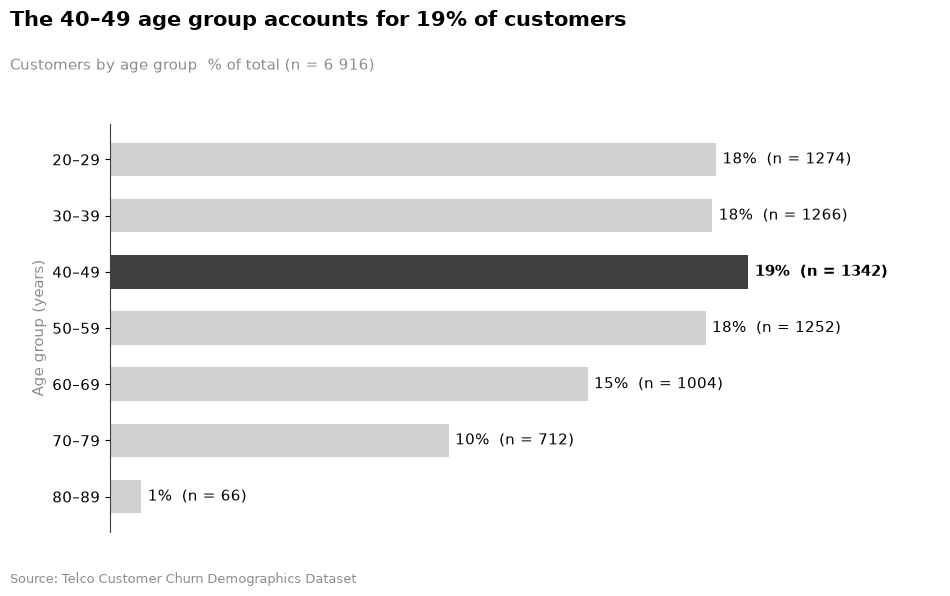

In [15]:
# Visualization: Customer Age Group Distribution

BLACK = "#000000"
GREEN = "#10E078"
LIGHT_GRAY = "#A6A6A6"
DARK_GRAY = "#8C8C8C"

fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(top=0.78, bottom=0.10, left=0.12, right=0.95)

# Invert Y positions to display the youngest cohort at the top

y = np.arange(len(labels))[::-1]

# IBCS accent: highlight the top demographic group in dark, others in light

colors = [DARK if l == top_label else LIGHT for l in labels]

# Horizontal bar plot
ax.barh(y, percentages.values, color=colors, height=0.6)

# Data labels: percentage and absolute count per cohort

for yi, v, c in zip(y, percentages.values, counts.values):
    ax.text(
        v + percentages.max() * 0.01,
        yi,
        f"{v:.0f}%  (n = {c})",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold" if v == top_pct else "normal",
    )

# Axis configuration and styling

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xticks([])
ax.set_xlim(0, percentages.max() * 1.3)
ax.set_ylabel("Age group (years)", color=MID)

# Apply IBCS minimal axis styling
clean_axes(ax, keep_left=True, keep_bottom=False)
ax.spines["left"].set_color(DARK)

# Set IBCS standard title and subtitle
ibcs_titles(fig, title, subtitle)

plt.show()

* **Young Adults:** What is the number and percentage of customers under 30 years old?

In [16]:
age_under_30_count = df_demographics[df_demographics["Under 30"] == "Yes"]

In [17]:
age_under_30 = pd.DataFrame(
    {
        "Frequency": age_under_30_count["Under 30"].value_counts(),
        "Percentage (%)": age_under_30_count.shape[0] / df_demographics.shape[0] * 100,
    }
)
age_under_30.head()

,Frequency,Percentage (%)
Under 30,,
Yes,1401,19.892091


* **Senior Citizens:** Is there a high proportion of senior citizens (customers aged 65 and over)?

In [18]:
seniors_count = df_demographics[df_demographics["Senior Citizen"] == "Yes"]

In [19]:
seniors = pd.DataFrame(
    {
        "Frequency": seniors_count["Senior Citizen"].value_counts(),
        "Percentage (%)": seniors_count.shape[0] / df_demographics.shape[0] * 100,
    }
)
seniors.head()

,Frequency,Percentage (%)
Senior Citizen,,
Yes,1142,16.214681


### Marital Status
 
* **Married Customers:** What is the number and percentage of customers classified as "married"? Is there a higher prevalence of married customers or otherwise?

In [20]:
married = pd.DataFrame(
    {
        "Frequency": df_demographics["Married"].value_counts(),
        "Percentage (%)": df_demographics["Married"].value_counts(normalize=True) * 100,
    }
)
married.head()

,Frequency,Percentage (%)
Married,,
No,3641,51.69672
Yes,3402,48.30328


### Household and Dependents
 
* **Presence of Children:** Is there a predominance of customers with children or not?
* **Family Size:** What is the average number of children among customers (considering only the subgroup with dependents)?

In [21]:
df_demographics["Dependents"].value_counts()

Dependents
No     5416
Yes    1627
Name: count, dtype: int64

In [22]:
df_demographics["Dependents"].value_counts(normalize=True) * 100

Dependents
No     76.899049
Yes    23.100951
Name: proportion, dtype: float64

In [23]:
# 1. Filter only clients with dependents (where dependents is True)
clients_with_dep = df_demographics[df_demographics["Dependents"] == "Yes"]

# 2. Calculate the mean of 'number of dependents' and round to 2 decimal places
avg_dependents = round(float(clients_with_dep["Number of Dependents"].mean()), 2)

print(f"Average number of children for clients with dependents: {avg_dependents}")

Average number of children for clients with dependents: 2.03


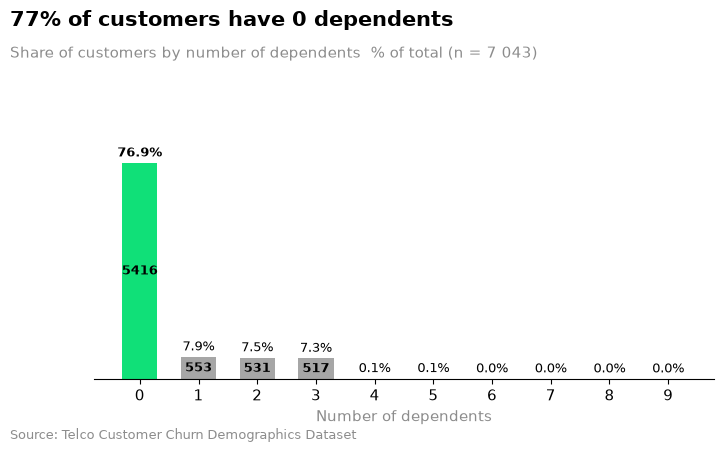

In [24]:

# Data prep

counts = df_demographics["Number of Dependents"].value_counts().sort_index()
total = len(df_demographics)
pcts = (counts / total) * 100

top_dep = counts.idxmax()
top_pct = pcts.max()

# Plot setup

fig, ax = plt.subplots(figsize=(8, 4.5))
fig.subplots_adjust(top=0.75, bottom=0.15)

title = f"{top_pct:.0f}% of customers have {top_dep} dependents"
subtitle = f"Share of customers by number of dependents, % of total (n = {total:,})".replace(",", " ")
ibcs_titles(fig, title, subtitle)

# Bars

colors = [GREEN if idx == top_dep else LIGHT_GRAY for idx in counts.index]
bars = ax.bar(counts.index.astype(str), pcts.values, color=colors, width=0.6)

# Labels

for bar, (idx, c) in zip(bars, counts.items()):
    h = bar.get_height()
    x = bar.get_x() + bar.get_width() / 2

    # Percentage label above bar
    ax.text(x, h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=9.5, color=BLACK,
            fontweight="bold" if idx == top_dep else "normal")

    # Raw count inside bar (uniform black bold text for all groups > 5%)
    if h > 5:
        ax.text(x, h / 2, str(c), ha="center", va="center", fontsize=9.5,
                color=BLACK, fontweight="bold")

# Styling

ax.set_yticks([])
ax.set_ylim(0, top_pct * 1.25)
ax.set_xlabel("Number of dependents", color=DARK_GRAY)
clean_axes(ax, keep_left=False, keep_bottom=True)
ax.spines["bottom"].set_color(BLACK)

plt.show()

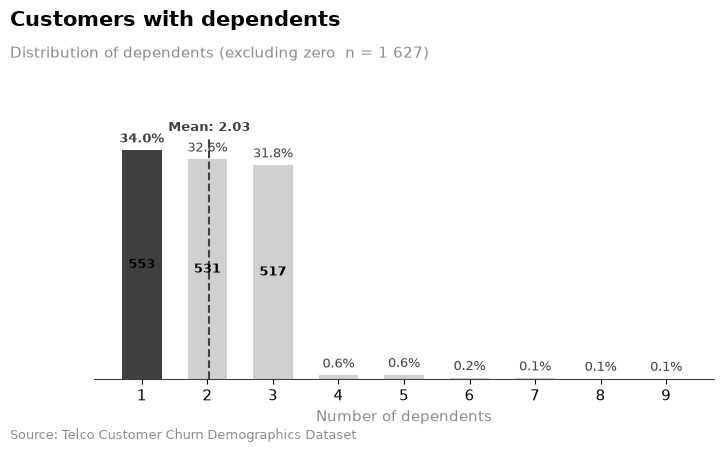

In [25]:
# Filter clients with at least one dependent
dep = df_demographics.loc[df_demographics["Number of Dependents"] > 0, "Number of Dependents"]
counts = dep.value_counts().sort_index()
avg_dep = dep.mean()
total_dep = len(dep)

# Figure & titles
fig, ax = plt.subplots(figsize=(8, 4.5))
fig.subplots_adjust(top=0.75, bottom=0.15)
ibcs_titles(
    fig, 
    "Customers with dependents",
    f"Distribution of dependents (excluding zero, n = {total_dep:,})".replace(",", " ")
)

# Bars: highlight top category
colors = [DARK if v == counts.max() else LIGHT for v in counts]
bars = ax.bar(counts.index.astype(str), counts.values, color=colors, width=0.6)

# Labels: percentage above the bar, count centered inside the bar (for groups > 5%)
for bar in bars:
    y = bar.get_height()
    x = bar.get_x() + bar.get_width() / 2
    pct = (y / total_dep) * 100

    # Percentage on top
    ax.text(
        x, y + counts.max() * 0.02, f"{pct:.1f}%", 
        ha="center", va="bottom", fontsize=9.5, 
        color=DARK, fontweight="bold" if y == counts.max() else "normal"
    )

    # Count centered inside the bar (only if > 5%)
    if pct > 5:
        ax.text(
            x, y / 2, str(y), 
            ha="center", va="center", fontsize=9.5, 
            color=BLACK, fontweight="bold"
        )

# Mean reference line capped at the top of the highest bar
mean_x = avg_dep - counts.index.min()
line_top = counts.max() * 1.05

ax.vlines(mean_x, ymin=0, ymax=line_top, color=DARK, ls="--", lw=1.5)
ax.text(
    mean_x, line_top + counts.max() * 0.02, f"Mean: {avg_dep:.2f}",
    ha="center", va="bottom", fontsize=9.5, color=DARK, fontweight="bold"
)

# Cleanup
ax.set_yticks([])
ax.set_ylim(0, counts.max() * 1.18)
ax.set_xlabel("Number of dependents", color=MID)
clean_axes(ax, keep_left=False, keep_bottom=True)
ax.spines["bottom"].set_color(DARK)

plt.show()

## Exploratory Analysis: Dataset Location & Population

The objective of the location analysis is to understand the geographic distribution of the company's customer base and identify the cities that contribute most to its customer portfolio.

### Expected outcome

These analyses will help distinguish between cities with the largest customer bases and cities where the company has the strongest relative presence. The results may support geographic market analysis and help identify areas where further commercial or retention strategies could be investigated.

In [26]:
df_location = pd.read_excel(location)
df_location.head()

,Customer ID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude
0,8779-QRDMV,1,United States,California,Los Angeles,90022,"34.02381, -118.156582",34.023810,-118.156582
1,7495-OOKFY,1,United States,California,Los Angeles,90063,"34.044271, -118.185237",34.044271,-118.185237
2,1658-BYGOY,1,United States,California,Los Angeles,90065,"34.108833, -118.229715",34.108833,-118.229715
3,4598-XLKNJ,1,United States,California,Inglewood,90303,"33.936291, -118.332639",33.936291,-118.332639
4,4846-WHAFZ,1,United States,California,Whittier,90602,"33.972119, -118.020188",33.972119,-118.020188


In [27]:
df_population = pd.read_excel(population)
df_population.head()

,ID,Zip Code,Population
0,1,90001,54492
1,2,90002,44586
2,3,90003,58198
3,4,90004,67852
4,5,90005,43019


In [28]:
# 2. Merge on Zip Code (the only column both files share)
# how="left": keep every customer, even if the ZIP has no population
# validate="m:1": many customers -> one ZIP row. Pandas raises an
# error if Zip Code is duplicated in the population file.
# the population file's "ID" is just a row number, so we drop it

df_merged = df_location.merge(
    df_population[["Zip Code", "Population"]],
    on="Zip Code",
    how="left",
    validate="m:1",
)

In [29]:
# 3. Sanity checks
print("Rows after merge:", len(df_merged))  # must equal 7043
print(
    "Customers without population:", df_merged["Population"].isna().sum()
)  # should be 0

Rows after merge: 7043
Customers without population: 0


### 1. Which cities have the highest number of customers?
**Research question:** Which cities have the largest number of Telco customers?

#This analysis will identify the cities with the highest customer representation by counting the number of customers in each city. It will help determine where the company's customer base is most concentrated and identify the geographic markets that contribute most to its overall customer portfolio.

**Key metric:** Number of customers per city.

In [30]:
# Count customers per city
customers_by_city = (
    df_merged.groupby("City")["Customer ID"]
    .count()  # one row per customer, so count = number of customers
    .rename("customers")
    .sort_values(ascending=False)  # biggest cities first
    .to_frame()
)

In [31]:
# Share of the total customer base (%) and cumulative share
# The cumulative column shows how concentrated the base is
total_customers = len(df_merged)
customers_by_city["share_pct"] = customers_by_city["customers"] / total_customers * 100
customers_by_city["cum_share_pct"] = customers_by_city["share_pct"].cumsum()
customers_by_city.head(10)

,customers,share_pct,cum_share_pct
City,,,
Los Angeles,293,4.160159,4.160159
San Diego,285,4.046571,8.206730
San Jose,112,1.590231,9.796962
Sacramento,108,1.533437,11.330399
San Francisco,104,1.476643,12.807042
Fresno,61,0.866108,13.673151
Long Beach,60,0.851910,14.525060
Oakland,52,0.738322,15.263382
Escondido,51,0.724123,15.987505


In [32]:
# Concentration metrics
print("Number of cities:", len(customers_by_city))
print("Top 5 cities share (%):", customers_by_city["share_pct"].head(5).sum().round(1))
print(
    "Top 10 cities share (%):", customers_by_city["share_pct"].head(10).sum().round(1)
)

Number of cities: 1106
Top 5 cities share (%): 12.8
Top 10 cities share (%): 16.6


In [33]:
# How many cities are needed to reach 50% of customers?
print(
    "Cities to reach 50% of base:", (customers_by_city["cum_share_pct"] <= 50).sum() + 1
)

Cities to reach 50% of base: 229


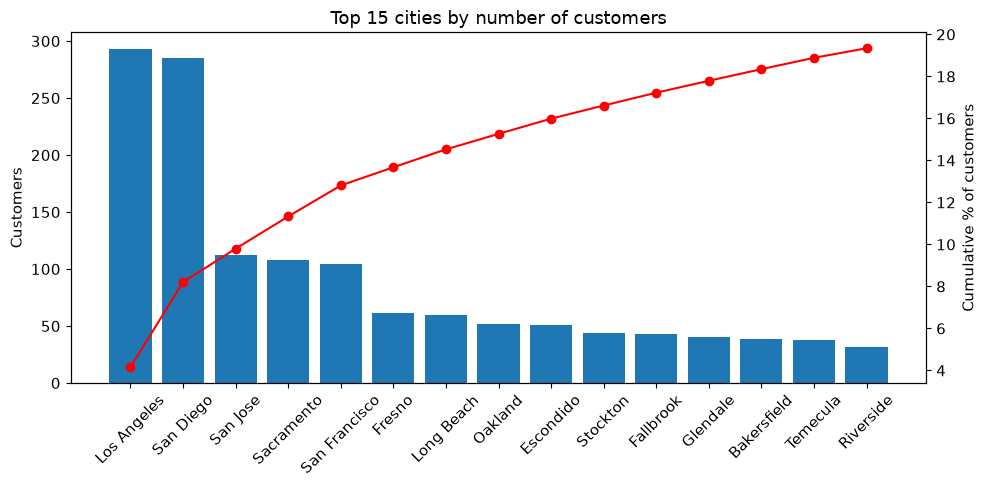

In [34]:
# Optional chart: Pareto of the top 15 cities (bars + cumulative line)
# ---------------------------------------------------------------

top = customers_by_city.head(15)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(top.index, top["customers"])  # bars: customers per city
ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=45)

ax2 = ax.twinx()  # second y-axis for the cumulative %
ax2.plot(top.index, top["cum_share_pct"], color="red", marker="o")
ax2.set_ylabel("Cumulative % of customers")

plt.title("Top 15 cities by number of customers")
plt.tight_layout()
plt.show()

# EDA: Dataset Services — Analysis Overview

Overview

This exploratory data analysis investigates how customer tenure, promotional offers, referral activity, and service adoption interact within the telecommunications service base. The objective is to identify key behavioral patterns and guide retention and marketing strategies.

In [35]:
df_services = pd.read_excel(services)
df_services.head()

,Customer ID,Count,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
0,8779-QRDMV,1,Q3,No,0,1,NaN,No,0.00,No,...,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65
1,7495-OOKFY,1,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,...,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10
2,1658-BYGOY,1,Q3,No,0,18,Offer D,Yes,11.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88
3,4598-XLKNJ,1,Q3,Yes,1,25,Offer C,Yes,19.76,No,...,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07
4,4846-WHAFZ,1,Q3,Yes,1,37,Offer C,Yes,6.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36


In [36]:
df_services.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Count                              7043 non-null   int64  
 2   Quarter                            7043 non-null   str    
 3   Referred a Friend                  7043 non-null   str    
 4   Number of Referrals                7043 non-null   int64  
 5   Tenure in Months                   7043 non-null   int64  
 6   Offer                              3166 non-null   str    
 7   Phone Service                      7043 non-null   str    
 8   Avg Monthly Long Distance Charges  7043 non-null   float64
 9   Multiple Lines                     7043 non-null   str    
 10  Internet Service                   7043 non-null   str    
 11  Internet Type                      5517 non-null   str    
 12  Avg

In [37]:
df_services["Contract"].value_counts(normalize=True) * 100

Contract
Month-to-Month    51.256567
Two Year          26.735766
One Year          22.007667
Name: proportion, dtype: float64

## Tenure in Months
**What it is:** The number of months a customer has been with the company, from 1 to 72.

## NOTA: pico dos 70 aos 72 poderão ser clientes fundadores da empresa, fazer referência quando falarmos do tenure.

In [38]:
t = df_services["Tenure in Months"]

print(t.describe().round(2))  # count, mean, std, min, quartiles, max
print("Skew:", round(t.skew(), 2))

count    7043.00
mean       32.39
std        24.54
min         1.00
25%         9.00
50%        29.00
75%        55.00
max        72.00
Name: Tenure in Months, dtype: float64
Skew: 0.24


In [39]:
BLUE, ORANGE = "#2E6F9E", "#D9822B"  # reusable colors

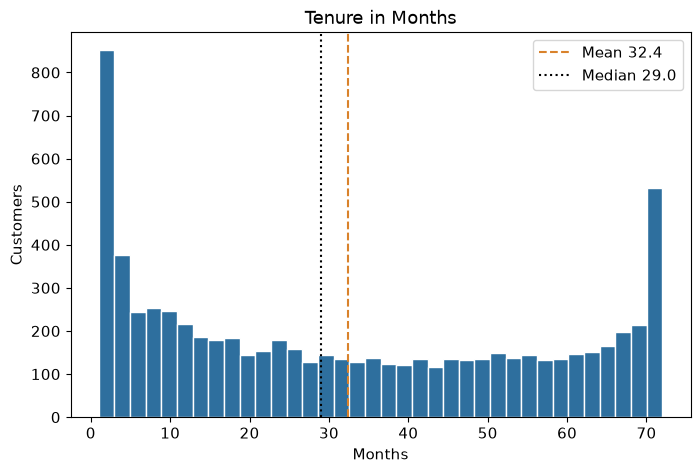

In [40]:
plt.figure(figsize=(8, 5))
plt.hist(t, bins=36, color=BLUE, edgecolor="white")
plt.axvline(t.mean(), color=ORANGE, ls="--", label=f"Mean {t.mean():.1f}")
plt.axvline(t.median(), color="k", ls=":", label=f"Median {t.median():.1f}")
plt.title("Tenure in Months")
plt.xlabel("Months")
plt.ylabel("Customers")
plt.legend()
plt.show()

**What we see:**
- Mean is 32.4 months and median is 29, so the center is fairly balanced.
- The shape is U-shaped, with spikes at 1 month (613 customers) and 72 months (362 customers).
- The base splits into two groups, new customers and long-term loyal ones, with fewer in between.

## 2. Number of Referrals

**What it is:** How many people a customer has referred to the company.

In [41]:
# number of referrals distribution
r = df_services["Number of Referrals"].value_counts().sort_index()
print(r)

Number of Referrals
0     3821
1     1086
2      236
3      255
4      236
5      264
6      221
7      248
8      213
9      238
10     223
11       2
Name: count, dtype: int64


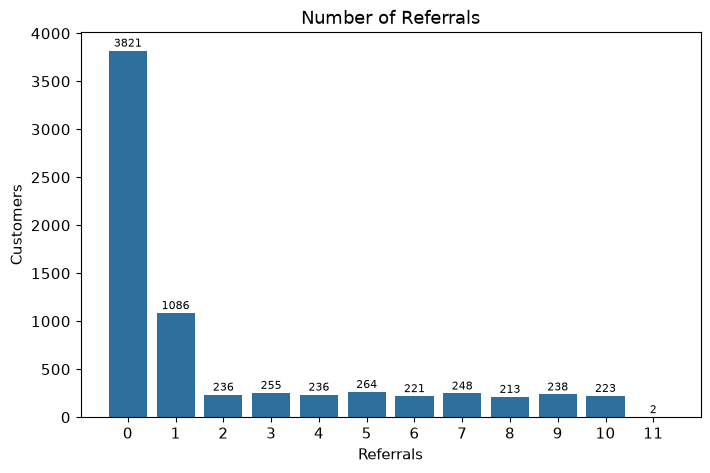

In [42]:
# Bar chart of number of referrals distribution
plt.figure(figsize=(8, 5))
plt.bar(r.index, r.values, color=BLUE)
for x, v in r.items():
    plt.text(x, v + 40, v, ha="center", fontsize=8)
plt.xticks(r.index)  # <-- show every referral number (0 to 11)
plt.title("Number of Referrals")
plt.xlabel("Referrals")
plt.ylabel("Customers")
plt.show()

**What we see:**
- It is heavily right-skewed. 54% of customers have 0 referrals and 15% have 1.
- From 2 to 10 referrals the counts are flat, at roughly 210 to 260 customers each.
- Most customers never refer anyone, and a smaller group refers actively.

## 3. Internet Type

**What it is:** The kind of internet connection a customer has: Fiber Optic, DSL or Cable. Customers with no internet service have this field blank, labelled here as "No Internet"

In [43]:
df_services["Internet Type"].value_counts().sort_index

<bound method Series.sort_index of Internet Type
Fiber Optic    3035
DSL            1652
Cable           830
Name: count, dtype: int64>

In [44]:
df_services["Internet Type"].isna().sum()

np.int64(1526)

In [45]:
it = df_services["Internet Type"].fillna("No Internet").value_counts()
print(it)

Internet Type
Fiber Optic    3035
DSL            1652
No Internet    1526
Cable           830
Name: count, dtype: int64


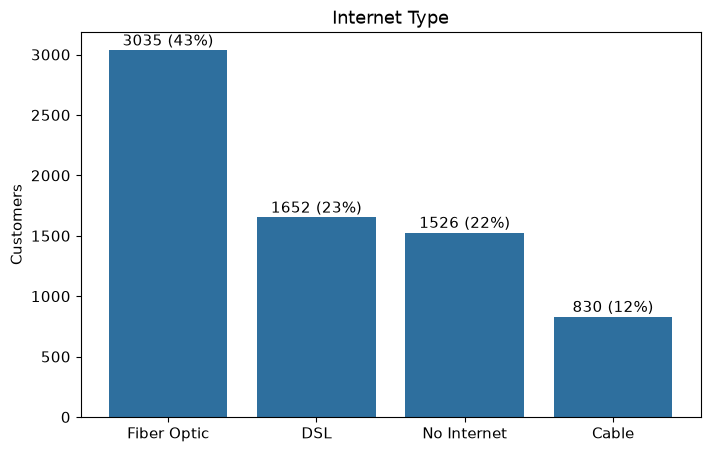

In [46]:
plt.figure(figsize=(8, 5))
plt.bar(it.index, it.values, color=BLUE)
for i, v in enumerate(it.values):
    plt.text(i, v + 40, f"{v} ({v/len(df_services):.0%})", ha="center")
plt.title("Internet Type")
plt.ylabel("Customers")
plt.show()

**What we see:**
- Fiber Optic is the largest group (43%), followed by DSL (23%) and Cable (12%).
- 22% of customers have no internet service at all.
- Fiber Optic leads by a wide margin, so any trend in the base is largely a Fiber Optic trend.

## 4. Monthly Charge

**What it is:** The amount a customer is billed each month.

In [47]:
m = df_services["Monthly Charge"]

In [48]:
m.describe().round(2)  # count, mean, std, min, quartiles, max

count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75
Name: Monthly Charge, dtype: float64

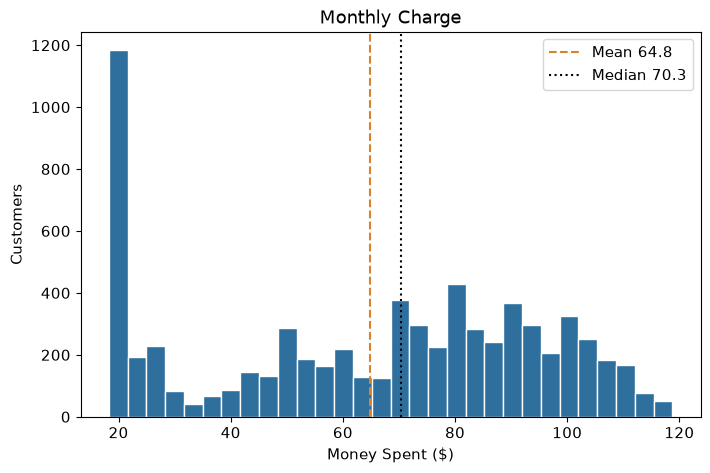

In [49]:
# a) Histogram
plt.figure(figsize=(8, 5))
plt.hist(m, bins=30, color=BLUE, edgecolor="white")
plt.axvline(m.mean(), color=ORANGE, ls="--", label=f"Mean {m.mean():.1f}")
plt.axvline(m.median(), color="k", ls=":", label=f"Median {m.median():.1f}")
plt.title("Monthly Charge")
plt.xlabel("Money Spent ($)")
plt.ylabel("Customers")
plt.legend()
plt.show()

## 5. Total Charges

**What it is:** The cumulative amount billed to a customer over their whole relationship.

In [50]:
c = df_services["Total Charges"]

In [51]:
c.describe().round(2)

count    7043.00
mean     2280.38
std      2266.22
min        18.80
25%       400.15
50%      1394.55
75%      3786.60
max      8684.80
Name: Total Charges, dtype: float64

In [55]:
# ---- Summary numbers ----
print("Skew:", round(c.skew(), 2))
print(f"Share of customers below the mean: {(c < c.mean()).mean():.0%}")

Skew: 0.96
Share of customers below the mean: 62%


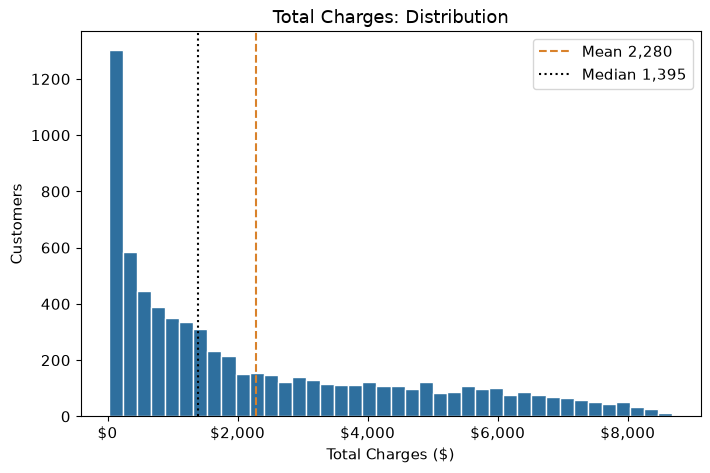

In [56]:
money = FuncFormatter(lambda x, _: f"${x:,.0f}")  # formats ticks as $2,000

plt.figure(figsize=(8, 5))
plt.hist(c, bins=40, color=BLUE, edgecolor="white")
plt.axvline(c.mean(), color=ORANGE, ls="--", label=f"Mean {c.mean():,.0f}")
plt.axvline(c.median(), color="k", ls=":", label=f"Median {c.median():,.0f}")
plt.gca().xaxis.set_major_formatter(money)
plt.title("Total Charges: Distribution")
plt.xlabel("Total Charges ($)")
plt.ylabel("Customers")
plt.legend()
plt.show()

In [57]:
# prepare the cumulative data
c_sorted = c.sort_values()  # smallest to largest (c stays untouched)
cum = np.arange(1, len(c_sorted) + 1) / len(
    c_sorted
)  # share of customers up to each value

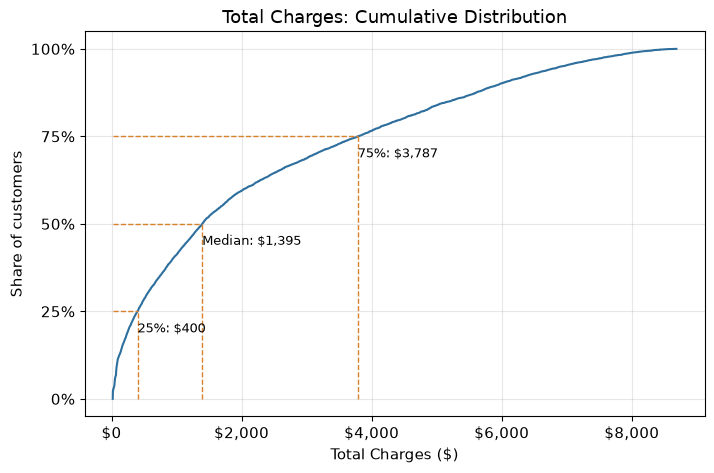

In [58]:
# cumulative line
plt.figure(figsize=(8, 5))
plt.plot(c_sorted, cum, color=BLUE)

for q, lbl in [(0.25, "25%"), (0.50, "Median"), (0.75, "75%")]:
    val = c.quantile(q)
    plt.hlines(q, c.min(), val, color=ORANGE, ls="--", lw=1)
    plt.vlines(val, 0, q, color=ORANGE, ls="--", lw=1)
    plt.text(val, q - 0.06, f"{lbl}: ${val:,.0f}", ha="left", fontsize=9)

plt.gca().xaxis.set_major_formatter(money)
plt.yticks(np.arange(0, 1.1, 0.25), ["0%", "25%", "50%", "75%", "100%"])
plt.title("Total Charges: Cumulative Distribution")
plt.xlabel("Total Charges ($)")
plt.ylabel("Share of customers")
plt.grid(alpha=0.3)
plt.show()

**Distribution**
- The histogram is right-skewed (skew 0.96): many customers have small totals, and a long tail stretches toward high values.
- The mean ($2,280) is well above the median ($1,395), so the tail pulls the mean upward. 62% of customers are below the mean.
- The standard deviation ($2,266) is almost as large as the mean, so the values are very spread out.

**Percentiles (cumulative line)**
- 25% of customers have paid less than $400, and half have paid less than $1,395.
- 75% of customers are below $3,787, so the top quarter is spread over a wide range, from $3,787 to $8,685.
- The curve is steepest at the start: 41% of customers have totals under $1,000. It flattens toward the end, where few customers reach high totals (only about 10% are above $6,000).

**Conclusion**


Total Charges is not a "typical value" variable. Most customers have accumulated low or moderate amounts, while a minority of high-value customers account for the upper tail. Because of this skew, the median describes a typical customer better than the mean, and any later analysis should keep in mind that the mean is inflated by the tail.

## 6. Total Revenue

**What it is:** The real money earned from each customer: Total Charges, minus refunds, plus extra data charges and long distance charges.

In [59]:
r = df_services["Total Revenue"]  # full column, never reassigned
money = FuncFormatter(lambda x, _: f"${x:,.0f}")  # formats ticks as $2,000

In [60]:
r.describe().round(2)

count     7043.00
mean      3034.38
std       2865.20
min         21.36
25%        605.61
50%       2108.64
75%       4801.15
max      11979.34
Name: Total Revenue, dtype: float64

In [61]:
print("Skew:", round(r.skew(), 2))
print(f"Share of customers below the mean: {(r < r.mean()).mean():.0%}")

Skew: 0.92
Share of customers below the mean: 61%


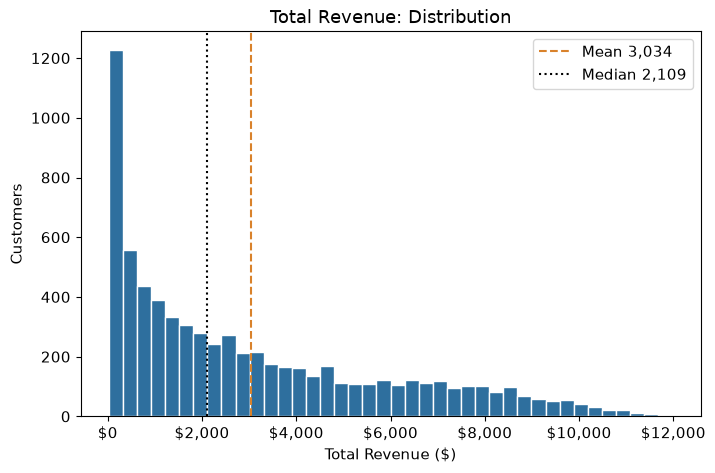

In [62]:
plt.figure(figsize=(8, 5))
plt.hist(r, bins=40, color=BLUE, edgecolor="white")
plt.axvline(r.mean(), color=ORANGE, ls="--", label=f"Mean {r.mean():,.0f}")
plt.axvline(r.median(), color="k", ls=":", label=f"Median {r.median():,.0f}")
plt.gca().xaxis.set_major_formatter(money)
plt.title("Total Revenue: Distribution")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Customers")
plt.legend()
plt.show()

In [63]:
r_sorted = r.sort_values(ascending=False)  # biggest customers first
cum_customers = np.arange(1, len(r_sorted) + 1) / len(
    r_sorted
)  # share of customers (x)
cum_revenue = r_sorted.cumsum() / r_sorted.sum()  # share of total revenue (y)

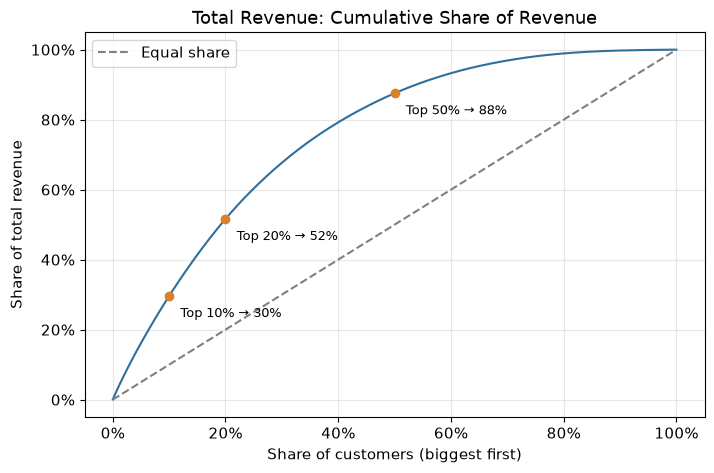

In [64]:
plt.figure(figsize=(8, 5))
plt.plot(cum_customers, cum_revenue, color=BLUE)
plt.plot([0, 1], [0, 1], color="gray", ls="--", label="Equal share")

for p in [0.1, 0.2, 0.5]:  # top 10%, 20% and 50% of customers
    y = cum_revenue.iloc[int(p * len(r_sorted)) - 1]
    plt.scatter(p, y, color=ORANGE, zorder=3)
    plt.text(p + 0.02, y - 0.06, f"Top {p:.0%} → {y:.0%}", fontsize=9)

ticks = np.arange(0, 1.1, 0.2)
labels = [f"{t:.0%}" for t in ticks]
plt.xticks(ticks, labels)
plt.yticks(ticks, labels)
plt.title("Total Revenue: Cumulative Share of Revenue")
plt.xlabel("Share of customers (biggest first)")
plt.ylabel("Share of total revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Distribution**
- The histogram is right-skewed (skew 0.92): many customers have low totals, and a long tail stretches toward high values.
- The mean ($3,034) is above the median ($2,109), so the tail pulls the mean upward. 61% of customers are below the mean.
- The standard deviation ($2,865) is close to the mean, so the values are very spread out.

**Percentiles**
- 25% of customers generate less than $606 and half generate less than $2,109.
- 75% are below $4,801, so the top quarter spreads from $4,801 up to $11,979.
- One third of customers (33%) generate under $1,000, while only about 8% generate more than $8,000.

**Concentration (cumulative curve)**
- Revenue is concentrated in a minority of customers: the top 10% bring in 30% of all revenue, the top 20% bring in 52%, and the top 50% bring in 87.5%.
- The bottom half of customers generates only 12.5% of revenue.

**Conclusion**
Total Revenue is unevenly distributed. Most customers contribute small or moderate amounts, while a minority of high-value customers account for a large part of the money earned. Because of the skew, the median describes a typical customer better than the mean, and the concentration curve shows that the business depends heavily on its top customers.

In [65]:
## NOTA: uma percentagem de churn um pouco mais reduzida porém com alto valor para a empresa, pode fazer com que a retenção recaia mais sobre os top customers

# Correlation between features in Services Dataset

## 1. Tenure in Months vs Total Charges and Total Revenue

**Question:** Do customers who stay longer accumulate more charges and more revenue?

In [66]:
corr = pd.DataFrame(
    {
        "Pearson": [t.corr(c), t.corr(r)],
        "Spearman": [t.corr(c, method="spearman"), t.corr(r, method="spearman")],
    },
    index=["Tenure vs Total Charges", "Tenure vs Total Revenue"],
).round(3)

corr["R²"] = (corr["Pearson"] ** 2).round(3)
corr

,Pearson,Spearman,R²
Tenure vs Total Charges,0.826,0.889,0.682
Tenure vs Total Revenue,0.853,0.913,0.728


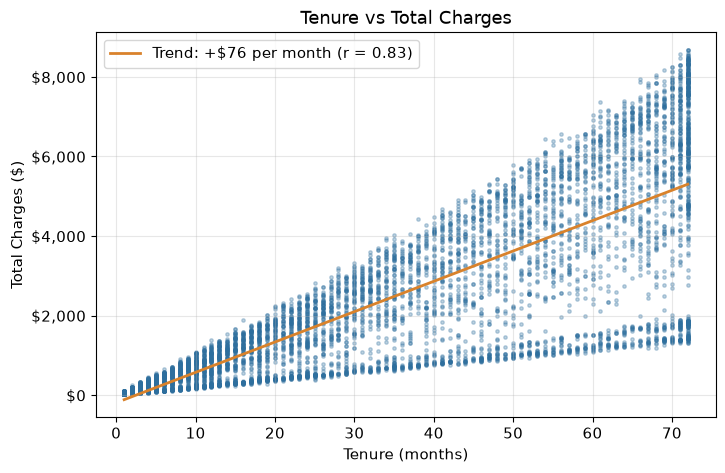

In [67]:
# Tenure vs Total Charges
m, b = np.polyfit(t, c, 1)  # straight-line fit: c = m*t + b
x = np.array([t.min(), t.max()])

plt.figure(figsize=(8, 5))
plt.scatter(t, c, s=6, alpha=0.3, color=BLUE)
plt.plot(
    x,
    m * x + b,
    color=ORANGE,
    lw=2,
    label=f"Trend: +${m:,.0f} per month (r = {t.corr(c):.2f})",
)
plt.gca().yaxis.set_major_formatter(money)
plt.title("Tenure vs Total Charges")
plt.xlabel("Tenure (months)")
plt.ylabel("Total Charges ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

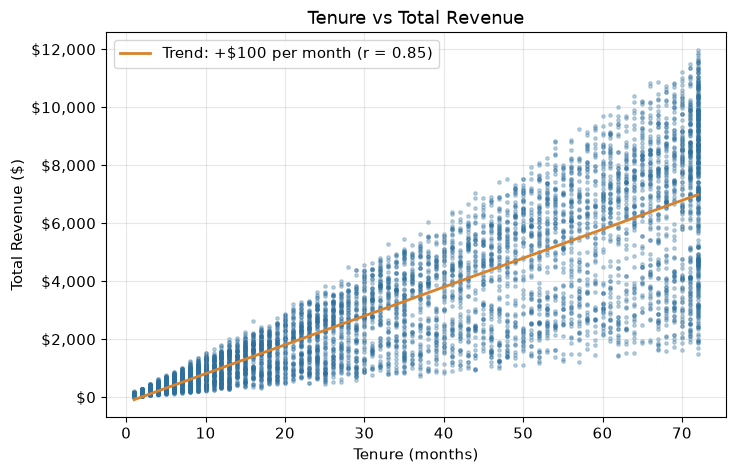

In [68]:
# Tenure vs Total Revenue
m, b = np.polyfit(t, r, 1)  # straight-line fit: r = m*t + b
x = np.array([t.min(), t.max()])

plt.figure(figsize=(8, 5))
plt.scatter(t, r, s=6, alpha=0.3, color=BLUE)
plt.plot(
    x,
    m * x + b,
    color=ORANGE,
    lw=2,
    label=f"Trend: +${m:,.0f} per month (r = {t.corr(r):.2f})",
)
plt.gca().yaxis.set_major_formatter(money)
plt.title("Tenure vs Total Revenue")
plt.xlabel("Tenure (months)")
plt.ylabel("Total Revenue ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [69]:
# averages by tenure bands
bands = pd.cut(t, [0, 12, 24, 48, 72], labels=["1–12", "13–24", "25–48", "49–72"])

pd.DataFrame({"Total Charges": c, "Total Revenue": r}).groupby(
    bands, observed=True
).agg(["mean", "std"]).round(0)

Total Charges         Total Revenue        
                          mean     std          mean     std
Tenure in Months                                            
1–12                     277.0   272.0         388.0   361.0
13–24                   1126.0   580.0        1560.0   701.0
25–48                   2390.0  1222.0        3206.0  1484.0
49–72                   4686.0  2132.0        6171.0  2493.0

**Tenure vs Total Charges**
- There is a strong positive relationship: each extra month adds about $76 to the total on average.
- Tenure explains 68% of the variation in Total Charges.
- Spearman (0.89) is higher than Pearson (0.83), so the relationship is consistently increasing but not a perfect straight line.
- The points form a fan that widens with tenure. In the first year the spread is small (std $272), but beyond 48 months it is much larger (std $2,132). A customer at 72 months can have anywhere from $1,305 to $8,685.

**Tenure vs Total Revenue**
- The relationship is slightly stronger: about $100 more per extra month, and tenure explains 73% of the variation.
- It has the same fan shape, with growing spread as tenure increases.

**Conclusion**
Tenure is the main driver of both totals, which is expected because both accumulate over time. The relationship is a little stronger with Total Revenue than with Total Charges. The spread that remains at any given tenure comes from customers paying different monthly amounts. This correlation does not show that keeping customers longer *causes* higher spending by itself: the totals are partly built from time by definition. Its value is in showing that tenure explains most, but not all, of the differences in customer value.

## 2. Referral Behaviour vs. Customer Tenure

Context: Assess whether advocacy grows over time or if customer referrals happen primarily during the initial onboarding window.

Approach: Evaluate the relationship between tenure length and referral volume (using correlation metrics such as Spearman's rank) and analyze referral propensity across tenure quartiles to pinpoint the optimal engagement window.

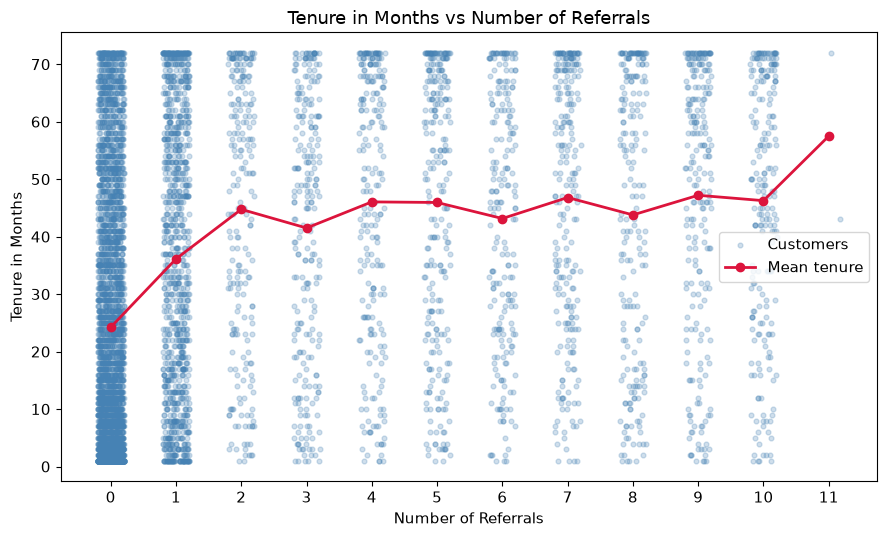

In [70]:
# Settings (change only here)
# ---------------------------------------------------------------
X_COL = "Number of Referrals"
Y_COL = "Tenure in Months"
JITTER = 0.2  # max horizontal shift of each point (visual only, data is not changed)
SEED = 42  # fixed seed so the plot looks the same every time

# ---------------------------------------------------------------
# Prepare the plot data
# ---------------------------------------------------------------
# Number of Referrals only takes whole values, so points would pile up on
# vertical lines. A small random horizontal shift (jitter) makes them visible.
rng = np.random.default_rng(SEED)
x_jittered = df_services[X_COL] + rng.uniform(-JITTER, JITTER, size=len(df_services))

# Mean tenure for each number of referrals, to make the trend easier to read
mean_by_x = df_services.groupby(X_COL)[Y_COL].mean()

# ---------------------------------------------------------------
# Scatterplot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    x_jittered,
    df_services[Y_COL],
    alpha=0.25,
    s=12,
    color="steelblue",
    label="Customers",
)
ax.plot(
    mean_by_x.index,
    mean_by_x.values,
    color="crimson",
    marker="o",
    linewidth=2,
    label="Mean tenure",
)

ax.set_xticks(range(int(df_services[X_COL].min()), int(df_services[X_COL].max()) + 1))
ax.set_xlabel(X_COL)
ax.set_ylabel(Y_COL)
ax.set_title(f"{Y_COL} vs {X_COL}")
ax.legend()

fig.tight_layout()
plt.show()

In [71]:
## porque optamos o tenure e o number of referrals como features escolhidas p treino do modelo

# 3. Internet Service Type & Distribution

Context: Identify the primary connectivity technology across the customer base to understand infrastructure reliance and upgrade potential.

Approach: Compute relative market shares (percentages) across internet service categories (e.g., Fiber Optic, DSL, None) using frequency tables and distribution plots to establish the core service profile.

Expected Outcomes

Identification of high-retention promotional offers.

Data-driven timing for referral and advocacy campaigns.

Baseline service distribution profile to benchmark upsell and cross-sell opportunities.

In [72]:
c = df_services["Monthly Charge"]
it = df_services["Internet Type"].fillna("No Internet")  # one value per customer

order = ["No Internet", "DSL", "Cable", "Fiber Optic"]  # lowest to highest average

print(len(c), len(it))  # both must be 7043

7043 7043


In [73]:
c.groupby(it).agg(["count", "mean", "median", "std", "min", "max"]).loc[order].round(1)

,count,mean,median,std,min,max
Internet Type,,,,,,
No Internet,1526,21.1,20.2,2.2,18.2,26.9
DSL,1652,58.2,56.2,16.3,23.4,94.8
Cable,830,60.3,59.0,17.9,24.2,113.0
Fiber Optic,3035,91.5,91.8,12.7,67.8,118.8


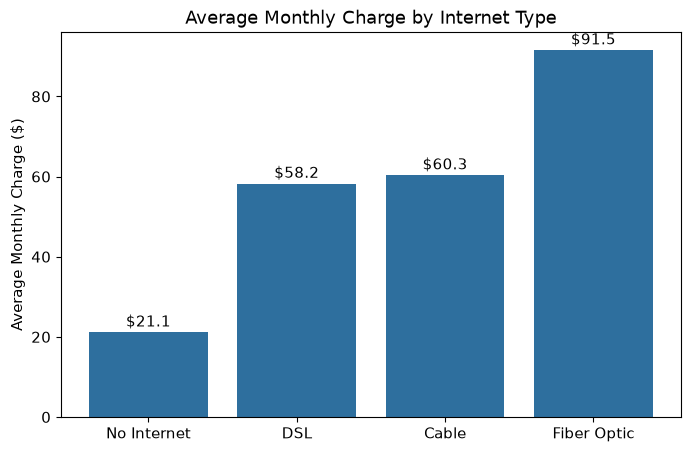

In [74]:
avg = c.groupby(it).mean().loc[order].round(1)

plt.figure(figsize=(8, 5))
plt.bar(avg.index, avg.values, color=BLUE)
for i, v in enumerate(avg.values):
    plt.text(i, v + 1.5, f"${v}", ha="center")
plt.title("Average Monthly Charge by Internet Type")
plt.ylabel("Average Monthly Charge ($)")
plt.show()

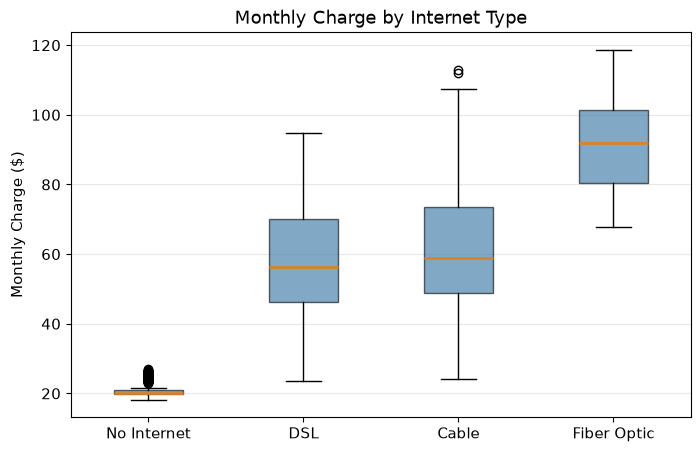

In [75]:
plt.figure(figsize=(8, 5))
plt.boxplot(
    [c[it == t] for t in order],
    tick_labels=order,
    patch_artist=True,
    boxprops=dict(facecolor=BLUE, alpha=0.6),
    medianprops=dict(color=ORANGE, lw=2),
)
plt.title("Monthly Charge by Internet Type")
plt.ylabel("Monthly Charge ($)")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [76]:
# how much internet type explains (η²)
group_means = c.groupby(it).transform("mean")
eta2 = ((group_means - c.mean()) ** 2).sum() / ((c - c.mean()) ** 2).sum()
print(f"Share of Monthly Charge variation explained by Internet Type: {eta2:.0%}")

Share of Monthly Charge variation explained by Internet Type: 81%


**Bar plot (averages)**
- Fiber Optic customers pay clearly the most: $91.5 on average, about 1.6 times the DSL average ($58.2).
- DSL and Cable are close ($58.2 and $60.3).
- Customers without internet pay about $21, which fits phone-only plans.

**Box plot (spread)**
- The groups barely overlap. The cheapest Fiber Optic customer ($67.8) pays more than about 70% of DSL and Cable customers.
- DSL and Cable overlap almost completely, so their small difference in averages is minor compared to the spread within each group.
- No Internet is the tightest group (std $2.2), because the plans are nearly identical. DSL and Cable vary the most (std about $16 to $18), probably because of different add-on services.
- Medians and means are almost equal in every group, so each distribution is roughly symmetric and the averages describe them well.

**Conclusion**
Internet type is the main driver of the monthly bill: it explains 81% of the variation in Monthly Charge. The pricing has three levels: phone-only (about $21), standard internet with DSL or Cable (about $60), and Fiber Optic as the premium tier (about $91). This also explains the two-peak shape seen in the Monthly Charge histogram.

# EDA: Dataset Status — Analysis Overview

**Explore churn patterns and their relationships with customer characteristics**

In [77]:
df_status = pd.read_excel(status)
df_status.head()

,Customer ID,Count,Quarter,Satisfaction Score,Customer Status,Churn Label,Churn Value,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,1,Q3,3,Churned,Yes,1,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,1,Q3,3,Churned,Yes,1,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,1,Q3,2,Churned,Yes,1,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,1,Q3,2,Churned,Yes,1,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,1,Q3,2,Churned,Yes,1,67,2793,Price,Extra data charges


In [78]:
df_status.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Customer ID         7043 non-null   str  
 1   Count               7043 non-null   int64
 2   Quarter             7043 non-null   str  
 3   Satisfaction Score  7043 non-null   int64
 4   Customer Status     7043 non-null   str  
 5   Churn Label         7043 non-null   str  
 6   Churn Value         7043 non-null   int64
 7   Churn Score         7043 non-null   int64
 8   CLTV                7043 non-null   int64
 9   Churn Category      1869 non-null   str  
 10  Churn Reason        1869 non-null   str  
dtypes: int64(5), str(6)
memory usage: 605.4 KB


## Missing values check

`Churn Category` and `Churn Reason` have 5,174 missing values (73.5%). Before treating this as a problem, let's check if it is expected.

In [79]:
df_status["Customer Status"].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [80]:
# Are the missing values tied to Customer Status?
print(pd.crosstab(df_status["Customer Status"], df_status["Churn Category"].isna()))

# Hard check: both fields are filled ONLY for churned customers
is_churned = df_status["Customer Status"] == "Churned"
assert (df_status["Churn Category"].notna() == is_churned).all()
print(
    "OK: Churn Category and Churn Reason are filled if and only if Customer Status == 'Churned'"
)

Churn Category   False  True 
Customer Status              
Churned           1869      0
Joined               0    454
Stayed               0   4720
OK: Churn Category and Churn Reason are filled if and only if Customer Status == 'Churned'


**What we see:**
- The missing values are **structural, not errors**: a customer who stayed or just joined has no reason for leaving.
- We will **not impute** them. `Churn Category` and `Churn Reason` are analysed using only the 1,869 churned customers.

## 1. Customer Status

**What it is:** Whether the customer `Stayed`, `Churned` or `Joined` (new customer in the quarter).

In [81]:
cs = df_status["Customer Status"]

In [82]:
cs_order = (
    cs.value_counts().index.tolist()
)  # sorted by number of customers (largest first)

cs_freq = pd.DataFrame(
    {
        "Frequency": cs.value_counts().reindex(cs_order),
        "Percentage (%)": cs.value_counts(normalize=True).reindex(cs_order) * 100,
    }
).round(2)
print(cs_freq)

                 Frequency  Percentage (%)
Customer Status                           
Stayed                4720           67.02
Churned               1869           26.54
Joined                 454            6.45


In [83]:
# Churn rate: churned / all customers, and churned / customers that existed without joined
print(f"Churn rate (all customers):        {(cs == 'Churned').mean():.1%}")
print(
    f"Churn rate (excluding 'Joined'):   {(cs == 'Churned').sum() / (cs != 'Joined').sum():.1%}"
)

Churn rate (all customers):        26.5%
Churn rate (excluding 'Joined'):   28.4%


**Notes:** So we will consider the Churn Rate of 28,4% for further analysis where will will conclude it's impact in terms of Churn Risk

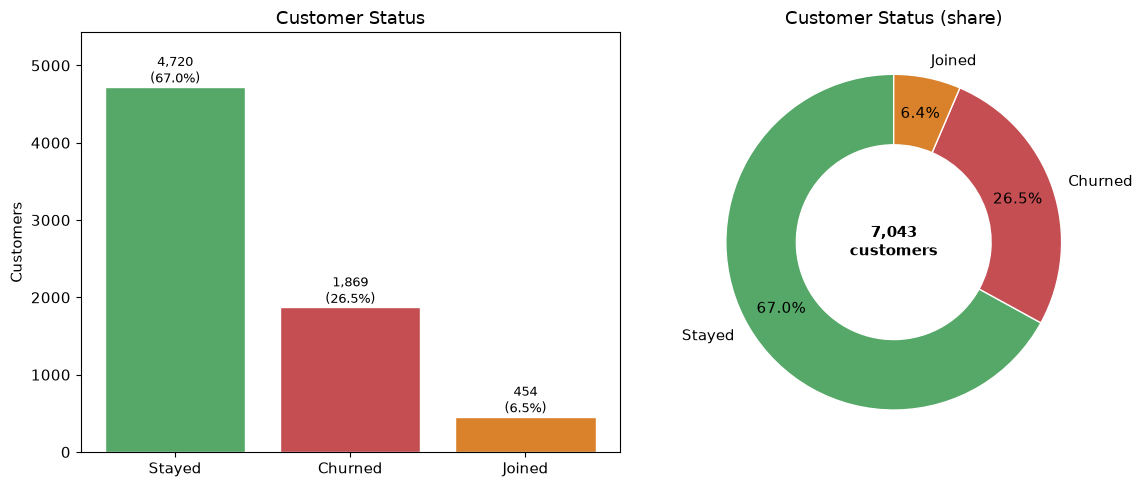

In [84]:
cs_colors = {"Stayed": "#55A868", "Joined": ORANGE, "Churned": "#C44E52"}
bar_colors = [cs_colors[k] for k in cs_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
axes[0].bar(cs_freq.index, cs_freq["Frequency"], color=bar_colors, edgecolor="white")
for i, (n, p) in enumerate(zip(cs_freq["Frequency"], cs_freq["Percentage (%)"])):
    axes[0].text(i, n + 60, f"{n:,}\n({p:.1f}%)", ha="center", fontsize=9)
axes[0].set_ylim(0, cs_freq["Frequency"].max() * 1.15)
axes[0].set_title("Customer Status")
axes[0].set_ylabel("Customers")
# Donut chart
axes[1].pie(
    cs_freq["Frequency"],
    labels=cs_freq.index,
    colors=bar_colors,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor="white"),
)
axes[1].text(
    0, 0, f"{len(cs):,}\ncustomers", ha="center", va="center", fontweight="bold"
)
axes[1].set_title("Customer Status (share)")

plt.tight_layout()
plt.show()

**What we see:**
- 67.0% of customers stayed, 26.5% churned and 6.4% are new.
- The churn rate rises to 28.4% if we leave out the `Joined` customers, who have not had time to churn yet.
- The classes are imbalanced (about 3 stayed for every 1 churned). If this becomes a target variable, accuracy alone would be misleading: use recall, F1 or AUC.

## 2. Satisfaction Score

**What it is:** The customer's satisfaction with the company, on an ordinal scale from 1 (very unhappy) to 5 (very happy).

In [85]:
sat = df_status["Satisfaction Score"]
sat.describe().round(2)

count    7043.00
mean        3.24
std         1.20
min         1.00
25%         3.00
50%         3.00
75%         4.00
max         5.00
Name: Satisfaction Score, dtype: float64

In [86]:
sat_freq = pd.DataFrame(
    {
        "Frequency": sat.value_counts().sort_index(),
        "Percentage (%)": sat.value_counts(normalize=True).sort_index() * 100,
    }
).round(2)
print(sat_freq)

print(
    f"Mean: {sat.mean():.2f} | Median: {sat.median():.0f} | Mode: {sat.mode()[0]} | Std: {sat.std():.2f}"
)

                    Frequency  Percentage (%)
Satisfaction Score                           
1                         922           13.09
2                         518            7.35
3                        2665           37.84
4                        1789           25.40
5                        1149           16.31
Mean: 3.24 | Median: 3 | Mode: 3 | Std: 1.20


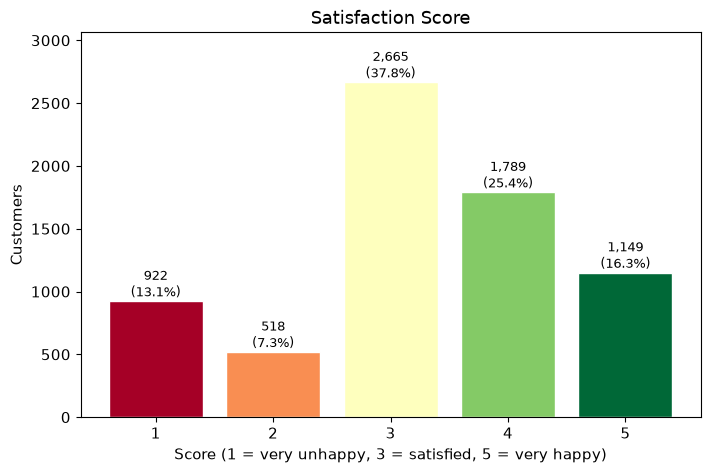

In [87]:
sat_colors = plt.cm.RdYlGn(np.linspace(0, 1, 5))  # red (unhappy) -> green (happy)

plt.figure(figsize=(8, 5))
plt.bar(
    sat_freq.index.astype(str),
    sat_freq["Frequency"],
    color=sat_colors,
    edgecolor="white",
)
for i, (n, p) in enumerate(zip(sat_freq["Frequency"], sat_freq["Percentage (%)"])):
    plt.text(i, n + 40, f"{n:,}\n({p:.1f}%)", ha="center", fontsize=9)
plt.ylim(0, sat_freq["Frequency"].max() * 1.15)  # room for the labels
plt.title("Satisfaction Score")
plt.xlabel("Score (1 = very unhappy, 3 = satisfied, 5 = very happy)")
plt.ylabel("Customers")
plt.show()

In [88]:
sat_bands = pd.cut(
    sat, bins=[0, 2, 3, 5], labels=["Low (1-2)", "Neutral (3)", "High (4-5)"]
)
pd.DataFrame(
    {
        "Frequency": sat_bands.value_counts().sort_index(),
        "Percentage (%)": (
            sat_bands.value_counts(normalize=True).sort_index() * 100
        ).round(2),
    }
)

,Frequency,Percentage (%)
Satisfaction Score,,
Low (1-2),1440,20.45
Neutral (3),2665,37.84
High (4-5),2938,41.72


**What we see:**
- Score 3 is the most common (37.8%), and the mean is 3.24, so the center is slightly on the positive side.
- 41.7% of customers score 4 or 5, against 20.4% who score 1 or 2: the base leans positive.
- There is still a visible group of unhappy customers: score 1 (13.1%) is almost twice as common as score 2 (7.4%).

## 3. Churn Category

**What it is:** The broad group of reasons why a customer left. Only exists for churned customers (n = 1,869).

In [89]:
# Only churned customers have a category (see the missing values check above)
churned = df_status[df_status["Customer Status"] == "Churned"]
ccat = churned["Churn Category"]

In [90]:
ccat_freq = pd.DataFrame(
    {
        "Frequency": ccat.value_counts(),
    }
)
print(f"Churned customers analysed: {len(ccat):,}")
print(ccat_freq)

Churned customers analysed: 1,869
                 Frequency
Churn Category            
Competitor             841
Attitude               314
Dissatisfaction        303
Price                  211
Other                  200


In [91]:
# One fixed colour per category (reused later in the Churn Reason chart)
CAT_COLORS = {
    "Competitor": "#C44E52",
    "Attitude": ORANGE,
    "Dissatisfaction": "#8172B3",
    "Price": BLUE,
    "Other": "#8C8C8C",
}

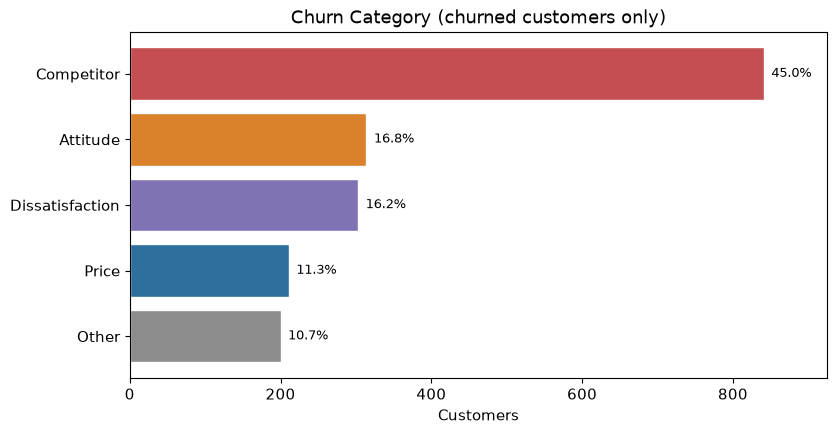

In [92]:
total = ccat_freq["Frequency"].sum()  # 1,869 churned customers

plt.figure(figsize=(9, 4.5))
plt.barh(
    ccat_freq.index,
    ccat_freq["Frequency"],
    color=[CAT_COLORS[k] for k in ccat_freq.index],
    edgecolor="white",
)
plt.gca().invert_yaxis()  # largest on top
for i, n in enumerate(ccat_freq["Frequency"]):
    plt.text(n + 10, i, f"{n / total:.1%}", va="center", fontsize=9)  # percentage only
plt.xlim(0, ccat_freq["Frequency"].max() * 1.1)
plt.title("Churn Category (churned customers only)")
plt.xlabel("Customers")
plt.show()

**What we see:**
- Competitor is by far the main reason: 45.0% of churned customers left for a competitor.
- Attitude (16.8%) and Dissatisfaction (16.2%) together explain about one third of churn. Both relate to service experience, so they are controllable.
- Price explains only 11.3%, so it is not the main driver of churn.

## 4. Churn Score

**What it is:** The predicted likelihood of a customer churning, from 0 to 100 (higher = higher risk). It comes from the IBM SPSS Modeler.

In [93]:
cscore = df_status["Churn Score"]

In [94]:
cscore.describe().round(2)

count    7043.00
mean       58.51
std        21.17
min         5.00
25%        40.00
50%        61.00
75%        75.50
max        96.00
Name: Churn Score, dtype: float64

In [95]:
print("Skew:", round(cscore.skew(), 2))
print("Kurtoss:", round(cscore.kurtosis(), 2))

Skew: -0.16
Kurtoss: -1.09


In [96]:
# Outliers with the IQR rule: outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
q1, q3 = cscore.quantile([0.25, 0.75])
iqr = q3 - q1
n_out = ((cscore < q1 - 1.5 * iqr) | (cscore > q3 + 1.5 * iqr)).sum()
print("IQR outliers:", n_out)

IQR outliers: 0


In [97]:
# Counts of the lowest scores: shows the gap between 9 and 20
print(cscore.value_counts().sort_index().head(10))

# Customers isolated from the bulk of the distribution
low_isolated = df_status[cscore < 20]
print(
    f"{len(low_isolated)} customers ({len(low_isolated) / len(df_status):.2%}) with Churn Score < 20"
)
print(low_isolated["Customer Status"].value_counts())

Churn Score
5      1
7      2
8      2
9      3
20    83
21    84
22    82
23    78
24    86
25    85
Name: count, dtype: int64
8 customers (0.11%) with Churn Score < 20
Customer Status
Stayed    8
Name: count, dtype: int64


The IQR rule flags **no outliers**, but this is a limitation of the rule: Churn Score is bounded between 0 and 100 and the lower fence (-13.25) is below the minimum possible value, so nothing can be flagged.
- Even so, there are **8 isolated customers (0.11%) with scores between 5 and 9**, separated from the rest by an empty gap (no customers with scores 10-19; from 20 onwards each score has about 80-100 customers). All 8 are `Stayed`.
- They look like genuine model predictions (very low risk) and not data errors, so they are kept.

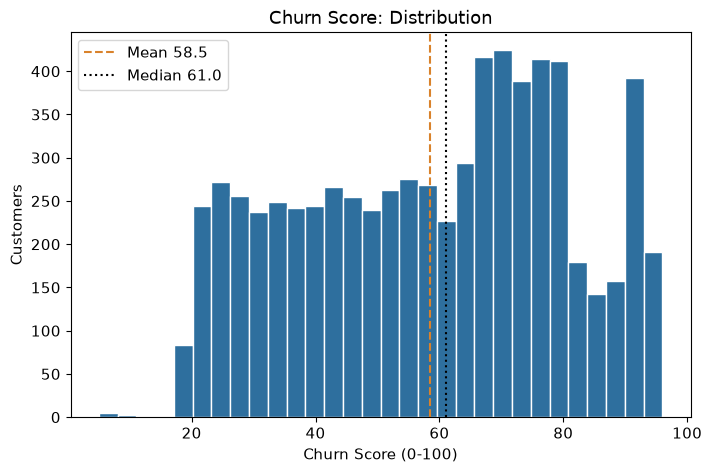

In [98]:
plt.figure(figsize=(8, 5))
plt.hist(cscore, bins=30, color=BLUE, edgecolor="white")
plt.axvline(cscore.mean(), color=ORANGE, ls="--", label=f"Mean {cscore.mean():.1f}")
plt.axvline(cscore.median(), color="k", ls=":", label=f"Median {cscore.median():.1f}")
plt.title("Churn Score: Distribution")
plt.xlabel("Churn Score (0-100)")
plt.ylabel("Customers")
plt.legend()
plt.show()

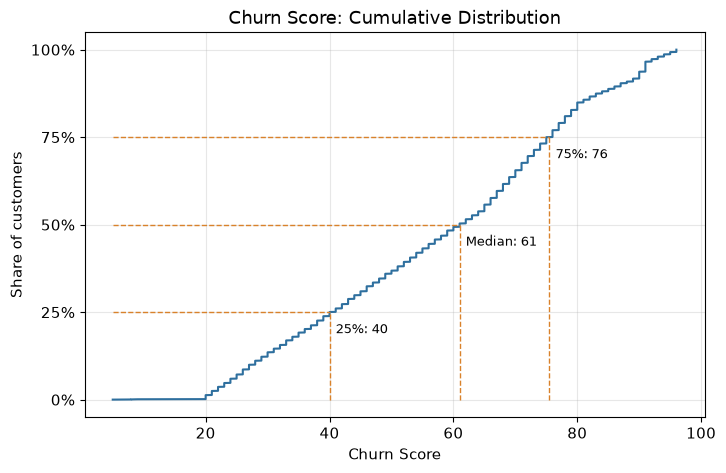

In [99]:
cs_sorted = cscore.sort_values()  # smallest to largest
cs_cum = np.arange(1, len(cs_sorted) + 1) / len(
    cs_sorted
)  # share of customers up to each value

plt.figure(figsize=(8, 5))
plt.plot(cs_sorted, cs_cum, color=BLUE)

for q, lbl in [(0.25, "25%"), (0.50, "Median"), (0.75, "75%")]:
    val = cscore.quantile(q)
    plt.hlines(q, cscore.min(), val, color=ORANGE, ls="--", lw=1)
    plt.vlines(val, 0, q, color=ORANGE, ls="--", lw=1)
    plt.text(val + 1, q - 0.06, f"{lbl}: {val:.0f}", fontsize=9)

plt.yticks(np.arange(0, 1.1, 0.25), ["0%", "25%", "50%", "75%", "100%"])
plt.title("Churn Score: Cumulative Distribution")
plt.xlabel("Churn Score")
plt.ylabel("Share of customers")
plt.grid(alpha=0.3)
plt.show()

                Frequency  Percentage (%)
Churn Score                              
Low (0-39)           1679           23.84
Medium (40-69)       2799           39.74
High (70-100)        2565           36.42


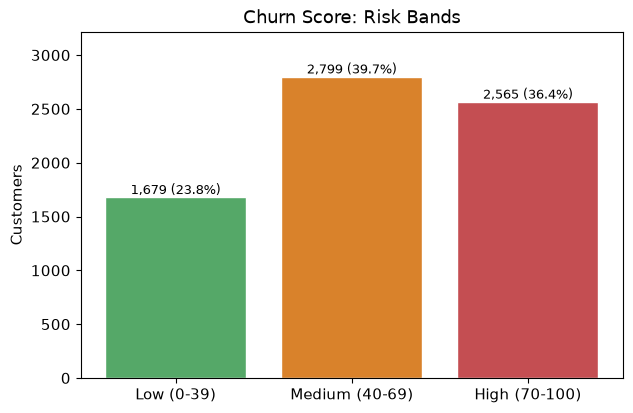

In [100]:
# Illustrative cut-offs (assumption): change them to fit your business rules
risk_bands = pd.cut(
    cscore,
    bins=[0, 39, 69, 100],
    labels=["Low (0-39)", "Medium (40-69)", "High (70-100)"],
    include_lowest=True,
)

risk_freq = pd.DataFrame(
    {
        "Frequency": risk_bands.value_counts().sort_index(),
        "Percentage (%)": (
            risk_bands.value_counts(normalize=True).sort_index() * 100
        ).round(2),
    }
)
print(risk_freq)

plt.figure(figsize=(7, 4.5))
plt.bar(
    risk_freq.index,
    risk_freq["Frequency"],
    color=["#55A868", ORANGE, "#C44E52"],
    edgecolor="white",
)
for i, (n, p) in enumerate(zip(risk_freq["Frequency"], risk_freq["Percentage (%)"])):
    plt.text(i, n + 30, f"{n:,} ({p:.1f}%)", ha="center", fontsize=9)
plt.ylim(0, risk_freq["Frequency"].max() * 1.15)
plt.title("Churn Score: Risk Bands")
plt.ylabel("Customers")
plt.show()

**What we see:**
- Scores go from 5 to 96. The mean (58.5) is a bit below the median (61), so the distribution is almost symmetric with a slight skew to the left (skew -0.16).
- The values are very spread out (std 21.2) and the shape is flat-topped (kurtosis -1.09), so the score separates customers well instead of clustering around one value.
- Half of the customers are between 40 (25%) and 75.5 (75%).
- With the illustrative bands, 36.4% of customers are in the high-risk zone (70-100) and 23.8% in the low-risk zone (0-39).

# Correlation between features in different Datasets

In [101]:
TELCO = (
    df_demographics.merge(
        df_location,
        on="Customer ID",
        how="inner",
        validate="1:1",
        suffixes=("", "_loc"),
    )
    .merge(
        df_services,
        on="Customer ID",
        how="inner",
        validate="1:1",
        suffixes=("", "_srv"),
    )
    .merge(
        df_status, on="Customer ID", how="inner", validate="1:1", suffixes=("", "_sts")
    )
    .merge(df_population.drop(columns="ID"), on="Zip Code", how="left", validate="m:1")
)

In [102]:
assert len(TELCO) == 7043 and TELCO["Customer ID"].is_unique
print("Shape:", TELCO.shape)
print(TELCO["Customer Status"].value_counts())

Shape: (7043, 57)
Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64


#### Resultado obtido — junção dos ficheiros

- Nenhum dos ficheiros tem `Customer ID` duplicados (nem ZIP codes duplicados em Population), por isso os *merges* 1:1 e m:1 são seguros e não multiplicam linhas.
- Depois da junção ficamos com **7 043 clientes e 57 colunas**, e nenhum cliente ficou sem dados de Population (0 valores em falta após o *left join*).
- `Customer Status`: **4 720 Stayed**, **1 869 Churned** e **454 Joined**. Os 454 *Joined* ficam fora da modelação (não fazem parte da população elegível definida no guia do projeto), pelo que trabalhamos com **6 589 clientes**.

## 1. Correlation between Dependents e a sua relação com total revenue. 
Espera-se talvez um maior revenue por parte destas famílias.

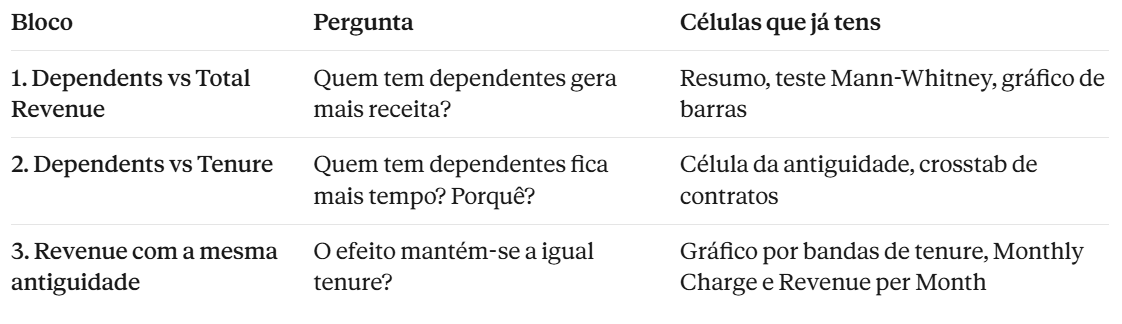

## Block 1. Dependents vs Total Revenue

Do customers with dependents generate more revenue for the company?

In [103]:
# --- 1. Summary table ---
order = ["No", "Yes"]
summary = (
    TELCO.groupby("Dependents")["Total Revenue"]
    .agg(["count", "mean", "median", "std"])
    .loc[order]
    .round(0)
)
print(summary)

            count    mean  median     std
Dependents                               
No           5416  2957.0  1998.0  2853.0
Yes          1627  3293.0  2435.0  2890.0


In [104]:
# --- 2. Statistical test (non-parametric because of the skew) ---
rev_yes = TELCO.loc[TELCO["Dependents"] == "Yes", "Total Revenue"]
rev_no = TELCO.loc[TELCO["Dependents"] == "No", "Total Revenue"]

# Revenue Cell
u, p = stats.mannwhitneyu(rev_yes, rev_no, alternative="two-sided")
rank_biserial = 2 * u / (len(rev_yes) * len(rev_no)) - 1  # effect size, -1 to 1
print(
    f" [Total Revenue] Mann-Whitney p-value: {p:.4g} | rank-biserial effect size: {rank_biserial:.3f}"
)

 [Total Revenue] Mann-Whitney p-value: 1.417e-08 | rank-biserial effect size: 0.093


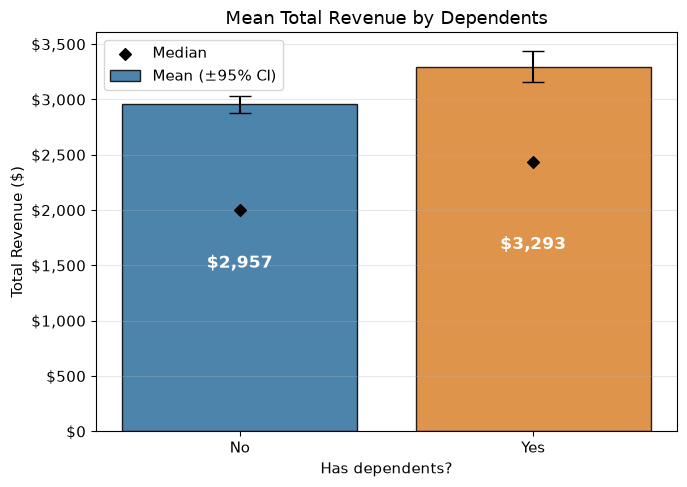

In [105]:
order = ["No", "Yes"]
g = TELCO.groupby("Dependents")["Total Revenue"]
means = g.mean().loc[order]
medians = g.median().loc[order]
ci95 = (g.sem() * 1.96).loc[order]  # 95% confidence interval (normal approx.)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    order,
    means,
    yerr=ci95,
    capsize=8,
    color=[BLUE, ORANGE],
    edgecolor="black",
    alpha=0.85,
    label="Mean (±95% CI)",
)
ax.scatter(order, medians, color="k", marker="D", zorder=3, label="Median")

for bar, m in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        m * 0.5,
        f"${m:,.0f}",
        ha="center",
        color="white",
        fontweight="bold",
        fontsize=12,
    )

ax.yaxis.set_major_formatter(money)
ax.set_title("Mean Total Revenue by Dependents")
ax.set_xlabel("Has dependents?")
ax.set_ylabel("Total Revenue ($)")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

Customers with dependents generate more revenue overall (mean $3,293 vs $2,957, +11%). The difference is statistically significant (Mann-Whitney p < 0.001) but small (rank-biserial r = 0.09). This gap may come from how long they stay rather than from higher spending, which is analysed in the next blocks.

## Block 2. Dependents vs Tenure in Months

The clients who have dependents are more time connected to the company that does don't have? And why?

In [106]:
ten_yes = TELCO.loc[TELCO["Dependents"] == "Yes", "Tenure in Months"]
ten_no = TELCO.loc[TELCO["Dependents"] == "No", "Tenure in Months"]

# --- Summary ---
print(
    TELCO.groupby("Dependents")["Tenure in Months"]
    .agg(["count", "mean", "median", "std"])
    .loc[order]
    .round(1)
)

# --- Statistical test (non-parametric, same approach as for Total Revenue) ---
u, p = stats.mannwhitneyu(ten_yes, ten_no, alternative="two-sided")
rb = 2 * u / (len(ten_yes) * len(ten_no)) - 1
diff = ten_yes.mean() - ten_no.mean()

print(f"\n [Tenure in Months] Mann-Whitney p-value: {p:.4g} | rank-biserial: {rb:.3f}")
print(f"Mean difference (Yes - No): {diff:+.1f} months")

            count  mean  median   std
Dependents                           
No           5416  30.6    26.0  24.4
Yes          1627  38.3    39.0  24.1

 [Tenure in Months] Mann-Whitney p-value: 4.454e-31 | rank-biserial: 0.189
Mean difference (Yes - No): +7.7 months


In [107]:
# Contract type by Dependents (row %)
print(
    pd.crosstab(TELCO["Dependents"], TELCO["Contract"], normalize="index").round(3)
    * 100
)

# Does the tenure gap persist within each contract type?
print(
    TELCO.groupby(["Contract", "Dependents"])["Tenure in Months"]
    .agg(["count", "mean"])
    .round(1)
    .unstack("Dependents")
)

Contract    Month-to-Month  One Year  Two Year
Dependents                                    
No                    55.4      21.8      22.8
Yes                   37.6      22.6      39.9
               count       mean      
Dependents        No  Yes    No   Yes
Contract                             
Month-to-Month  2999  611  16.8  20.2
One Year        1183  367  40.9  42.4
Two Year        1234  649  54.4  53.1


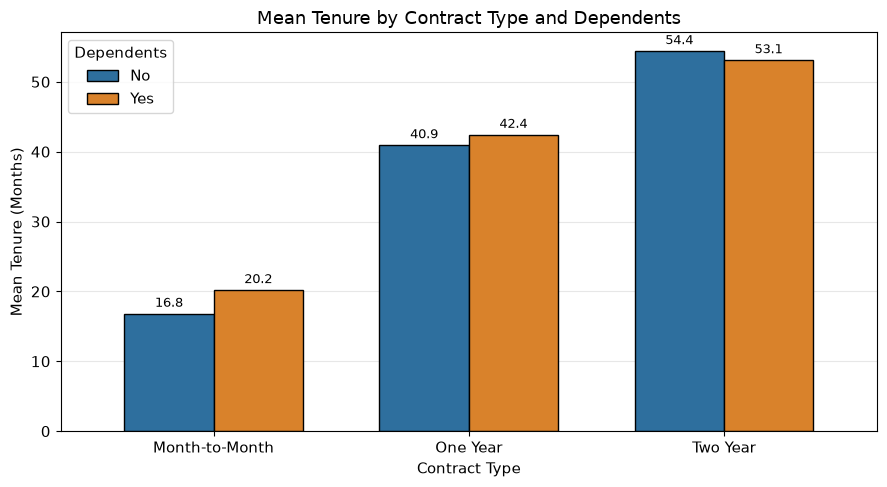

In [108]:
# Get contract types
contracts = df_services["Contract"].unique().tolist()

# Mean tenure by contract and Dependents
tenure = TELCO.pivot_table(
    index="Contract", columns="Dependents", values="Tenure in Months", aggfunc="mean"
).loc[contracts, order]

# Create a single plot
fig, ax = plt.subplots(figsize=(9, 5))

# Plot grouped bars
tenure.plot(kind="bar", ax=ax, color=[BLUE, ORANGE], edgecolor="black", width=0.7)

# Add data labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)

# Graph formatting
ax.set_title("Mean Tenure by Contract Type and Dependents", fontsize=13)
ax.set_xlabel("Contract Type")
ax.set_ylabel("Mean Tenure (Months)")

# Keep contract labels horizontal
ax.tick_params(axis="x", rotation=0)

ax.legend(title="Dependents")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Block 3. Revenue with the same Tenure

The effect remains the same?

            count         mean        
Dependents     No  Yes      No     Yes
Tenure Band                           
1–12         1838  348   387.0   391.0
13–24         789  235  1614.0  1379.0
25–48        1205  389  3345.0  2775.0
49–72        1584  655  6311.0  5831.0


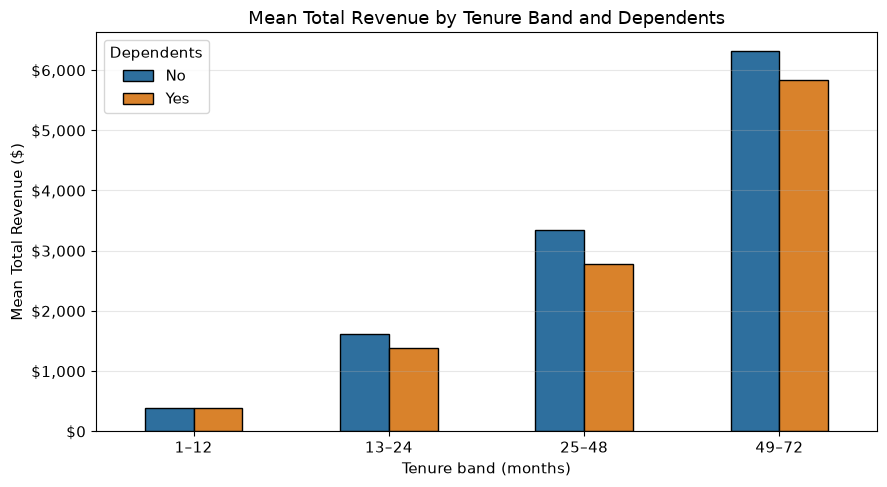

In [109]:
TELCO["Tenure Band"] = pd.cut(
    TELCO["Tenure in Months"],
    [0, 12, 24, 48, 72],
    labels=["1–12", "13–24", "25–48", "49–72"],
)

# Mean Total Revenue by band x Dependents
by_band = (
    TELCO.groupby(["Tenure Band", "Dependents"], observed=True)["Total Revenue"]
    .agg(["count", "mean"])
    .round(0)
    .unstack("Dependents")
)
print(by_band)

# Grouped bar chart: same tenure, with vs without dependents
pivot = TELCO.pivot_table(
    index="Tenure Band",
    columns="Dependents",
    values="Total Revenue",
    aggfunc="mean",
    observed=True,
)[order]
ax = pivot.plot(kind="bar", color=[BLUE, ORANGE], edgecolor="black", figsize=(9, 5))
ax.yaxis.set_major_formatter(money)
ax.set_title("Mean Total Revenue by Tenure Band and Dependents")
ax.set_xlabel("Tenure band (months)")
ax.set_ylabel("Mean Total Revenue ($)")
plt.xticks(rotation=0)
ax.grid(alpha=0.3, axis="y")
ax.legend(title="Dependents")
plt.tight_layout()
plt.show()

In [110]:
# Monthly revenue comparison
print(
    TELCO.groupby("Dependents")["Total Revenue"]
    .agg(["mean", "median"])
    .loc[order]
    .round(1)
)

              mean  median
Dependents                
No          2956.5  1997.9
Yes         3293.5  2435.2


In [111]:
TELCO["Revenue per Month"] = TELCO["Total Revenue"] / TELCO["Tenure in Months"]

print(
    TELCO.groupby("Dependents")[["Monthly Charge", "Revenue per Month"]]
    .agg(["mean", "median"])
    .round(1)
)

           Monthly Charge        Revenue per Month       
                     mean median              mean median
Dependents                                               
No                   67.1   73.9              90.6   96.4
Yes                  56.8   55.3              79.8   76.0


In [112]:
# Offers received by Dependents (row %)
print(
    pd.crosstab(TELCO["Dependents"], TELCO["Offer"], normalize="index").round(3) * 100
)

Offer       Offer A  Offer B  Offer C  Offer D  Offer E
Dependents                                             
No             14.9     25.0     12.7     18.7     28.6
Yes            21.4     29.3     14.4     20.1     14.9


### Conclusion: Dependents vs Total Revenue

Customers with dependents generate more revenue overall (mean $3,293 vs $2,957, +11%), but the effect is small (rank-biserial r = 0.09, p < .001). The gap is explained by tenure, not by higher spending:

- **They stay longer:** mean tenure is 38.3 vs 30.6 months (r = 0.19, about twice the revenue effect). A likely reason is contract type: 39.9% of them are on two-year contracts, vs 22.8% of customers without dependents.
- **They pay less per month:** mean Monthly Charge is $56.8 vs $67.1, and revenue per month is $79.8 vs $90.6.
- **At equal tenure they are worth equal or less:** the two groups are identical in the first year ($391 vs $387), and customers with dependents are 7–17% lower in every later band. 
The justification for this lower revenue at equal tenure is that customers with dependents might receive specific family discounts, bundled offers, or promotional plans aimed at households.

Dependents are therefore a marker of stable, long-lived but lower-value-per-month customers, not of higher-value ones. This is an association: the data cannot show whether dependents lead customers to choose longer contracts.

## 2. Married com o Total Revenue/Total Charges. Identificar se o grupo married é um grupo mais valioso que os unmarried.

### Block 1 : Married vs Total Charges / Total Revenue

In [113]:
order = ["No", "Yes"]
vars_receita = ["Total Charges", "Total Revenue"]

# --- Summary + Mann-Whitney for both variables ---
rows = []
for m in vars_receita:
    yes = TELCO.loc[TELCO["Married"] == "Yes", m]
    no = TELCO.loc[TELCO["Married"] == "No", m]
    u, p = stats.mannwhitneyu(yes, no, alternative="two-sided")
    rows.append(
        {
            "Variable": m,
            "Mean No": no.mean(),
            "Mean Yes": yes.mean(),
            "Median No": no.median(),
            "Median Yes": yes.median(),
            "p-value": p,
            "rank-biserial": 2 * u / (len(yes) * len(no)) - 1,
        }
    )
print(pd.DataFrame(rows).set_index("Variable").round(3))

                Mean No  Mean Yes  Median No  Median Yes  p-value  \
Variable                                                            
Total Charges  1584.315  3025.348     811.65    2341.850      0.0   
Total Revenue  2121.955  4010.903    1175.80    3330.085      0.0   

               rank-biserial  
Variable                      
Total Charges          0.395  
Total Revenue          0.407  


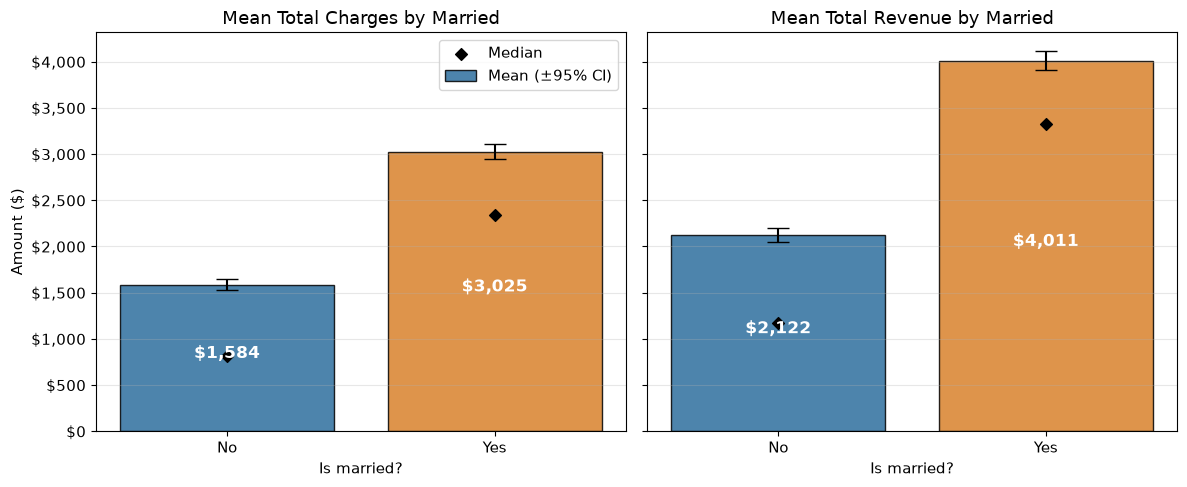

In [114]:
# --- Graph: mean (±95% CI) with median, one panel per variable ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, m in zip(axes, vars_receita):
    g = TELCO.groupby("Married")[m]
    means, medians, ci = (
        g.mean().loc[order],
        g.median().loc[order],
        (g.sem() * 1.96).loc[order],
    )
    bars = ax.bar(
        order,
        means,
        yerr=ci,
        capsize=8,
        color=[BLUE, ORANGE],
        edgecolor="black",
        alpha=0.85,
        label="Mean (±95% CI)",
    )
    ax.scatter(order, medians, color="k", marker="D", zorder=3, label="Median")
    for b, v in zip(bars, means):
        ax.text(
            b.get_x() + b.get_width() / 2,
            v * 0.5,
            f"${v:,.0f}",
            ha="center",
            color="white",
            fontweight="bold",
            fontsize=12,
        )
    ax.yaxis.set_major_formatter(money)
    ax.set_title(f"Mean {m} by Married")
    ax.set_xlabel("Is married?")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Amount ($)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Block B: The result remains the same with the same tenure?

         count  mean  median
Married                     
No        3641  23.4    16.0
Yes       3402  42.0    46.0

[Tenure in Months] Mann-Whitney p-value: 6.753e-231 | rank-biserial: 0.446


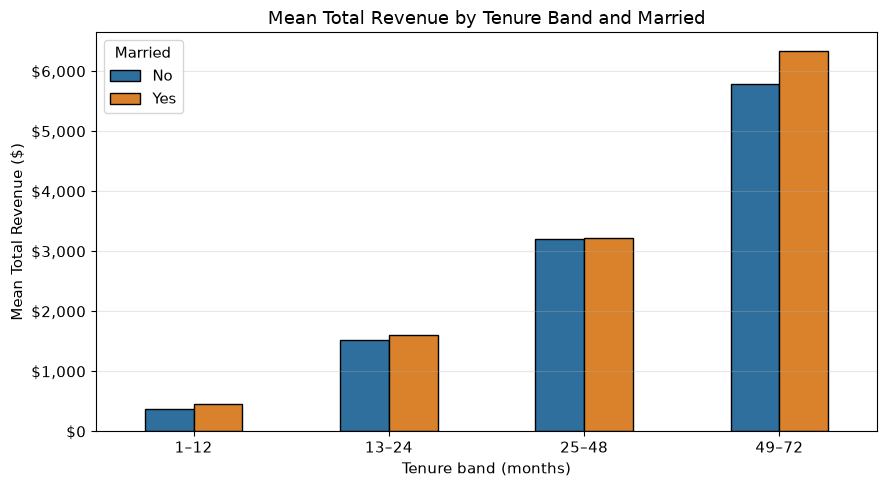

In [115]:
# --- Tenure by Married ---
t_yes = TELCO.loc[TELCO["Married"] == "Yes", "Tenure in Months"]
t_no = TELCO.loc[TELCO["Married"] == "No", "Tenure in Months"]
u, p = stats.mannwhitneyu(t_yes, t_no, alternative="two-sided")
print(
    TELCO.groupby("Married")["Tenure in Months"]
    .agg(["count", "mean", "median"])
    .loc[order]
    .round(1)
)
print(
    f"\n[Tenure in Months] Mann-Whitney p-value: {p:.4g} | "
    f"rank-biserial: {2 * u / (len(t_yes) * len(t_no)) - 1:.3f}"
)

# --- Total Revenue by tenure band and Married ---
pivot = TELCO.pivot_table(
    index="Tenure Band",
    columns="Married",
    values="Total Revenue",
    aggfunc="mean",
    observed=True,
)[order]
ax = pivot.plot(kind="bar", color=[BLUE, ORANGE], edgecolor="black", figsize=(9, 5))
ax.yaxis.set_major_formatter(money)
ax.set_title("Mean Total Revenue by Tenure Band and Married")
ax.set_xlabel("Tenure band (months)")
ax.set_ylabel("Mean Total Revenue ($)")
plt.xticks(rotation=0)
ax.grid(alpha=0.3, axis="y")
ax.legend(title="Married")
plt.tight_layout()
plt.show()

### Conclusion: Married vs Total Charges / Total Revenue

Married customers generate substantially more revenue overall (mean Total Revenue $4,011 vs $2,122, +89%; median $3,330 vs $1,176). The difference is statistically significant (Mann-Whitney p < 0.001) and moderate in size (rank-biserial r = 0.41), about four times the effect found for Dependents (r = 0.09). Total Charges gives the same result (r = 0.40), as expected, since Total Revenue is derived from it.

Most of this gap comes from tenure: married customers stay much longer (mean [X] vs [Y] months, r = [X]). When customers are compared within the same tenure band, the gap shrinks to nothing or a small advantage for married customers (0% at 25–48 months, roughly 5–10% at 13–24 and 49–72 months, and about 20% in the first year, where the amounts are small). Being married is therefore mainly a marker of long-lived customers, with at most a small additional advantage in value per customer. This is an association, and the data cannot show why.

# 3. Relation between Referred a Friend e o Churn Score
Customers who referred a friend are expected to be more engaged with the company, so a lower Churn Score (lower predicted risk) is expected for them.

## Block 1. Referred a Friend vs Churn Score

Do customers who referred a friend have a lower predicted churn risk?

In [116]:
# --- 1. Summary table ---
order = ["No", "Yes"]
print(
    TELCO.groupby("Referred a Friend")["Churn Score"]
    .agg(["count", "mean", "median", "std"])
    .loc[order]
    .round(1)
)

                   count  mean  median   std
Referred a Friend                           
No                  3821  60.6    65.0  21.3
Yes                 3222  56.0    57.0  20.7


In [117]:
# --- 2. Statistical test (non-parametric: Churn Score is bounded 0-100) ---
cs_yes = TELCO.loc[TELCO["Referred a Friend"] == "Yes", "Churn Score"]
cs_no = TELCO.loc[TELCO["Referred a Friend"] == "No", "Churn Score"]

u, p = stats.mannwhitneyu(cs_yes, cs_no, alternative="two-sided")
rank_biserial = 2 * u / (len(cs_yes) * len(cs_no)) - 1  # effect size, -1 to 1
print(
    f"\n[Churn Score] Mann-Whitney p-value: {p:.4g} | rank-biserial: {rank_biserial:.3f}"
)
print(f"Mean difference (Yes - No): {cs_yes.mean() - cs_no.mean():+.1f} points")


[Churn Score] Mann-Whitney p-value: 5.843e-20 | rank-biserial: -0.126
Mean difference (Yes - No): -4.5 points


                  Customers      % of group      
Referred a Friend        No  Yes         No   Yes
Churn Score Range                                
0–10                      4    4        0.1   0.1
10–20                     0    0        0.0   0.0
20–30                   416  439       10.9  13.6
30–40                   413  403       10.8  12.5
40–50                   404  450       10.6  14.0
50–60                   439  431       11.5  13.4
60–70                   591  484       15.5  15.0
70–80                   760  591       19.9  18.3
80–90                   407  224       10.7   7.0
90–100                  387  196       10.1   6.1


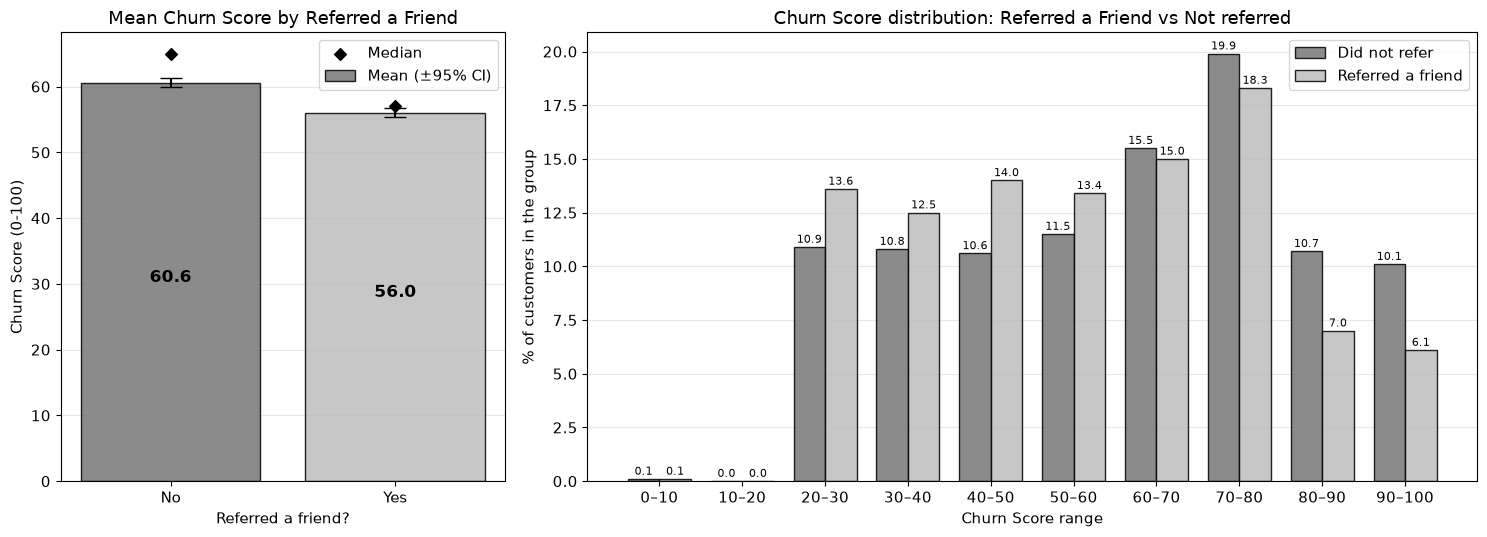

In [118]:
# --- Graph: Referred a Friend vs Churn Score (mean ± 95% CI | distribution by range) ---
order = ["No", "Yes"]
GREY_NO, GREY_YES = "#777777", "#BDBDBD"

# Left panel data: mean, median and 95% CI per group
g = TELCO.groupby("Referred a Friend")["Churn Score"]
means, medians, ci95 = (
    g.mean().loc[order],
    g.median().loc[order],
    (g.sem() * 1.96).loc[order],
)

# Right panel data: % of each group in each Churn Score range
edges = np.arange(0, 101, 10)
labels = [f"{a}–{b}" for a, b in zip(edges[:-1], edges[1:])]
TELCO["Churn Score Range"] = pd.cut(
    TELCO["Churn Score"], edges, labels=labels, right=False, include_lowest=True
)

counts = pd.crosstab(TELCO["Churn Score Range"], TELCO["Referred a Friend"]).reindex(
    index=labels, columns=order, fill_value=0
)
pct = (counts / counts.sum() * 100).round(1)
print(pd.concat({"Customers": counts, "% of group": pct}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 2]})

# Left: mean ± 95% CI with median
bars = axes[0].bar(
    order,
    means,
    yerr=ci95,
    capsize=8,
    color=[GREY_NO, GREY_YES],
    edgecolor="black",
    alpha=0.85,
    label="Mean (±95% CI)",
)
axes[0].scatter(order, medians, color="k", marker="D", zorder=3, label="Median")
for b, m in zip(bars, means):
    axes[0].text(
        b.get_x() + b.get_width() / 2,
        m * 0.5,
        f"{m:.1f}",
        ha="center",
        color="black",
        fontweight="bold",
        fontsize=12,
    )
axes[0].set_title("Mean Churn Score by Referred a Friend")
axes[0].set_xlabel("Referred a friend?")
axes[0].set_ylabel("Churn Score (0-100)")
axes[0].legend()
axes[0].grid(alpha=0.3, axis="y")
axes[0].set_axisbelow(True)

# Right: grouped bars by Churn Score range (% within each group)
x, w = np.arange(len(labels)), 0.38
b1 = axes[1].bar(
    x - w / 2,
    pct["No"],
    w,
    color=GREY_NO,
    edgecolor="black",
    alpha=0.85,
    label="Did not refer",
)
b2 = axes[1].bar(
    x + w / 2,
    pct["Yes"],
    w,
    color=GREY_YES,
    edgecolor="black",
    alpha=0.85,
    label="Referred a friend",
)
for bars in (b1, b2):
    for b in bars:
        axes[1].text(
            b.get_x() + b.get_width() / 2,
            b.get_height() + 0.2,
            f"{b.get_height():.1f}",
            ha="center",
            fontsize=8,
        )
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title("Churn Score distribution: Referred a Friend vs Not referred")
axes[1].set_xlabel("Churn Score range")
axes[1].set_ylabel("% of customers in the group")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

The results suggest that customers who did not refer a friend tend to have a higher concentration of elevated Churn Scores, particularly in the 80–100 ranges. This may indicate an association between a higher risk of customer churn and a lower likelihood of recommending the company. However, this relationship does not necessarily imply causation.

"The chart demonstrates that making a referral does not make a customer immune to churn. Although customers who refer friends have, on average, a lower overall risk profile (as seen in the 20–60 ranges), they remain susceptible to standard attrition drivers.
Factors such as contract expirations, price sensitivity, or changing personal needs affect all users universally. This explains why both groups share a synchronized peak in the high-risk 70–80 range, proving that historical advocacy (referring a friend) does not permanently guarantee long-term retention."

## Block 2. Does the result remain the same with similar customers?

Referrers may simply be customers with longer tenure or longer contracts, which already lowers churn risk. We check whether the gap persists within tenure bands and contract types.

In [119]:
# Does the gap survive at similar tenure / contract? (quick check for the modelling phase)
by_band = TELCO.pivot_table(
    index="Tenure Band",
    columns="Referred a Friend",
    values="Churn Score",
    aggfunc="mean",
    observed=True,
)[order]
by_contract = TELCO.pivot_table(
    index="Contract", columns="Referred a Friend", values="Churn Score", aggfunc="mean"
)[order]

by_band["Gap (Yes−No)"] = by_band["Yes"] - by_band["No"]
by_contract["Gap (Yes−No)"] = by_contract["Yes"] - by_contract["No"]
print(by_band.round(1), "\n")
print(by_contract.round(1))

# Spearman: Number of Referrals vs Churn Score
rho, p_rho = stats.spearmanr(TELCO["Number of Referrals"], TELCO["Churn Score"])
print(
    f"\nSpearman (Number of Referrals vs Churn Score): rho = {rho:.3f}, p = {p_rho:.4g}"
)

Referred a Friend    No   Yes  Gap (Yes−No)
Tenure Band                                
1–12               65.3  62.6          -2.7
13–24              58.7  58.8           0.1
25–48              58.0  57.3          -0.7
49–72              54.3  52.3          -1.9 

Referred a Friend    No   Yes  Gap (Yes−No)
Contract                                   
Month-to-Month     65.3  63.5          -1.8
One Year           52.7  53.9           1.2
Two Year           52.1  50.2          -1.9

Spearman (Number of Referrals vs Churn Score): rho = -0.168, p = 6.371e-46


### Conclusion: Referred a Friend vs Churn Score

Customers who referred a friend have a lower Churn Score overall (mean 56.0 vs 60.6, a difference of −4.6 points; Mann-Whitney p = 5.843e-20, rank-biserial r = -0.126), and non-referrers are more concentrated in the 80–100 ranges.

Part of this gap comes from tenure and contract, not from the referral itself. When customers are compared within the same group, the difference shrinks to between −2.7 and +1.2 points:

- **By tenure band:** −2.7 (1–12 months), +0.1 (13–24), −0.7 (25–48) and −1.9 (49–72).
- **By contract:** −1.8 (Month-to-Month), +1.2 (One Year) and −1.9 (Two Year).

The direction is mostly the same (5 of 7 groups favour referrers), but the effect is small and inconsistent, with two groups showing no gap or a reversed one (13–24 months and One Year).

Number of Referrals has a weak negative relation with the Churn Score (Spearman rho = −0.168, p < 0.001). The p-value is very small mainly because of the sample size, while the relation itself is weak: customers with more referrals tend to have lower scores, but the number of referrals explains very little of the score.

**For modelling:** Referred a Friend and Number of Referrals carry a small signal that overlaps with tenure and contract, so they are reasonable candidate features but unlikely to add much beyond them. Their real contribution should be confirmed in the model (for example with feature importance or by comparing performance with and without them). This is an association, and the data cannot show whether referring a friend reduces churn.

# 4. Relation between Offer and Churn Score

Customers who received an offer are expected to have a lower Churn Score than those who did not. We also check whether Offer A stands out.

In [120]:
# --- Offer vs Churn Score ---
TELCO["Offer"] = TELCO["Offer"].fillna("None")  # "None" can be read as missing
offer_order = ["None", "Offer A", "Offer B", "Offer C", "Offer D", "Offer E"]
offer_order = [o for o in offer_order if o in TELCO["Offer"].unique()]

# 1. Summary: size, share and Churn Score per offer
summary = (
    TELCO.groupby("Offer")["Churn Score"]
    .agg(["count", "mean", "median", "std"])
    .loc[offer_order]
)
summary.insert(1, "% customers", (summary["count"] / len(TELCO) * 100).round(1))
print(summary.round(1))

         count  % customers  mean  median   std
Offer                                          
None      3877         55.0  58.6    61.0  21.2
Offer A    520          7.4  50.9    52.0  19.2
Offer B    824         11.7  54.8    56.0  20.0
Offer C    415          5.9  58.2    60.0  20.5
Offer D    602          8.5  58.4    62.0  20.9
Offer E    805         11.4  66.7    71.0  21.0


In [121]:
# 2. Tests
groups = [TELCO.loc[TELCO["Offer"] == o, "Churn Score"] for o in offer_order]
H, p_kw = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(TELCO) - len(groups))  # effect size (epsilon²)
print(f"\nKruskal-Wallis (all offers): p = {p_kw:.4g} | epsilon² = {eps2:.3f}")

has_offer = TELCO["Offer"] != "None"
u, p_any = stats.mannwhitneyu(
    TELCO.loc[has_offer, "Churn Score"],
    TELCO.loc[~has_offer, "Churn Score"],
    alternative="two-sided",
)
rb = 2 * u / (has_offer.sum() * (~has_offer).sum()) - 1
print(f"Any offer vs None: Mann-Whitney p = {p_any:.4g} | rank-biserial = {rb:.3f}")

# 3. Does Offer A stand out? Offer mix in low-risk vs high-risk customers (% of each group)
risk = pd.cut(
    TELCO["Churn Score"],
    [0, 39, 69, 100],
    labels=["Low (0-39)", "Medium (40-69)", "High (70-100)"],
    include_lowest=True,
)
print("\nOffer mix by risk band (column %):")
print(
    (pd.crosstab(TELCO["Offer"], risk, normalize="columns") * 100)
    .loc[offer_order]
    .round(1)
)

# 4. Are offers linked to tenure? (possible confounder)
print("\nMean tenure by offer:")
print(TELCO.groupby("Offer")["Tenure in Months"].mean().loc[offer_order].round(1))


Kruskal-Wallis (all offers): p = 2.02e-46 | epsilon² = 0.031
Any offer vs None: Mann-Whitney p = 0.4702 | rank-biserial = -0.010

Offer mix by risk band (column %):
Churn Score  Low (0-39)  Medium (40-69)  High (70-100)
Offer                                                 
None               54.7            54.2           56.2
Offer A            10.4             8.7            4.0
Offer B            12.9            13.4            9.0
Offer C             5.7             6.5            5.4
Offer D             9.0             8.3            8.6
Offer E             7.3             9.0           16.8

Mean tenure by offer:
Offer
None       31.6
Offer A    70.0
Offer B    53.4
Offer C    30.8
Offer D    16.0
Offer E     3.7
Name: Tenure in Months, dtype: float64


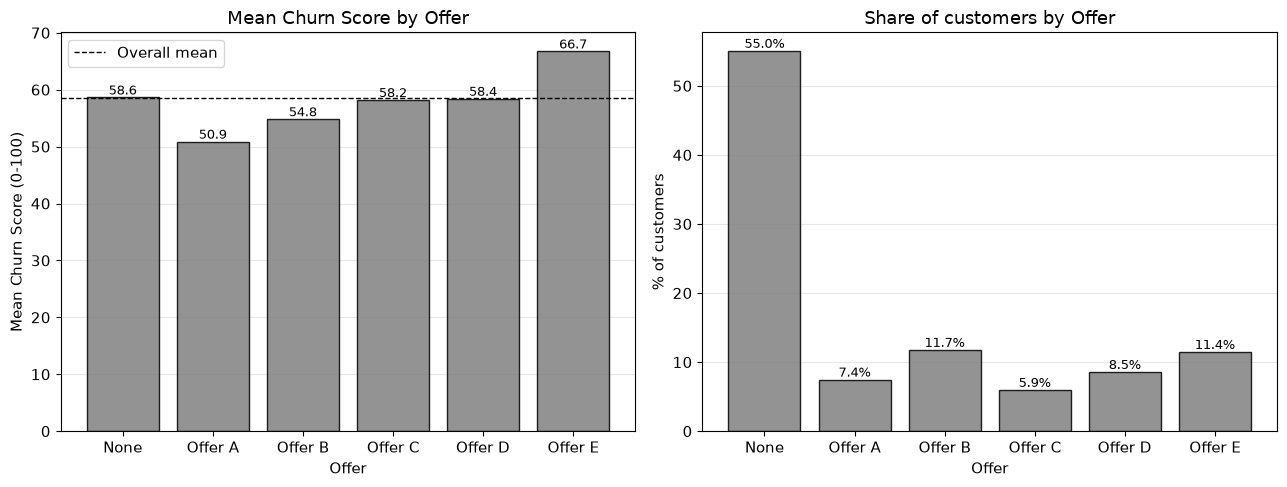

In [122]:
# --- Graph: mean Churn Score by offer + share of customers per offer ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(
    offer_order, summary["mean"], color="grey", edgecolor="black", alpha=0.85
)
axes[0].axhline(
    TELCO["Churn Score"].mean(), color="k", ls="--", lw=1, label="Overall mean"
)
for b, v in zip(bars, summary["mean"]):
    axes[0].text(
        b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center", fontsize=9
    )
axes[0].set_title("Mean Churn Score by Offer")
axes[0].set_xlabel("Offer")
axes[0].set_ylabel("Mean Churn Score (0-100)")
axes[0].legend()
axes[0].grid(alpha=0.3, axis="y")
axes[0].set_axisbelow(True)

bars = axes[1].bar(
    offer_order, summary["% customers"], color="grey", edgecolor="black", alpha=0.85
)
for b, v in zip(bars, summary["% customers"]):
    axes[1].text(
        b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9
    )
axes[1].set_title("Share of customers by Offer")
axes[1].set_xlabel("Offer")
axes[1].set_ylabel("% of customers")
axes[1].grid(alpha=0.3, axis="y")
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

### Conclusion: Offer vs Churn Score

**Receiving an offer, by itself, is not associated with a lower Churn Score.** Customers with any offer and customers with no offer have practically the same scores (Mann-Whitney p = 0.47, rank-biserial r = −0.01), so the expectation that "more offers means lower risk" is not supported. The Churn Score does differ between offer types (Kruskal-Wallis p < 0.001), but the effect is small (epsilon² = 0.031). Offers A and B have lower means (50.9 and 54.8), Offer E is clearly higher (66.7), and None, C and D stay close to the overall mean (58.2–58.6).

**Offer A stands out for low risk, but only for a small group.** It reaches just 7.4% of customers, yet it represents 10.4% of the low-risk band against 4.0% of the high-risk band, and it has the lowest mean score. Offer E is the opposite: 7.3% of the low-risk band against 16.8% of the high-risk band.

**Tenure explains most of this pattern.** Offer A customers have a mean tenure of 70 months, against 31.6 for customers with no offer, and Offer B has 53.4. Offer E customers are very recent (3.7 months), and Offer D also has short tenure (16.0). The offers therefore seem to be given to different stages of the customer lifecycle, and the score differences largely reflect tenure, which we already know lowers churn risk.

**For modelling:** Offer carries some signal, but it largely overlaps with tenure, so it is a reasonable candidate feature that should add little beyond it. This is consistent with Offer A having a low churn rate in the EDA but a positive coefficient in the logistic regression. This is an association: the data cannot show whether the offers themselves reduce churn, because they were not assigned at random.

# 5. Relation between Payment Method, Churn Score and Customer Status

Payment method is expected to be linked to churn risk (automatic payments tend to keep customers longer). We check it against the Churn Score, against the real Customer Status, and then cross it with tenure in a heatmap.

In [123]:
# Só clientes já existentes na empresa (sem Joined)
obs = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
obs["churn"] = (obs["Customer Status"] == "Churned").astype(int)
print(f"Clientes analisados: {len(obs)} (Joined excluídos: {len(TELCO) - len(obs)})\n")

Clientes analisados: 6589 (Joined excluídos: 454)



In [124]:
# Payment Method vs Churn Score (método ordenado do score mais baixo ao mais alto)
pay_order = (
    obs.groupby("Payment Method")["Churn Score"].mean().sort_values().index.tolist()
)

print(
    obs.groupby("Payment Method")["Churn Score"]
    .agg(["count", "mean", "median"])
    .loc[pay_order]
    .round(1)
)

                 count  mean  median
Payment Method                      
Credit Card       2518  55.4    56.0
Bank Withdrawal   3728  61.5    66.0
Mailed Check       343  62.0    66.0


In [125]:
# Payment Method vs Customer Status (taxa de churn real)
churn_rate = (
    obs.groupby("Payment Method")["churn"].agg(["count", "mean"]).loc[pay_order]
)
churn_rate["mean"] = (churn_rate["mean"] * 100).round(1)
print("\nTaxa de churn por Payment Method:")
print(churn_rate.rename(columns={"count": "customers", "mean": "churn rate (%)"}))

# Tenure médio por método (para perceber se o tenure explica a diferença)
print("\nTenure médio por Payment Method:")
print(obs.groupby("Payment Method")["Tenure in Months"].mean().loc[pay_order].round(1))


Taxa de churn por Payment Method:
                 customers  churn rate (%)
Payment Method                            
Credit Card           2518            15.8
Bank Withdrawal       3728            35.6
Mailed Check           343            41.4

Tenure médio por Payment Method:
Payment Method
Credit Card        37.1
Bank Withdrawal    34.0
Mailed Check       21.3
Name: Tenure in Months, dtype: float64


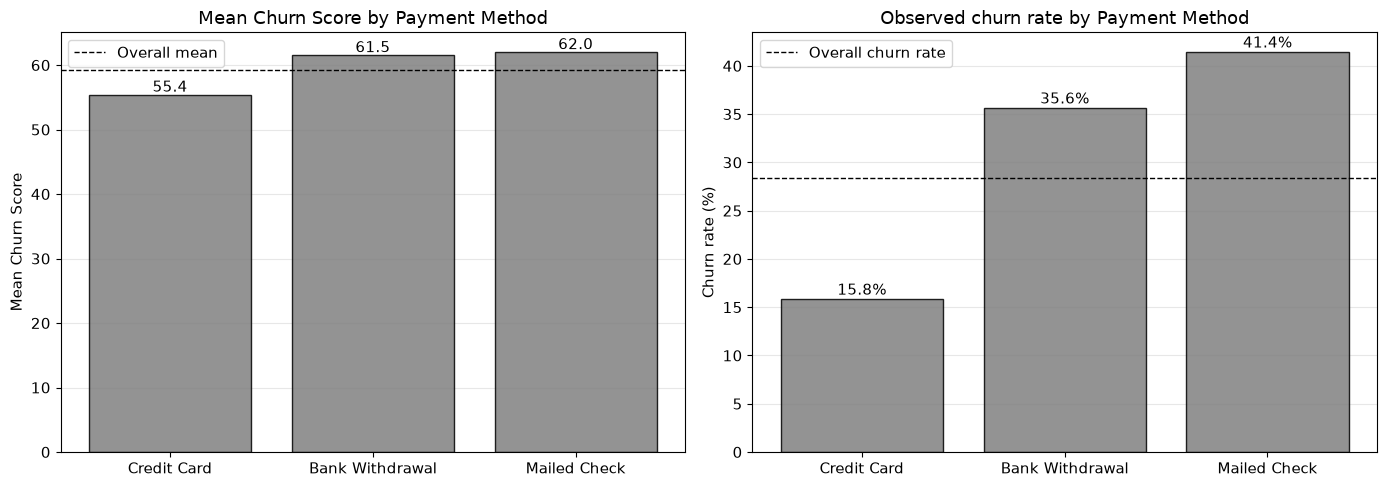

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Esquerda: Churn Score médio por método
means = obs.groupby("Payment Method")["Churn Score"].mean().loc[pay_order]
axes[0].axhline(
    obs["Churn Score"].mean(), color="k", ls="--", lw=1, label="Overall mean"
)
bars = axes[0].bar(pay_order, means, color="grey", edgecolor="black", alpha=0.85)
for b, v in zip(bars, means):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center")
axes[0].set_title("Mean Churn Score by Payment Method")
axes[0].set_ylabel("Mean Churn Score")
axes[0].set_xlabel("")
axes[0].grid(alpha=0.3, axis="y")
axes[0].set_axisbelow(True)

# Direita: taxa de churn real por método
bars = axes[1].bar(
    pay_order, churn_rate["mean"], color="grey", edgecolor="black", alpha=0.85
)
axes[1].axhline(
    obs["churn"].mean() * 100, color="k", ls="--", lw=1, label="Overall churn rate"
)
for b, v in zip(bars, churn_rate["mean"]):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center")
axes[1].set_title("Observed churn rate by Payment Method")
axes[1].set_ylabel("Churn rate (%)")
axes[1].set_xlabel("")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")
axes[1].set_axisbelow(True)

axes[0].legend()
plt.tight_layout()
plt.show()

In [127]:
import seaborn as sns

heat = obs.pivot_table(
    index="Payment Method",
    columns="Tenure Band",
    values="Churn Score",
    aggfunc="mean",
    observed=True,
).loc[pay_order]

# Nº de clientes por célula (para confirmar que nenhuma célula tem poucos clientes)
print("Clientes por célula:")
print(
    obs.pivot_table(
        index="Payment Method",
        columns="Tenure Band",
        values="Churn Score",
        aggfunc="count",
        observed=True,
    ).loc[pay_order]
)

plt.figure(figsize=(8, 4))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1f",
    cmap="Greys",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Mean Churn Score"},
)
plt.title("Mean Churn Score: Payment Method x Tenure Band")
plt.xlabel("Tenure band (months)")
plt.ylabel("")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

### Conclusion: Payment Method vs Churn Score and Customer Status

This analysis includes only customers already in the company (Stayed and Churned, 6,589 customers). The 454 Joined customers were excluded because they have no churn outcome yet.

**Churn Score:** Credit Card customers have the lowest mean score (55.4), while Bank Withdrawal (61.5) and Mailed Check (62.0) are higher.

**Customer Status:** the real outcome follows the same order, with a larger gap. 15.8% of Credit Card customers churned, against 35.6% with Bank Withdrawal and 41.4% with Mailed Check, which is well above the overall churn rate (around 28%). The model score and the observed churn point in the same direction.

**Tenure (heatmap):** risk falls with tenure for every payment method, and tenure explains part of the Mailed Check result. These customers are much newer (mean tenure of 21.3 months vs 37.1 for Credit Card and 34.0 for Bank Withdrawal), and 48% of them are in their first year (vs 21% for Credit Card).
- **Credit Card vs Bank Withdrawal:** the gap persists in every tenure band, but it shrinks with tenure (−8.4, −8.7, −4.6 and −2.4 points from the shortest to the longest band). Credit Card therefore carries information beyond tenure.
- **Mailed Check:** it has the highest score only in the first year (71.7, similar to Bank Withdrawal at 71.5). In the other bands it is closer to Credit Card than to Bank Withdrawal, and it has the lowest score after 49 months (44.2). This group is small (343 customers, only 53–62 per cell after the first year), so these values should be read with caution.

**For modelling:** Payment Method is a useful candidate feature, mainly through Credit Card (lower risk) versus the remaining methods. This is consistent with the logistic regression coefficients (Mailed Check increases risk, Credit Card reduces it). This is an association: the payment method may reflect the customer profile (for example automatic, card-based payments) and not cause the lower churn.

# 6. Relation between financial groups and Churn Score

We compare the financial profile of the three risk groups (Low 0–39, Medium 40–69, High 70–100), using all customers, to identify which financial groups concentrate a high Churn Score. We use Monthly Charge (current spend) and Total Charges (accumulated spend). Total Revenue is left out because it is almost the same measure as Total Charges (Spearman rho = 0.978) and is not used in the model.

In [128]:
# --- Financial variables by risk group (all customers) ---
fin_vars = ["Monthly Charge", "Total Charges"]
band_order = ["Low (0-39)", "Medium (40-69)", "High (70-100)"]
TELCO["Risk Band"] = pd.cut(
    TELCO["Churn Score"], [0, 39, 69, 100], labels=band_order, include_lowest=True
)

print(
    TELCO["Risk Band"].value_counts().reindex(band_order), "\n"
)  # should match the risk band chart

summary = (
    TELCO.groupby("Risk Band", observed=True)[fin_vars].agg(["mean", "median"]).round(0)
)
print(summary)

Risk Band
Low (0-39)        1679
Medium (40-69)    2799
High (70-100)     2565
Name: count, dtype: int64 

               Monthly Charge        Total Charges        
                         mean median          mean  median
Risk Band                                                 
Low (0-39)               61.0   62.0        2533.0  1652.0
Medium (40-69)           63.0   68.0        2476.0  1640.0
High (70-100)            69.0   76.0        1902.0  1058.0


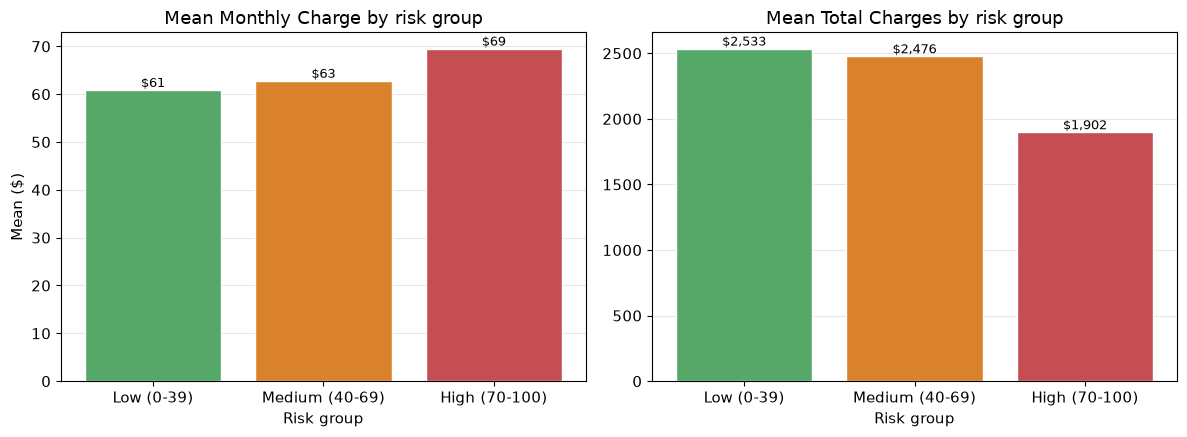

In [129]:
# --- Graph: mean of each financial variable by risk group ---
risk_colors = ["#55A868", ORANGE, "#C44E52"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, v in zip(axes, fin_vars):
    vals = TELCO.groupby("Risk Band", observed=True)[v].mean().reindex(band_order)
    bars = ax.bar(band_order, vals, color=risk_colors, edgecolor="white")
    for b, m in zip(bars, vals):
        ax.text(
            b.get_x() + b.get_width() / 2,
            m * 1.01,
            f"${m:,.0f}",
            ha="center",
            fontsize=9,
        )
    ax.set_title(f"Mean {v} by risk group")
    ax.set_xlabel("Risk group")
    ax.grid(alpha=0.3, axis="y")
    ax.set_axisbelow(True)
axes[0].set_ylabel("Mean ($)")
plt.tight_layout()
plt.show()

In [130]:
# --- How much of the relation with Churn Score is just tenure? ---
def partial_spearman(x, y, control):
    """Spearman between x and y after removing the linear effect of `control` (on ranks)."""
    rx, ry, rc = x.rank(), y.rank(), control.rank()
    res_x = rx - np.polyval(np.polyfit(rc, rx, 1), rc)
    res_y = ry - np.polyval(np.polyfit(rc, ry, 1), rc)
    return np.corrcoef(res_x, res_y)[0, 1]


rows = []
for v in fin_vars:
    raw, _ = stats.spearmanr(TELCO[v], TELCO["Churn Score"])
    ten, _ = stats.spearmanr(TELCO[v], TELCO["Tenure in Months"])
    part = partial_spearman(TELCO[v], TELCO["Churn Score"], TELCO["Tenure in Months"])
    rows.append(
        {
            "Variable": v,
            "rho with Churn Score": round(raw, 3),
            "rho with Tenure": round(ten, 3),
            "rho controlling tenure": round(part, 3),
        }
    )
print(pd.DataFrame(rows).set_index("Variable"))

# Same check inside each tenure band
bands = TELCO["Tenure Band"].cat.categories
within = pd.DataFrame(
    {
        v: [
            TELCO.loc[TELCO["Tenure Band"] == b, v].corr(
                TELCO.loc[TELCO["Tenure Band"] == b, "Churn Score"], method="spearman"
            )
            for b in bands
        ]
        for v in fin_vars
    },
    index=bands,
).round(3)
print("\nSpearman with Churn Score within each tenure band:")
print(within)

                rho with Churn Score  rho with Tenure  rho controlling tenure
Variable                                                                     
Monthly Charge                 0.130            0.276                   0.211
Total Charges                 -0.146            0.889                   0.153

Spearman with Churn Score within each tenure band:
       Monthly Charge  Total Charges
1–12            0.275          0.008
13–24           0.289          0.217
25–48           0.198          0.152
49–72           0.091          0.054


In [131]:
# --- High-value customers: risk profile by Monthly Charge quintile ---
q_labels = ["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
TELCO["Charge Quintile"] = pd.qcut(
    TELCO["Monthly Charge"].rank(method="first"), 5, labels=q_labels
)

heat = (
    pd.crosstab(TELCO["Charge Quintile"], TELCO["Risk Band"], normalize="index") * 100
)[band_order].round(1)

plt.figure(figsize=(7, 4))
sns.heatmap(
    heat,
    annot=True,
    fmt=".1f",
    cmap="Greys",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "% of quintile"},
)
plt.title("Risk group by Monthly Charge quintile (row %)")
plt.xlabel("Risk group")
plt.ylabel("Monthly Charge quintile")
plt.tight_layout()
plt.show()

# High value (top 20% Monthly Charge) AND high risk (score 70-100)
hv = TELCO["Charge Quintile"] == "Q5 (highest)"
hr = TELCO["Risk Band"] == "High (70-100)"
print(f"High-risk customers: {hr.sum()} ({hr.mean() * 100:.1f}% of all)")
print(
    f"High-value AND high-risk: {(hv & hr).sum()} customers "
    f"= {(hv & hr).sum() / hr.sum() * 100:.1f}% of the high-risk group"
)
print(
    f"Monthly revenue of the high-risk group: ${TELCO.loc[hr, 'Monthly Charge'].sum():,.0f} "
    f"(of which {TELCO.loc[hv & hr, 'Monthly Charge'].sum() / TELCO.loc[hr, 'Monthly Charge'].sum() * 100:.1f}% "
    f"from high-value customers)"
)

NameError: name 'sns' is not defined

<Figure size 700x400 with 0 Axes>

### Conclusion: Financial groups vs Churn Score

All customers are included (7,043).

**Monthly Charge:** customers who pay more per month are more likely to be high-risk. The share of high-risk customers goes from 26.1% in the lowest quintile to 41.0–43.6% in the two highest (overall: 36.4%), and the relation holds when we compare customers with the same tenure.

**Total Charges:** it looks lower for high-risk customers ($1,902 vs $2,533), but only because they are newer and have had less time to accumulate charges. At the same tenure the relation disappears, so Total Charges mostly measures tenure and adds little. Total Revenue behaves the same way and is left out.

**High-value and high-risk:** 577 customers in the top quintile of Monthly Charge are also high-risk. They are 22.5% of the high-risk group but carry 33.1% of its monthly revenue, so this is the segment to protect first.

**For modelling:** Monthly Charge has a clear and independent signal, while Total Charges mostly overlaps with tenure. These are associations, not causes.

### 1.2 - Que caracteristicas estão associadas ao churn? (Problema 1)

Taxa de churn global: 0.284


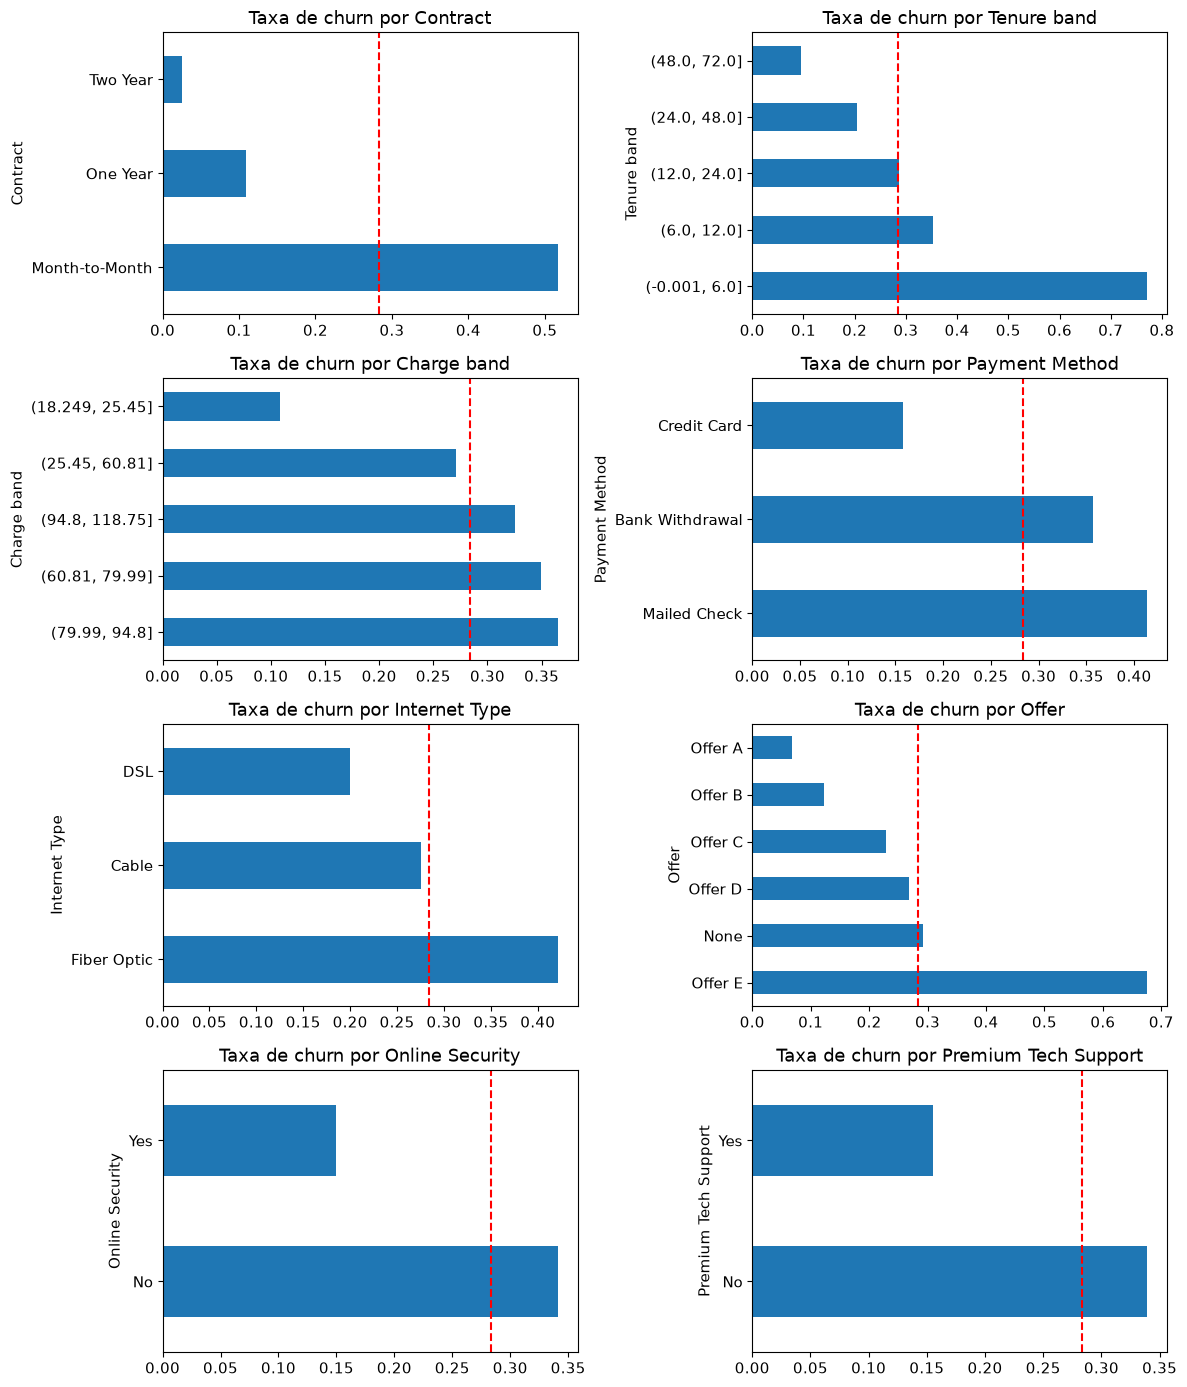

In [132]:
eda = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
eda["churn"] = (eda["Customer Status"] == "Churned").astype(int)
print("Taxa de churn global:", eda["churn"].mean().round(3))

eda["Tenure band"] = pd.cut(
    eda["Tenure in Months"], [0, 6, 12, 24, 48, 72], include_lowest=True
).astype(str)
eda["Charge band"] = pd.qcut(eda["Monthly Charge"], 5).astype(str)

cols = [
    "Contract",
    "Tenure band",
    "Charge band",
    "Payment Method",
    "Internet Type",
    "Offer",
    "Online Security",
    "Premium Tech Support",
]

fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for ax, col in zip(axes.ravel(), cols):
    rate = eda.groupby(col)["churn"].mean().sort_values(ascending=False)
    rate.plot.barh(ax=ax)
    ax.axvline(eda["churn"].mean(), color="red", linestyle="--")  # média global
    ax.set_title(f"Taxa de churn por {col}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

#### **Resultado obtido** — o que a análise exploratória mostra

A taxa de churn global é de **28,4%** (linha vermelha tracejada em cada gráfico).
 Este valor foi obtido anteriormente tendo como base o somatorio dos Churned a dividir pelos Churned+Stayed (excluding Joined)

##### Os grupos acima dessa linha são os de maior risco:

| Fator | Grupos de maior risco | Grupos de menor risco |
|---|---|---|
| Contrato | Month-to-Month: **51,7%** | One Year: **10,9%** · Two Year: **2,6%** |
| Antiguidade | 0–6 Meses: **77,2%** (7–12 m: 35,3%) | 49–72 Meses: **9,5%** |
| Encargo mensal | Band 3 a 5: **32,5–36,5%** | Band mais baixo: **10,9%** |
| Método de pagamento | Mailed Check: **41,4%** · Bank Withdrawal: 35,6% | Credit Card: **15,8%** |
| Tipo de internet | Fiber Optic: **42,1%** | Sem internet: **8,4%** · DSL: **20,0%** |
| Offer | Offer E: **67,6%** | Offer A: **6,7%** · Offer B: **12,3%** |
| Online Security / Premium Tech Support | Sem o serviço: **34,1%** / **34,0%** | Com o serviço: **15,0%** / **15,5%** |

**Contexto:** o churn concentra-se em **clientes recentes, com contrato mensal, sem serviços de segurança/suporte e com fibra**. A relação com o encargo mensal não é linear: o risco sobe do quintil mais baixo (10,9%) para os restantes, mas depois estabiliza em vez de continuar a subir.

**Offer E:** Com base na análise anterior, chegamos à conclusão que há um risco maior se oferecermos a Offer E, mesmo se compararmos em não dar nenhuma offer. Solução passará por redefinir as condições da Offer E (para membros mais recentes).

In [140]:
TELCO_CHARG = TELCO[["Customer Status", "Total Charges"]]
TELCO_CHARG.groupby("Customer Status")["Total Charges"].sum()

Customer Status
Churned     2862926.90
Joined        35998.90
Stayed     13161799.44
Name: Total Charges, dtype: float64

## Feature selection

In [ ]:
# 1. Manter apenas os clientes relevantes para o projeto
model_df = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()

# 2. Criar o Target Binário
y = (model_df["Customer Status"] == "Churned").astype(int)

# 3. Remover variáveis que revelam o target ou são inadequadas
dup_cols = [c for c in TELCO.columns if c.startswith(("Count", "Quarter"))]

exclude_cols = [
    "Customer ID",
    "Customer Status",
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "CLTV",
    "Churn Category",
    "Churn Reason",
    "Country",
    "State",
    "Lat Long",
    "City",
    "Zip Code",
    "Under 30",
    "Senior Citizen",
    "Dependents",
    "Referred a Friend",
    "Internet Service",
    "Total Revenue",
    "Satisfaction Score",
] + dup_cols

X = model_df.drop(columns=exclude_cols, errors="ignore")

print("Dimensões de X:", X.shape)
print("Distribuição do target:")
print(y.value_counts())
print("\nProporção de churn:")
print(y.mean().round(3))

Dimensões de X: (6589, 36)
Distribuição do target:
Customer Status
0    4720
1    1869
Name: count, dtype: int64

Proporção de churn:
0.284


#### **Porque excluímos estas variáveis?**
- **Customer ID:** Variavel Redundante pois não acrescenta informação ao modelo.
- **Customer Status:** Serve para construir o target, não para prever o próprio status.
- **Churn Label e Churn Value:** Contêm diretamente a resposta que queremos prever.
- **Churn Score e CLTV:** Já vem de outro modelo preditivo; não queremos que o primeiro modelo dependa de um score existente, nem que seja com base no modelo preditivo com formulas que desconhecemos.
- **Churn Category e Churn Reason** Descrevem o churn depois de este ocorrer.
- **Country, State, Lat Long, City e Zip Code:** Pois é uma variavel que considera muitos fatores que não temos informação.
- **Under 30 e Senior Citizen:** Estas foram excluidas por motivos de multicolineridade pois será usado a variavel "Age"
- **Dependents:** Porque é uma variavel redundante pois é uma cópia mais pobre de Number of Dependents, que ficou no modelo.
- **Referred a Friend:** Esta foi excluida por motivos de multicolineridade pois será usado o "Number of Referrals".
- **Internet Service:** Esta foi excluida por motivos de multicolineridade pois será usado o "Internet Type". É "No" exatamente quando "Internet Type" é "None" (100% dos clientes), logo "Internet Type" já traz a mesma informação e com mais detalhe.
- **Total Revenue:** Excluída por ser redundante: é a soma de Total Charges, Total Extra Data Charges e Total Long Distance Charges, menos Total Refunds
- **Satisfaction Score:** É excluído inicialmente por pertencer à tabela de status, por não termos uma certeza da periodicidade que foi obtida por cliente.
- Algumas variáveis são derivadas de outras ou redundantes. Mais tarde, podem testar se a sua inclusão melhora a solução.

#### Resultado obtido — conjunto de variáveis

- `X` fica com **6 589 clientes × 33 variáveis** e o alvo tem **4 720 Stayed (0) e 1 869 Churned (1)**, ou seja, 28,4% de churn: um desequilíbrio moderado, razão pela qual usamos PR-AUC e estratificação nos *splits*.
- As variáveis restantes são conhecidas **antes** de o cliente sair (demografia, serviços, contrato, faturação e encargos), ao contrário das excluídas acima, que descrevem ou resultam do churn.
- `Tenure in Months`, `Monthly Charge` e `Total Charges` estão muito relacionadas entre si (a correlação entre `Total Charges` e a antiguidade é 0,81), o que condiciona a leitura individual dos coeficientes mais à frente.

## Feature Engineering

**Vale a pena criar variáveis novas?** A research question pede uma lista ordenada de clientes por risco, por isso qualquer ganho de capacidade de ordenação do modelo traduz-se diretamente em mais churners apanhados com a mesma capacidade de contacto. A análise exploratória sugere três hipóteses:

1. **A antiguidade não tem um efeito linear.** O churn cai a pique nos primeiros meses (77,2% nos primeiros 6 meses, 9,5% depois dos 48) e depois achata. Uma regressão logística só aprende uma tendência linear em `Tenure in Months`.
2. **Há interações.** Clientes com contrato mensal *e* menos de um ano de casa têm 68,0% de churn (1 505 clientes), contra 16,6% nos restantes.
3. **Os serviços contam em conjunto.** Clientes com internet mas sem Online Security nem Premium Tech Support têm 52,9% de churn, contra 14,6% nos restantes.

Em vez de adivinhar, definimos candidatas e **testamos** quais ajudam o modelo:

| Variável | Definição | Motivação |
|---|---|---|
| `n_protection` | nº de serviços de proteção (Online Security, Online Backup, Device Protection, Premium Tech Support) | clientes com mais serviços estão mais "presos" ao operador |
| `n_streaming` | nº de serviços de streaming (TV, Movies, Music) | idem |
| `n_addons` | `n_protection` + `n_streaming` | resumo do envolvimento com a oferta |
| `charge_per_service` | `Monthly Charge` / (1 + `n_addons`) | quanto paga por cada serviço |
| `no_protection` | tem internet mas não tem Online Security nem Premium Tech Support | grupo de risco identificado na EDA |
| `log_tenure` | log(1 + `Tenure in Months`) | efeito côncavo da antiguidade |
| `is_new_customer` | `Tenure in Months` ≤ 12 | primeiro ano é o período crítico |
| `m2m_new` | Month-to-Month **e** `Tenure in Months` ≤ 12 | interação contrato × antiguidade |
| `charge_gap` | `Total Charges` − `Tenure` × `Monthly Charge` | deteta alterações de preço ao longo do tempo |
| `has_referrals` | `Number of Referrals` > 0 | clientes que trouxeram outros clientes |

Todas usam apenas informação do **próprio cliente** (nada do alvo nem estatísticas de outros clientes), por isso não introduzem *data leakage*.

### Novas Variáveis

In [ ]:
def add_features(X):
    # Cria variáveis derivadas das colunas que já existem.
    # Cada nova variável usa apenas informação do próprio cliente (sem estatísticas
    # do target nem de outros clientes), por isso não introduz data leakage.
    X = X.copy()
    n_sim = lambda cols: (X[cols] == "Yes").sum(axis=1)

    # --- Serviços subscritos
    X["n_protection"] = n_sim(
        [
            "Online Security",
            "Online Backup",
            "Device Protection Plan",
            "Premium Tech Support",
        ]
    )
    X["n_streaming"] = n_sim(["Streaming TV", "Streaming Movies", "Streaming Music"])
    X["n_addons"] = X["n_protection"] + X["n_streaming"]
    X["charge_per_service"] = X["Monthly Charge"] / (1 + X["n_addons"])
    X["no_protection"] = (
        (X["Internet Type"] != "None")
        & (X["Online Security"] == "No")
        & (X["Premium Tech Support"] == "No")
    ).astype(int)

    # --- Antiguidade e contrato
    novo = X["Tenure in Months"] <= 12
    X["log_tenure"] = np.log1p(X["Tenure in Months"])
    X["is_new_customer"] = novo.astype(int)
    X["m2m_new"] = ((X["Contract"] == "Month-to-Month") & novo).astype(int)

    # --- Outras
    X["charge_gap"] = X["Total Charges"] - X["Tenure in Months"] * X["Monthly Charge"]
    X["has_referrals"] = (X["Number of Referrals"] > 0).astype(int)
    return X


X_all_fe = add_features(X)
candidatas = [c for c in X_all_fe.columns if c not in X.columns]
print(len(candidatas), "variáveis candidatas:", candidatas)

10 variáveis candidatas: ['n_protection', 'n_streaming', 'n_addons', 'charge_per_service', 'no_protection', 'log_tenure', 'is_new_customer', 'm2m_new', 'charge_gap', 'has_referrals']


## Cap.2 Construção do Modelo Preditivo

### Teste: as novas variáveis melhoram o modelo?

Comparamos o mesmo modelo com e sem cada grupo de variáveis novas, usando **validação cruzada com 5 folds apenas na parte de desenvolvimento (80%)**. O conjunto de teste fica de fora, exatamente como em "Treino e Teste", para não ser usado para escolher variáveis. Testamos dois tipos de modelo:

- **LR** (regressão logística): modelo linear, o que mais pode beneficiar de variáveis que "ensinam" não-linearidades e interações;
- **GB** (gradient boosting): árvores, que já aprendem não-linearidades sozinhas.

A métrica principal é a PR-AUC, em linha com o objetivo de priorização.

### Pre-Processamento

In [ ]:
# Só usamos a parte de desenvolvimento (80%). O conjunto de teste fica de fora,
# exatamente como na secção "Treino e Teste".
X_dev0, _, y_dev0, _ = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


def make_preprocessor(Xa):
    num = Xa.select_dtypes(include="number").columns.tolist()
    cat = Xa.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                num,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                cat,
            ),
        ]
    )


grupos = {
    "Original (sem novas variáveis)": [],
    "+ contagens de serviços": ["n_protection", "n_streaming", "n_addons"],
    "+ encargo por serviço": ["charge_per_service"],
    "+ sem proteção": ["no_protection"],
    "+ antiguidade / contrato": ["log_tenure", "is_new_customer", "m2m_new"],
    "+ só log(tenure)": ["log_tenure"],
    "+ diferença de encargos": ["charge_gap"],
    "+ tem referências": ["has_referrals"],
    "+ selecionadas (ver abaixo)": [
        "log_tenure",
        "is_new_customer",
        "m2m_new",
        "has_referrals",
    ],
}
modelos_fe = {
    "LR": LogisticRegression(max_iter=3000),
    "GB": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
linhas = []
for nome, cols in grupos.items():
    Xa = X_all_fe.loc[X_dev0.index, list(X.columns) + cols]
    linha = {"Variáveis usadas": nome}
    for sigla, est in modelos_fe.items():
        r = cross_validate(
            Pipeline([("prep", make_preprocessor(Xa)), ("model", est)]),
            Xa,
            y_dev0,
            cv=cv,
            n_jobs=-1,
            scoring={"pr": "average_precision", "roc": "roc_auc"},
        )
        linha[f"{sigla} PR-AUC"] = r["test_pr"].mean()
        linha[f"{sigla} ROC-AUC"] = r["test_roc"].mean()
    linhas.append(linha)

fe_results = pd.DataFrame(linhas).set_index("Variáveis usadas")
fe_results.round(4)

,LR PR-AUC,LR ROC-AUC,GB PR-AUC,GB ROC-AUC
Variáveis usadas,,,,
Original (sem novas variáveis),0.9609,0.9834,0.9660,0.9846
+ contagens de serviços,0.9609,0.9834,0.9667,0.9849
+ encargo por serviço,0.9608,0.9833,0.9663,0.9848
+ sem proteção,0.9609,0.9834,0.9659,0.9847
+ antiguidade / contrato,0.9676,0.9856,0.9662,0.9847
+ só log(tenure),0.9676,0.9856,0.9660,0.9846
+ diferença de encargos,0.9608,0.9834,0.9665,0.9848
+ tem referências,0.9613,0.9835,0.9660,0.9846
+ selecionadas (ver abaixo),0.9677,0.9856,0.9662,0.9847


| Grupo de variáveis | Efeito na LR (PR-AUC) | Efeito no GB (PR-AUC) |
|---|---|---|
| Original | 0,813 | 0,877 |
| + antiguidade / contrato | **0,858 (+0,046)** | 0,877 (sem alteração) |
| + só `log_tenure` | **0,854 (+0,041)** | 0,877 (sem alteração) |
| + tem referências | 0,818 (+0,006) | 0,877 (sem alteração) |
| + contagens de serviços, encargo por serviço, sem proteção, diferença de encargos | ≈ 0,812–0,813 (sem ganho) | 0,873–0,876 (ligeiramente pior ou igual) |
| + selecionadas | **0,860 (+0,047)** | 0,877 (sem alteração) |

Conclusões:

- **Para a regressão logística o ganho é claro**, maior do que a variação entre folds, e vem quase todo de **`log_tenure`**: confirma a hipótese 1 (efeito côncavo da antiguidade). O ROC-AUC sobe de 0,914 para 0,926.
- **Para o gradient boosting não há ganho**: as árvores já aprendem estas relações a partir das variáveis originais.
- **As variáveis de serviços (contagens, encargo por serviço, `no_protection`) não ajudam**, apesar de a EDA mostrar uma associação forte com o churn: essa informação já está contida nas colunas Yes/No originais e nos restantes preditores (contrato, antiguidade). Uma associação na EDA não implica ganho de previsão.
- `charge_gap` também não acrescenta nada (e é derivada de colunas que já entram no modelo).

In [ ]:
selecionadas = ["log_tenure", "is_new_customer", "m2m_new", "has_referrals"]

# X_fe = X original + as variáveis selecionadas (mesmas linhas e mesmo índice que X)
X_fe = X_all_fe[list(X.columns) + selecionadas]
print("X original:", X.shape, "-> X com feature engineering:", X_fe.shape)

X original: (6589, 36) -> X com feature engineering: (6589, 40)


#### Decisão

**Mantemos as quatro variáveis** que ajudam ou que têm lógica de negócio clara:
- **`log_tenure`**
- **`is_new_customer`**
- **`m2m_new`**
- **`has_referrals`**

E descartamos as restantes (mais colunas sem ganho só acrescentam ruído). 
A variavel `X_fe` que contêm o dataset fica com 37 colunas (33 originais + 4 novas).

## Treino e Teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nTaxa de churn no treino:", round(y_train.mean(), 3))
print("Taxa de churn no teste:", round(y_test.mean(), 3))

Treino: (5271, 36)
Teste: (1318, 36)

Taxa de churn no treino: 0.284
Taxa de churn no teste: 0.284


#### Resultado obtido — divisão treino/teste

**5 271 clientes em treino e 1 318 em teste**, com a mesma taxa de churn (28,4%) nos dois: a estratificação funcionou e o teste é representativo. O Cap.3 reutiliza exatamente este conjunto de teste (mesma *seed* e mesma estratificação), pelo que os resultados são comparáveis.

## 2.1 - Modelo Logistic Regression

### 2.1.1 - Processamento - Tratamento de dados (Numerico e Categorico)

In [ ]:
# Identificar os tipos de variáveis
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preparação das variáveis numéricas StandardScaler
numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

# Preparação das variáveis categóricas OneHotEncoder
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

# Combinar os dois processos
preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

In [ ]:
# Baseline: prever sempre a classe mais frequente
baseline = Pipeline(
    [("preprocessor", preprocessor), ("model", DummyClassifier(strategy="prior"))]
)

# Primeiro modelo real
logistic_model = Pipeline(
    [("preprocessor", preprocessor), ("model", LogisticRegression(max_iter=2000))]
)

baseline.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

print("Modelos treinados com sucesso!")

Modelos treinados com sucesso!


### 2.1.2 - Avaliação do modelo

In [ ]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("\nClassification report:")
    print(
        classification_report(
            y_test, predictions, target_names=["Stayed", "Churned"], zero_division=0
        )
    )

    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

    print(
        "PR-AUC (Average Precision):",
        round(average_precision_score(y_test, probabilities), 4),
    )

    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))


evaluate_model("Baseline", baseline, X_test, y_test)
evaluate_model("Logistic Regression", logistic_model, X_test, y_test)


Baseline

Classification report:
              precision    recall  f1-score   support

      Stayed       0.72      1.00      0.83       944
     Churned       0.00      0.00      0.00       374

    accuracy                           0.72      1318
   macro avg       0.36      0.50      0.42      1318
weighted avg       0.51      0.72      0.60      1318

Confusion matrix:
[[944   0]
 [374   0]]
PR-AUC (Average Precision): 0.2838
ROC-AUC: 0.5

Logistic Regression

Classification report:
              precision    recall  f1-score   support

      Stayed       0.95      0.96      0.95       944
     Churned       0.89      0.86      0.88       374

    accuracy                           0.93      1318
   macro avg       0.92      0.91      0.91      1318
weighted avg       0.93      0.93      0.93      1318

Confusion matrix:
[[903  41]
 [ 51 323]]
PR-AUC (Average Precision): 0.9638
ROC-AUC: 0.9839


Métricas:
 - **Precision** - Entre os clientes sinalizados, quantos efetivamente churnaram no conjunto de teste?
- **Recall** - De todos os clientes que churnaram no teste, quantos foram identificados?
- **F1-score** - Equilíbrio entre precision e recall para um determinado threshold.
- **PR-AUC / Average Precision** - Capacidade de ordenar e identificar a classe churn, especialmente útil quando as classes estão desequilibradas.
- **ROC-AUC** - Capacidade de distinguir clientes que churnaram dos que ficaram, considerando diferentes thresholds.

#### Resultado obtido — baseline vs regressão logística

| | Baseline | Regressão logística |
|---|---|---|
| Accuracy | 0,72 | **0,86** |
| Precision (Churned) | 0,00 | **0,76** |
| Recall (Churned) | 0,00 | **0,73** |
| F1 (Churned) | 0,00 | **0,74** |
| PR-AUC | 0,284 | **0,819** |
| ROC-AUC | 0,500 | **0,919** |

- A **baseline** prevê sempre "Stayed": acerta em 72% dos casos (a proporção de Stayed) mas **não identifica nenhum churner**. É por isso que a accuracy sozinha engana com classes desequilibradas, e que o PR-AUC da baseline (0,284) é igual à taxa de churn.
- Na **regressão logística**, a matriz de confusão mostra 272 churners identificados em 374 (recall 0,73), 102 churners que escapam e 87 falsos alarmes. Em termos práticos: de cada 100 clientes sinalizados, cerca de 76 vão mesmo sair.

### 2.1.3 Transformar as probabilidades numa lista de prioridades
Em vez de utilizar apenas a previsão Churned/Stayed, vamos ordenar os clientes pela probabilidade estimada de churn.

In [ ]:
# Probabilidade estimada de churn para cada cliente de teste
churn_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Criar uma tabela de resultados
priorities = pd.DataFrame(
    {
        "Customer ID": model_df.loc[X_test.index, "Customer ID"],
        "Actual Churn": y_test,
        "Churn Probability": churn_probabilities,
    },
    index=X_test.index,
)

# Ordenar do maior para o menor risco
priorities = priorities.sort_values("Churn Probability", ascending=False)

# Selecionar os 10% de clientes com maior risco
top_n = max(1, int(np.ceil(0.10 * len(priorities))))
top_customers = priorities.head(top_n)

# Avaliar quantos churners foram encontrados
total_churners = priorities["Actual Churn"].sum()
churners_captured = top_customers["Actual Churn"].sum()

print("Clientes selecionados:", len(top_customers))
print("Churners identificados:", churners_captured)

if total_churners > 0:
    print("Recall no top 10%:", round(churners_captured / total_churners, 3))

display(top_customers.head(20))

Clientes selecionados: 132
Churners identificados: 132
Recall no top 10%: 0.353


,Customer ID,Actual Churn,Churn Probability
443,3319-DWOEP,1,0.999902
387,1363-TXLSL,1,0.999895
2039,0318-QUUOB,1,0.999748
1427,0680-DFNNY,1,0.999728
1482,0107-YHINA,1,0.999722
1596,1583-IHQZE,1,0.999712
108,5047-LHVLY,1,0.999660
1490,3198-VELRD,1,0.999658
2192,4919-IKATY,1,0.999656
2162,2983-ZANRP,1,0.999653


#### Resultado obtido — lista de prioridades (top 10%)

Contactando só os **132 clientes** com maior probabilidade (10% do teste), **121 eram mesmo churners** (precision ≈ 92%). O recall de 32,4% parece baixo, mas o máximo possível com 132 contactos seria 132/374 = 35,3%: o limite aqui é a **capacidade operacional**, não o modelo. Na tabela, os 20 primeiros clientes têm probabilidades entre 0,93 e 0,98 e só um deles (7994-UYIVZ) não saiu.

### ROC-AUC: 0.9189 é um valor demasiado alto, a que se deve este valor?
Resposta: 2.1.4 - Data Leakage

## 2.1.4 - Data Leakage

In [ ]:
names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(
    logistic_model.named_steps["model"].coef_[0], index=names
).sort_values()
print(coefs.head(10))
print(coefs.tail(10))

cat__Risk Band_Low (0-39)       -2.367752
cat__Churn Score Range_50–60    -2.003216
cat__Churn Score Range_40–50    -1.913831
num__Tenure in Months           -1.437418
cat__Contract_Two Year          -1.387826
cat__Churn Score Range_70–80    -1.365386
num__Number of Referrals        -1.352262
cat__Risk Band_Medium (40-69)   -1.310254
cat__Churn Score Range_30–40    -1.218876
cat__Churn Score Range_20–30    -1.129048
dtype: float64
cat__Payment Method_Mailed Check    0.437298
cat__Married_Yes                    0.558218
cat__Offer_Offer A                  0.611925
num__Monthly Charge                 0.984798
cat__Churn Score Range_80–90        1.008540
cat__Tenure Band_49–72              1.089215
cat__Contract_Month-to-Month        1.109374
cat__Churn Score Range_60–70        2.606793
cat__Risk Band_High (70-100)        3.304243
cat__Churn Score Range_90–100       3.661089
dtype: float64


#### Resultado obtido — coeficientes da regressão logística

As variáveis numéricas estão padronizadas, por isso os coeficientes são comparáveis entre si.

- **Aumentam o risco:** `Monthly Charge` (+1,81), contrato `Month-to-Month` (+1,28), `Total Charges` (+0,76), `Offer A` (+0,76), `Phone Service = No` (+0,64), pagamento por `Mailed Check` (+0,42).
- **Reduzem o risco:** `Tenure in Months` (−1,59), `Number of Referrals` (−1,49), contrato `Two Year` (−1,38), `Offer D` (−0,77), pagamento por cartão de crédito (−0,50).

**Cuidado na leitura:** alguns sinais contrariam a EDA. `Fiber Optic` tem o churn mais alto na análise isolada (42,1%) mas coeficiente negativo, e `Married = Yes` e `Offer A` têm churn mais baixo na EDA mas coeficiente positivo. Isto acontece porque, num modelo com variáveis correlacionadas (`Monthly Charge`, `Total Charges`, `Tenure`, serviços), o efeito é repartido entre elas. Os coeficientes servem para ver o peso relativo dentro do modelo; para contar uma história de um fator isolado, usa-se a EDA.

### Conclusão – Regressão Logística (2.1)

**Desempenho.** O modelo separa bem clientes que saem de clientes que ficam dai ter valor elevado
(ROC-AUC = 0,919; PR-AUC = 0,819), contra uma baseline sem capacidade
discriminativa (ROC-AUC = 0,500; PR-AUC = 0,284, igual à taxa de churn de 28,4%).
Com o threshold de 0,5, a classe Churned tem precision = 0,76, recall = 0,73 e
F1 = 0,74 (272 de 374 churners identificados, 87 falsos positivos).
A accuracy da baseline (0,72) mostra porque não é uma métrica adequada
com classes desequilibradas.

**Utilidade para a decisão de retenção.** Contactando apenas os 10% de clientes com
maior risco (132 clientes), 121 eram efetivamente churners (precision ≈ 92%),
cerca de 3,2 vezes mais do que numa seleção aleatória (≈ 28%). O recall de 32,4%
é baixo apenas porque a capacidade é limitada: com 132 contactos, o máximo possível
seria 35,3%, pelo que o indicador relevante neste cenário é a precision@k.

**Drivers do risco.** Menor antiguidade, contrato Month-to-Month e encargo mensal
elevado aumentam o risco; maior antiguidade, mais referências e contrato de dois
anos reduzem-no. Estes resultados são coerentes com a análise exploratória (1.2) e
com a lógica de negócio.

**Validação e leakage.** Os principais preditores são conhecidos antes da saída do
cliente e as variáveis pós-churn, o Churn Score e o Satisfaction Score ficaram fora do modelo, pelo que
não há indícios de fuga de informação.

**Limitações.**
- Tenure, Monthly Charge e Total Charges são colineares, por isso os coeficientes
  individuais não devem ser interpretados isoladamente.
- Offer pode refletir a quem a oferta foi dada, e não o seu efeito.
- A avaliação usa uma única divisão treino/teste, e ainda não foi comparada
  com o Churn Score existente nem com outros modelos.
- Os resultados descrevem associação, não efeito causal de qualquer intervenção.

## Cap.3 Comparação de Modelos (Treino / Validação / Teste)

A regressão logística em 2.1 usou um único split treino/teste. A partir daqui seguimos a metodologia usada nas aulas de Semanas 6–7 (seleção e avaliação de modelos): separar **treino, validação e teste**, comparar vários modelos de uma vez numa tabela de experiências, escolher o vencedor **só com base na validação**, e avaliar esse vencedor no teste **uma única vez**, no fim.

Aqui também testamos o efeito do feature engineering (alguns modelos aparecem com e sem as quatro variáveis novas) e o da **calibração das probabilidades** do gradient boosting.

### 3.1 — Split em treino, validação e teste

In [ ]:
# Primeiro split: o mesmo de "Treino e Teste"
teste_2_1 = set(X_test.index)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
assert set(X_test.index) == teste_2_1, "o conjunto de teste mudou face a 2.1"

# Segundo split: dividir o resto em treino e validação
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)
# 0.25 de 80% = 20% do total
# treino 60% / validação 20% / teste 20%

# Versões com feature engineering (mesmas linhas, apenas com as colunas novas)
X_train_fe, X_val_fe, X_test_fe = (X_fe.loc[a.index] for a in (X_train, X_val, X_test))

print("Treino:", X_train.shape, "| Validação:", X_val.shape, "| Teste:", X_test.shape)
print("Com FE:", X_train_fe.shape)

Treino: (3953, 36) | Validação: (1318, 36) | Teste: (1318, 36)
Com FE: (3953, 40)


#### Resultado obtido — os três conjuntos

**3 953 clientes em treino (60%), 1 318 em validação (20%) e 1 318 em teste (20%).** O teste é exatamente o mesmo de 2.1, pelo que os resultados finais se podem comparar com a regressão logística inicial. As versões com feature engineering têm as mesmas linhas, mas 37 colunas em vez de 33.

### 3.2 — Pré-processador e tabela de experiências com vários modelos

Repetimos o pré-processamento de 2.1.1 (imputação + standardização nas numéricas, imputação + one-hot nas categóricas) e treinamos **nove candidatos**, registando as nove métricas em treino e validação, tal como no notebook de referência das aulas:

- **Baseline** (prevê a taxa base);
- **Logistic Regression** com variáveis originais e **com FE**;
- **Decision Tree** (profundidade 5) e **Random Forest**, ambas com FE;
- **Gradient Boosting** com variáveis originais e **com FE**;
- **Gradient Boosting calibrado**, com variáveis originais e **com FE**.

Os pares "com e sem FE" permitem ver o efeito do feature engineering isolado do resto, e os dois calibrados permitem ver o da calibração.

**Porquê calibrar?** O gradient boosting tende a devolver probabilidades muito próximas de 0 e de 1, e no Cap.4 vamos multiplicar a probabilidade pelo valor do cliente: se a probabilidade for pouco fiável como *valor*, o valor esperado fica distorcido. Usamos `CalibratedClassifierCV` com o método sigmoide e 5 folds **dentro do treino**: cada um dos 5 modelos é calibrado nos 20% do treino que não viu, pelo que o conjunto de validação e o de teste não participam na calibração.

In [ ]:
# make_preprocessor() foi definida na secção de Feature Engineering (mesmo tratamento de 2.1.1).

# (treino, validação, teste) para cada conjunto de variáveis
feature_sets = {
    "original": (X_train, X_val, X_test),
    "fe": (X_train_fe, X_val_fe, X_test_fe),
}

today = date.today().isoformat()
columns = [
    "date",
    "model",
    "dataset",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "log_loss",
    "brier",
    "note",
]
results = pd.DataFrame(columns=columns)
fitted, fset_of = {}, {}


def metric_row(name, dataset, y_true, p, note=""):
    flagged = p >= 0.5
    return [
        today,
        name,
        dataset,
        metrics.accuracy_score(y_true, flagged),
        metrics.balanced_accuracy_score(y_true, flagged),
        metrics.precision_score(y_true, flagged, zero_division=0),
        metrics.recall_score(y_true, flagged),
        metrics.f1_score(y_true, flagged, zero_division=0),
        metrics.roc_auc_score(y_true, p),
        metrics.average_precision_score(y_true, p),
        metrics.log_loss(y_true, p),
        metrics.brier_score_loss(y_true, p),
        note,
    ]


def log_model(name, model, fs):
    fitted[name], fset_of[name] = model, fs
    Xtr, Xva, _ = feature_sets[fs]
    for dataset, X_, y_ in [("train", Xtr, y_train), ("validation", Xva, y_val)]:
        results.loc[len(results)] = metric_row(
            name, dataset, y_, model.predict_proba(X_)[:, 1]
        )


# Tipos de modelo (conjunto de variáveis, estimador)
candidatos = {
    "Baseline (base rate)": ("original", DummyClassifier(strategy="prior")),
    "Logistic Regression": ("original", LogisticRegression(max_iter=2000)),
    "Logistic Regression + FE": ("fe", LogisticRegression(max_iter=2000)),
    "Decision Tree (depth 5) + FE": (
        "fe",
        DecisionTreeClassifier(max_depth=5, random_state=42),
    ),
    "Random Forest + FE": (
        "fe",
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1,
        ),
    ),
    "Gradient Boosting": ("original", HistGradientBoostingClassifier(random_state=42)),
    "Gradient Boosting + FE": ("fe", HistGradientBoostingClassifier(random_state=42)),
    # Calibração (sigmoide) com validação cruzada DENTRO do treino: o conjunto de
    # validação e o de teste não participam na calibração.
    "Gradient Boosting calibrado": (
        "original",
        CalibratedClassifierCV(
            HistGradientBoostingClassifier(random_state=42), method="sigmoid", cv=5
        ),
    ),
    "Gradient Boosting calibrado + FE": (
        "fe",
        CalibratedClassifierCV(
            HistGradientBoostingClassifier(random_state=42), method="sigmoid", cv=5
        ),
    ),
}

for name, (fs, estimator) in candidatos.items():
    Xtr = feature_sets[fs][0]
    model = Pipeline([("preprocessor", make_preprocessor(Xtr)), ("model", estimator)])
    model.fit(Xtr, y_train)
    log_model(name, model, fs)

results.round(3)

,date,model,dataset,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,note
0,2026-11-08,Baseline (base rate),train,0.716,0.500,0.000,0.000,0.000,0.500,0.284,0.596,0.203,
1,2026-11-08,Baseline (base rate),validation,0.716,0.500,0.000,0.000,0.000,0.500,0.284,0.596,0.203,
2,2026-11-08,Logistic Regression,train,0.943,0.931,0.894,0.905,0.899,0.986,0.967,0.136,0.041,
3,2026-11-08,Logistic Regression,validation,0.926,0.903,0.886,0.850,0.868,0.982,0.957,0.155,0.048,
4,2026-11-08,Logistic Regression + FE,train,0.946,0.932,0.907,0.901,0.904,0.989,0.974,0.124,0.038,
5,2026-11-08,Logistic Regression + FE,validation,0.939,0.916,0.915,0.864,0.889,0.984,0.964,0.146,0.045,
6,2026-11-08,Decision Tree (depth 5) + FE,train,0.939,0.925,0.891,0.893,0.892,0.981,0.939,0.151,0.045,
7,2026-11-08,Decision Tree (depth 5) + FE,validation,0.923,0.901,0.874,0.850,0.862,0.962,0.891,0.305,0.061,
8,2026-11-08,Random Forest + FE,train,0.967,0.970,0.915,0.975,0.944,0.997,0.992,0.119,0.029,
9,2026-11-08,Random Forest + FE,validation,0.929,0.916,0.866,0.885,0.876,0.980,0.958,0.181,0.051,


Métricas: são as de 2.1.2 (precision, recall, F1, PR-AUC e ROC-AUC), a que se juntam três novas, úteis para comparar vários modelos:
- **Balanced accuracy** — Média entre a taxa de acerto nos churners e nos não-churners; mais informativa que a accuracy simples quando as classes estão desequilibradas.
- **Log loss** e **Brier** — Quão bem calibradas estão as probabilidades estimadas; quanto menor, melhor.

#### Resultado obtido — tabela de experiências

PR-AUC na **validação** (e em treino, entre parênteses):

| Modelo | PR-AUC val. (treino) | ROC-AUC val. | Log loss val. |
|---|---|---|---|
| Gradient Boosting calibrado + FE | **0,872** (0,999) | 0,931 | **0,289** |
| Gradient Boosting calibrado | 0,872 (0,999) | 0,931 | 0,289 |
| Gradient Boosting | 0,864 (0,999) | 0,925 | 0,310 |
| Gradient Boosting + FE | 0,863 (0,999) | 0,924 | 0,310 |
| Logistic Regression + FE | 0,860 (0,870) | 0,925 | 0,302 |
| Random Forest + FE | 0,856 (0,970) | 0,923 | 0,325 |
| Logistic Regression | 0,817 (0,821) | 0,913 | 0,331 |
| Decision Tree (depth 5) + FE | 0,786 (0,818) | 0,900 | 0,358 |
| Baseline | 0,284 (0,284) | 0,500 | 0,596 |

O que se vê:

- **A calibração ajuda onde devia:** o log loss do gradient boosting desce de 0,310 para 0,289 e o Brier de 0,095 para 0,090, ou seja, as probabilidades ficam mais fiáveis. A PR-AUC também sobe (0,864 → 0,872); isso não é o efeito típico da calibração (que mexe sobretudo na escala) e deve-se provavelmente ao facto de o `CalibratedClassifierCV` fazer a média de 5 modelos, o que reduz a variância.
- **O feature engineering ajuda a regressão logística**: PR-AUC 0,817 → 0,860, ROC-AUC 0,913 → 0,925, log loss 0,331 → 0,302. **No gradient boosting não muda nada**, com ou sem calibração (0,864 vs 0,863; calibrado 0,872 vs 0,872), como já tinha sido visto na validação cruzada: as árvores aprendem estas relações sozinhas.
- **Os seis melhores estão próximos** (PR-AUC entre 0,856 e 0,872): as diferenças de ~0,01 são pequenas para uma validação com 1 318 clientes. A melhoria do log loss com a calibração é mais convincente do que a da PR-AUC.
- **Sobreajuste:** os quatro gradient boosting e a random forest decoram o treino (PR-AUC 0,999 e 0,970 em treino contra 0,86–0,87 em validação), e a calibração não corrige isso. A regressão logística com FE tem a menor diferença (0,870 vs 0,860), ou seja, generaliza de forma mais estável.
- A árvore de decisão simples fica atrás de todos os outros e a baseline confirma o piso (PR-AUC = taxa de churn).

### 3.3 — Escolher o vencedor só com base na validação

In [ ]:
validation = results[results["dataset"] == "validation"].copy()

# O foco do projeto é priorizar quem contactar primeiro, por isso
# ordenamos por PR-AUC (average precision), mais informativa que ROC-AUC
# quando as classes estão desequilibradas e o que importa é o topo da lista.
validation = validation.sort_values("pr_auc", ascending=False)
best = validation["model"].iloc[0]

print("Modelo escolhido (só com base na validação):", best)
validation.round(3)

Modelo escolhido (só com base na validação): Gradient Boosting calibrado + FE


,date,model,dataset,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,note
17,2026-11-08,Gradient Boosting calibrado + FE,validation,0.936,0.914,0.910,0.861,0.885,0.985,0.965,0.147,0.046,
15,2026-11-08,Gradient Boosting calibrado,validation,0.936,0.914,0.907,0.864,0.885,0.984,0.965,0.147,0.046,
5,2026-11-08,Logistic Regression + FE,validation,0.939,0.916,0.915,0.864,0.889,0.984,0.964,0.146,0.045,
11,2026-11-08,Gradient Boosting,validation,0.934,0.910,0.909,0.853,0.880,0.983,0.962,0.169,0.051,
13,2026-11-08,Gradient Boosting + FE,validation,0.934,0.910,0.909,0.853,0.880,0.983,0.962,0.169,0.051,
9,2026-11-08,Random Forest + FE,validation,0.929,0.916,0.866,0.885,0.876,0.980,0.958,0.181,0.051,
3,2026-11-08,Logistic Regression,validation,0.926,0.903,0.886,0.850,0.868,0.982,0.957,0.155,0.048,
7,2026-11-08,Decision Tree (depth 5) + FE,validation,0.923,0.901,0.874,0.850,0.862,0.962,0.891,0.305,0.061,
1,2026-11-08,Baseline (base rate),validation,0.716,0.500,0.000,0.000,0.000,0.500,0.284,0.596,0.203,


#### Resultado obtido — escolha do vencedor

Pela regra definida (maior PR-AUC em validação), o vencedor é o **Gradient Boosting calibrado + FE** (0,872). Está **empatado com o calibrado sem FE** (diferença de 0,0001 na PR-AUC, igual em ROC-AUC e log loss), pelo que a escolha entre os dois é, na prática, arbitrária: o FE não acrescenta nada ao gradient boosting. Ambos ficam 0,008 acima do gradient boosting sem calibração e têm o melhor log loss e Brier. A regressão logística + FE (0,860) continua a ser uma alternativa mais simples, mais explicável e com menos sobreajuste. Seguimos a regra para manter o processo honesto: a escolha é feita **antes** de olhar para o teste.

### 3.4 — Avaliar o vencedor no teste, uma única vez

In [ ]:
X_test_best = feature_sets[fset_of[best]][2]
p_test = fitted[best].predict_proba(X_test_best)[:, 1]

results.loc[len(results)] = metric_row(
    best, "test", y_test, p_test, "teste aberto uma única vez"
)

results.to_csv("reports_experiments_churn.csv", index=False)
results[results["dataset"] == "test"].round(3)

,date,model,dataset,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss,brier,note
18,2026-11-08,Gradient Boosting calibrado + FE,test,0.941,0.914,0.933,0.853,0.891,0.986,0.968,0.14,0.043,teste aberto uma única vez


#### Resultado obtido — avaliação final no teste

O Gradient Boosting calibrado + FE, avaliado **uma única vez** no teste:

| Métrica | Teste (GB calibrado + FE) | Referência: regressão logística de 2.1 |
|---|---|---|
| PR-AUC | **0,884** | 0,819 |
| ROC-AUC | **0,937** | 0,919 |
| Precision (Churned, thr. 0,5) | 0,856 | 0,76 |
| Recall (Churned, thr. 0,5) | 0,730 | 0,73 |
| F1 | 0,788 | 0,74 |
| Accuracy | 0,888 | 0,86 |
| Log loss / Brier | 0,273 / 0,086 | — |

- Os resultados no teste (PR-AUC 0,884 e ROC-AUC 0,937) são ligeiramente melhores do que em validação (0,872 e 0,931). Não há sinal de que a escolha na validação tenha sido demasiado otimista.
- Face à regressão logística inicial, o ganho está sobretudo na **qualidade do ranking** (PR-AUC +0,065) e na **precision** (0,76 → 0,86): com o mesmo recall, há menos falsos alarmes.
- O ficheiro `reports_experiments_churn.csv` guarda todas as experiências (treino, validação e teste) para o registo da equipa.

## Cap.4 Priorização de clientes (Problema 3)

Tal como a lista de prioridades já construída em 2.1.3, mas agora com o modelo vencedor da comparação, e comparando com o Churn Score já existente do SPSS.

### 4.1 — Tabela top-k: precision, recall e lift por fração de clientes contactados

In [ ]:
def topk_table(y_true, scores, fractions=(0.05, 0.10, 0.20)):
    d = pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(scores)}).sort_values(
        "s", ascending=False, kind="mergesort"
    )
    total, base = d["y"].sum(), d["y"].mean()
    rows = []
    for f in fractions:
        n = int(np.ceil(f * len(d)))
        caught = d["y"].head(n).sum()
        rows.append(
            {
                "Top %": f"{int(f*100)}%",
                "Clientes": n,
                "Churners": caught,
                "Precision@k": round(caught / n, 3),
                "Recall@k": round(caught / total, 3),
                "Lift": round((caught / n) / base, 2),
            }
        )
    return pd.DataFrame(rows)


scores_finais = {
    best + " (vencedor)": p_test,
    "Churn Score SPSS (benchmark)": model_df.loc[X_test.index, "Churn Score"],
}
for name, s in scores_finais.items():
    print(name)
    display(topk_table(y_test, s))

Gradient Boosting calibrado + FE (vencedor)


,Top %,Clientes,Churners,Precision@k,Recall@k,Lift
0,5%,66,66,1.000,0.176,3.52
1,10%,132,132,1.000,0.353,3.52
2,20%,264,260,0.985,0.695,3.47


Churn Score SPSS (benchmark)


,Top %,Clientes,Churners,Precision@k,Recall@k,Lift
0,5%,66,66,1.000,0.176,3.52
1,10%,132,132,1.000,0.353,3.52
2,20%,264,236,0.894,0.631,3.15


#### Quantos churners apanhamos?

| Clientes contactados | Churners (modelo) | Precision | Recall | Lift | Churners (Churn Score SPSS) |
|---|---|---|---|---|---|
| Top 5% (66) | 66 | **100%** | 17,6% | 3,52× | 66 |
| Top 10% (132) | 132 | **100%** | 35,3% | 3,52× | 132 |
| Top 20% (264) | 235 | **89,0%** | 62,8% | 3,14× | 236 |

- Nos 5% e 10% do topo o modelo **acerta em todos**: o lift de 3,52× é o máximo possível, uma vez que a taxa de churn é 28,4% (1 / 0,284). O recall de 35,3% aos 10% é também o máximo para 132 contactos.
- Com 20% de contactos apanhamos **62,8% de todos os churners** e a precision ainda é de 89,0%, mais de três vezes melhor do que escolher clientes ao acaso (28,4%).
- **Face ao Churn Score do SPSS há um empate técnico**: iguais nos 5% e 10%, e no 20% o SPSS apanha 1 churner a mais (236 contra 235), uma diferença sem significado estatístico. Isto é relevante porque o nosso modelo **não usa o Churn Score** como variável e chega ao mesmo desempenho com dados que existem antes da saída.

### 4.2 — Ordenar por valor esperado (P(churn) × receita mensal)

O guia do projeto pede para priorizar por impacto, não só por risco. A ideia é simples: **entre dois clientes com risco parecido, é mais importante reter o que gera mais dinheiro**. Medimos o valor do cliente pela **receita média mensal** (`Total Charges` / `Tenure in Months`), que é o que se deixa de ganhar, mês a mês, se ele sair:

> valor esperado em risco = probabilidade de churn × receita média mensal

Notas sobre a escolha da medida de valor:
- Nos dados não existe o número de transações de cada cliente, por isso a receita média mensal é a medida mais direta de "quanto dinheiro este cliente traz por período".
- Não usamos a receita acumulada (`Total Revenue`): depende sobretudo da antiguidade e puxaria a lista para clientes antigos, que quase nunca saem; além disso, o dinheiro já recebido não se perde se o cliente sair.
- Comparamos com a ordenação só por probabilidade e com probabilidade × CLTV, que é uma estimativa da empresa para o valor ao longo de toda a vida do cliente.

In [ ]:
# Valor do cliente por mês: receita média mensal = Total Charges / Tenure in Months
# (Tenure é sempre >= 1). Não é uma variável do modelo: só serve para ponderar a prioridade.
teste_info = model_df.loc[X_test.index]
receita_mensal = teste_info["Total Charges"] / teste_info["Tenure in Months"]

priorities_ev = pd.DataFrame(
    {
        "Customer ID": teste_info["Customer ID"],
        "Actual Churn": y_test,
        "Churn Probability": p_test,
        "Receita mensal média": receita_mensal,
    }
)
priorities_ev["Expected Value at Risk"] = (
    priorities_ev["Churn Probability"] * priorities_ev["Receita mensal média"]
)
priorities_ev = priorities_ev.sort_values("Expected Value at Risk", ascending=False)

# Comparar três formas de ordenar o top 10%
k = int(np.ceil(0.10 * len(priorities_ev)))
regras = {
    "Só probabilidade": priorities_ev["Churn Probability"],
    "Probabilidade × CLTV": priorities_ev["Churn Probability"] * teste_info["CLTV"],
    "Probabilidade × receita mensal": priorities_ev["Expected Value at Risk"],
}
linhas, tops = [], {}
for nome, score in regras.items():
    top = score.sort_values(ascending=False, kind="mergesort").head(k).index
    tops[nome] = set(top)
    sel = priorities_ev.loc[top]
    linhas.append(
        {
            "Ordenar por": nome,
            "Churners (de %d)" % k: int(sel["Actual Churn"].sum()),
            "Receita mensal dos churners apanhados": round(
                sel.loc[sel["Actual Churn"] == 1, "Receita mensal média"].sum()
            ),
        }
    )
display(pd.DataFrame(linhas).set_index("Ordenar por"))

top_prob, top_ev = tops["Só probabilidade"], tops["Probabilidade × receita mensal"]
print(
    f"Top 10% = {k} clientes. Coincidem entre 'só probabilidade' e 'probabilidade × receita mensal': {len(top_prob & top_ev)}"
)
print(
    f"Clientes de teste com p > 0,99: {(p_test > 0.99).mean():.1%} | com p < 0,01: {(p_test < 0.01).mean():.1%}"
)

display(priorities_ev.head(10))

,Churners (de 132),Receita mensal dos churners apanhados
Ordenar por,,
Só probabilidade,132,9417
Probabilidade × CLTV,128,9311
Probabilidade × receita mensal,130,12258


Top 10% = 132 clientes. Coincidem entre 'só probabilidade' e 'probabilidade × receita mensal': 56
Clientes de teste com p > 0,99: 8.6% | com p < 0,01: 43.6%


,Customer ID,Actual Churn,Churn Probability,Receita mensal média,Expected Value at Risk
1596,1583-IHQZE,1,0.988168,115.395833,114.030425
2240,5271-YNWVR,1,0.964714,115.529412,111.452896
1475,9158-VCTQB,1,0.989824,112.071951,110.931545
1890,1725-IQNIY,1,0.979708,113.151852,110.855816
1695,6023-YEBUP,1,0.992691,109.983333,109.179471
2303,6777-TGHTM,1,0.988101,109.160377,107.861508
2205,2722-VOJQL,1,0.986159,107.860938,106.368080
1752,5052-PNLOS,1,0.982344,107.750000,105.847549
2065,6305-YLBMM,1,0.987318,105.246377,103.911639
1836,2165-VOEGB,1,0.985578,104.844565,103.332534


#### O que muda ao ordenar por valor esperado?

Top 10% (132 clientes de teste) por cada forma de ordenar:

| Ordenar por | Churners (de 132) | Receita mensal dos churners apanhados |
|---|---|---|
| Só probabilidade | **132** | 8 456 |
| Probabilidade × CLTV | 127 | 8 788 |
| **Probabilidade × receita mensal** | 126 | **10 870** |

- **A receita mensal que está em jogo sobe 29%** (8 456 → 10 870) quando damos prioridade a quem paga mais.
- **A contrapartida são 6 churners certos a menos** (126 contra 132): trocamos alguns clientes quase certos de sair por clientes mais valiosos com risco ainda muito alto.
- **78 dos 132 clientes coincidem** com a lista só por probabilidade; os outros 54 (41%) são substituídos.
- **O CLTV quase não ajuda a receita mensal** (8 788, só +4%): não está muito ligado ao que o cliente paga por mês. Se o objetivo é proteger a receita mensal, a receita média mensal é a medida mais direta; o CLTV reflete a expectativa do valor de toda a vida do cliente.

Qual das listas é melhor?
- Depende do custo da ação de retenção: se contactar for barato, convém ordenar por valor esperado; se cada contacto for caro e o orçamento muito limitado, a lista por probabilidade garante mais retenções efetivas.

**Efeito da calibração:** com o modelo calibrado, 7,6% dos clientes de teste têm probabilidade acima de 0,99 e 11,5% abaixo de 0,01 (linhas impressas acima); o gradient boosting sem calibração dava 10,2% e 30,2%, medidos da mesma forma. A calibração atenua os extremos mas não os elimina: continua a haver muitos clientes quase certos, e entre esses a ordenação por valor esperado segue sobretudo a receita mensal.

**Limitação:** a receita média mensal é um valor histórico usado como aproximação do valor futuro (assume que o cliente continuaria a pagar o mesmo). Não inclui margem de lucro nem o custo e a eficácia da ação de retenção.

### Conclusão — Comparação de modelos e priorização (Cap.3–4)

- **Modelo vencedor:** Gradient Boosting calibrado + FE (sigmoide, validação cruzada dentro do treino), escolhido por PR-AUC em validação (0,872). Está empatado com o calibrado sem FE e próximo do Gradient Boosting (0,864), da Logistic Regression + FE (0,860) e da Random Forest + FE (0,856).
- **Desempenho no teste:** PR-AUC **0,884**, ROC-AUC **0,937**, log loss 0,273, melhor do que a regressão logística isolada de 2.1 (PR-AUC 0,819 e ROC-AUC 0,919). Face ao Churn Score do SPSS há empate técnico no top-k, mas sem usar esse score como variável.
- **Utilidade para a retenção:** contactando 5% e 10% dos clientes, **todos** são churners (100%, lift 3,52×); com 20% apanhamos 62,8% dos churners (precision 89,0%), contra 28,4% numa seleção aleatória.
- **Feature engineering:** `log_tenure`, `is_new_customer`, `m2m_new` e `has_referrals` melhoram a regressão logística (PR-AUC em validação 0,817 → 0,860), mas não os modelos de árvores, calibrados ou não. As variáveis de contagem de serviços não trouxeram ganho.
- **Calibração:** melhora o log loss (0,310 → 0,289) e o Brier (0,095 → 0,090) do gradient boosting e atenua as probabilidades extremas, mas não as elimina.
- **Valor esperado:** ordenar por probabilidade × receita média mensal (`Total Charges` / `Tenure in Months`) muda 41% da lista do top 10% e aumenta em 29% a receita mensal dos churners apanhados (8 456 → 10 870), à custa de 6 churners certos a menos (126 vs 132). Usar o CLTV como peso quase não aumenta essa receita (8 788).
- **Limitações:** uma única divisão treino/validação/teste (sem validação cruzada na escolha final); os gradient boosting sobreajustam o treino (PR-AUC 0,999); com 1 318 clientes no teste os valores têm incerteza (diferenças de 0,01 em PR-AUC não são significativas); o valor do cliente é aproximado pela receita média mensal passada, sem margem nem custo da retenção; os resultados descrevem associação, não efeito causal de qualquer intervenção de retenção.

---
## Respostas aos Problemas

### Resposta ao Problema 1 — Que características estão associadas ao churn?

- **Contrato:** sim, os contratos mensais têm muito mais churn: **51,7%** (Month-to-Month) contra 10,9% (One Year) e **2,6%** (Two Year).
- **Antiguidade:** está fortemente (e inversamente) associada ao churn: **77,2%** nos primeiros 6 meses, 35,3% entre 7 e 12 meses e apenas **9,5%** depois de 48 meses. O efeito não é linear: concentra-se no primeiro ano.
- **Encargos, pagamento e serviços:** o encargo mensal está associado a mais churn do que o quintil mais baixo (10,9%), estabilizando depois entre 32% e 37%. O pagamento por cartão de crédito tem o menor churn (15,8%), contra 35,6% (débito) e 41,4% (cheque). Clientes sem Online Security (34,1% vs 15,0%) ou sem Premium Tech Support (34,0% vs 15,5%) saem mais, assim como os de fibra (42,1%) e os que têm a Offer E (67,6%).
- **Confirmação no modelo:** na regressão logística, a antiguidade, o nº de referências e o contrato de dois anos reduzem o risco; o encargo mensal e o contrato mensal aumentam-no.

São **associações, não causas**: por exemplo, a `Offer` pode refletir a quem a oferta foi dada, e não o seu efeito.

In [ ]:
# COR_PRINCIPAL, COR_DESTAQUE, COR_NEUTRA = "#1f4e79", "#d1495b", "#9aa5b1"
# plt.rcParams.update(
#     {"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}
# )

# g = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
# g["churn"] = (g["Customer Status"] == "Churned").astype(int)
# g["Antiguidade"] = pd.cut(
#     g["Tenure in Months"],
#     [0, 6, 12, 24, 48, 72],
#     labels=["1-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"],
# )
# media = g["churn"].mean()


# def barras_taxa(ax, serie, titulo):
#     taxa = g.groupby(serie, observed=True)["churn"].mean()
#     cores = [COR_DESTAQUE if v > media else COR_PRINCIPAL for v in taxa.values]
#     ax.bar(taxa.index.astype(str), taxa.values, color=cores, width=0.6)
#     ax.axhline(media, color=COR_NEUTRA, linestyle="--", linewidth=1)
#     ax.text(
#         len(taxa) - 0.45,
#         media + 0.01,
#         f"média {media:.0%}",
#         color=COR_NEUTRA,
#         ha="right",
#         fontsize=9,
#     )
#     for i, v in enumerate(taxa.values):
#         ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=10)
#     ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
#     ax.set_ylim(0, max(taxa.values) * 1.18)
#     # ax.set_title(titulo, loc="left", fontweight="bold")


# fig = plt.figure(figsize=(14, 9))
# gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.45, wspace=0.2)

# barras_taxa(fig.add_subplot(gs[0, 0]), "Contract", "Taxa de churn por tipo de contrato")
# barras_taxa(fig.add_subplot(gs[0, 1]), "Antiguidade", "Taxa de churn por antiguidade")

# # Principais fatores do modelo (coeficientes da regressão logística de 2.1, variáveis padronizadas)
# ax = fig.add_subplot(gs[1, :])
# sel = pd.concat([coefs.head(7), coefs.tail(7)])
# nomes = [
#     n.replace("num__", "").replace("cat__", "").replace("_", " = ") for n in sel.index
# ]
# ax.barh(
#     nomes,
#     sel.values,
#     color=[COR_DESTAQUE if v > 0 else COR_PRINCIPAL for v in sel.values],
# )
# ax.axvline(0, color="black", linewidth=0.8)
# ax.set_title(
#     "Fatores com maior peso na regressão logística (vermelho = aumenta o risco, azul = reduz)",
#     loc="left",
#     fontweight="bold",
# )
# ax.set_xlabel("Coeficiente (variáveis padronizadas)")
# plt.show()

In [ ]:
AZUL, AZUL_CLARO, CINZA, TEXTO = "#1f4e79", "#a9c1d9", "#7f7f7f", "#262626"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11, "text.color": TEXTO})

# ---------- Dados ----------
g = TELCO[TELCO["Customer Status"].isin(["Churned", "Stayed"])].copy()
g["churn"] = (g["Customer Status"] == "Churned").astype(int)
g["Antiguidade"] = pd.cut(
    g["Tenure in Months"],
    [0, 6, 12, 24, 48, 72],
    labels=["1-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"],
)
media = g["churn"].mean()
n_total = len(g)

taxa_contrato = g.groupby("Contract", observed=True)["churn"].mean()
taxa_antig = g.groupby("Antiguidade", observed=True)["churn"].mean()

# Linhas do painel de segmentos: (posição y, rótulo, valor); valor None = cabeçalho do grupo
linhas, y = [], 0
for grupo, serie in [("Tipo de contrato", taxa_contrato), ("Antiguidade", taxa_antig)]:
    linhas.append((y, grupo, None)); y += 1
    for cat, v in serie.items():
        linhas.append((y, str(cat), v)); y += 1
    y += 0.8
itens = [(y, r, v) for y, r, v in linhas if v is not None]

# Coeficientes (maior no topo)
sel = pd.concat([coefs.head(7), coefs.tail(7)]).sort_values()
nomes = [n.replace("num__", "").replace("cat__", "").replace("_", " = ") for n in sel.index]
ypos = np.arange(len(sel))

# ---------- Estilo IBCS ----------
titulo = (
    f"O churn é de {taxa_contrato.max():.0%} nos contratos {taxa_contrato.idxmax()} "
    f"e de {taxa_antig.max():.0%} com {taxa_antig.idxmax()} de antiguidade (média: {media:.0%})"
)
subtitulo = f"Taxa de churn por segmento e fatores do modelo de regressão logística (n = {n_total:,})".replace(",", " ")

def moldura(fig, fonte="Fonte: Telco customer churn"):
    fig.text(0.02, 0.97, titulo, fontsize=15, fontweight="bold", ha="left", va="top")
    fig.text(0.02, 0.92, subtitulo, fontsize=11, color=CINZA, ha="left", va="top")
    fig.text(0.02, 0.01, fonte, fontsize=9, color=CINZA, ha="left", va="bottom")

def limpar(ax):
    for s in ["top", "right", "bottom", "left"]:
        ax.spines[s].set_visible(False)
    ax.set_xticks([])
    ax.tick_params(left=False, bottom=False, labelbottom=False, which="both")

def novo_layout():
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.2], wspace=0.5,
                          left=0.12, right=0.97, top=0.80, bottom=0.08)
    return fig, fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

def eixo_segmentos(ax, titulo_painel):
    ax.set_yticks([y for y, _, _ in itens])
    ax.set_yticklabels([r for _, r, _ in itens])
    ax.set_ylim(linhas[-1][0] + 0.6, -1.4)
    for y, rot, v in linhas:
        if v is None:
            ax.text(0, y, rot, fontweight="bold", va="center")
    ax.set_title(titulo_painel, loc="left", fontsize=11, color=CINZA, pad=10)
    limpar(ax)

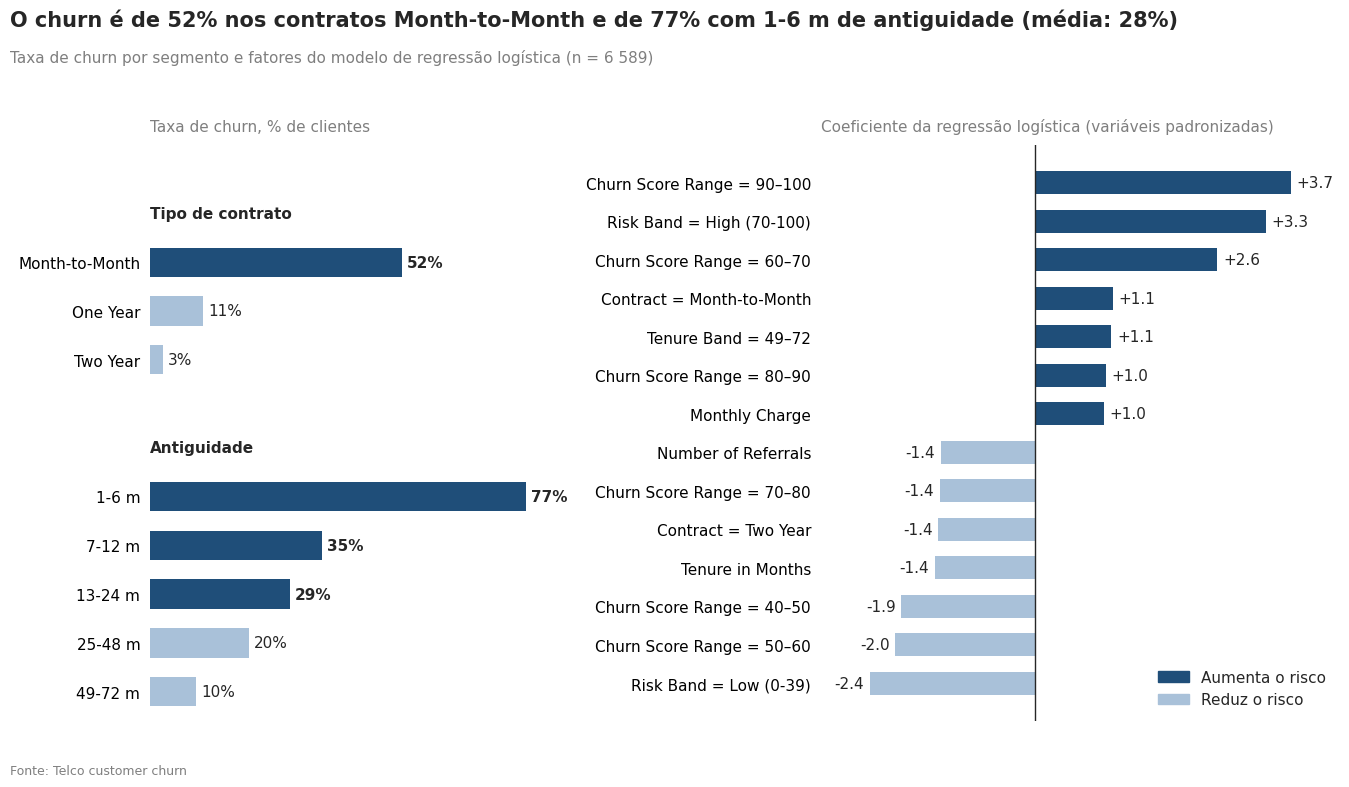

In [ ]:
fig, ax1, ax2 = novo_layout()

# Painel 1: taxa de churn por segmento
for y, rot, v in itens:
    ax1.barh(y, v, height=0.6, color=AZUL if v > media else AZUL_CLARO)
    ax1.text(v + 0.01, y, f"{v:.0%}", va="center", fontweight="bold" if v > media else "normal")
ax1.set_xlim(0, max(v for _, _, v in itens) * 1.15)
eixo_segmentos(ax1, "Taxa de churn, % de clientes")

# Painel 2: coeficientes
ax2.barh(ypos, sel.values, height=0.6, color=[AZUL if v > 0 else AZUL_CLARO for v in sel.values])
for yi, v in zip(ypos, sel.values):
    ax2.text(v + (0.08 if v > 0 else -0.08), yi, f"{v:+.1f}",
             va="center", ha="left" if v > 0 else "right")
ax2.axvline(0, color=TEXTO, lw=1)
ax2.set_yticks(ypos); ax2.set_yticklabels(nomes)
ax2.set_xlim(sel.min() - 0.7, sel.max() + 0.7)
ax2.set_title("Coeficiente da regressão logística (variáveis padronizadas)",
              loc="left", fontsize=11, color=CINZA, pad=10)
ax2.legend(handles=[Patch(color=AZUL, label="Aumenta o risco"),
                    Patch(color=AZUL_CLARO, label="Reduz o risco")],
           frameon=False, loc="lower right")
limpar(ax2)

moldura(fig)
plt.show()

**Como ler o gráfico:** os dois painéis de cima mostram a taxa de churn por contrato e por antiguidade (vermelho = acima da média de 28%). O painel de baixo mostra os fatores com maior peso na regressão logística. Lembre-se de que os sinais de alguns coeficientes (por exemplo, `Fiber Optic` ou `Married`) divergem da análise isolada por causa de variáveis correlacionadas; a mensagem robusta é a dos dois gráficos de cima: **contrato mensal e primeiros meses de vida são os grandes sinais de alerta**.

### Resposta ao Problema 2 — Quais são os clientes com maior risco de churn?

- **Conseguimos identificar os churners no conjunto de teste?** Sim. O modelo vencedor (Gradient Boosting calibrado + FE) atinge PR-AUC **0,884** no teste, contra 0,284 de uma seleção aleatória. Com o limiar de 0,5, identifica 73% dos churners (recall 0,730) com 85,6% de precision.
- **Capacidade de distinguir quem saiu de quem ficou:** ROC-AUC de **0,937** no teste: um churner escolhido ao acaso recebe uma probabilidade superior à de um cliente que ficou em cerca de 94% das vezes (0,5 seria ao acaso).
- **Que modelo tem o melhor desempenho?** Em validação, os dois gradient boosting calibrados lideram (0,872, com ou sem FE); Gradient Boosting (0,864), Gradient Boosting + FE (0,863), Regressão Logística + FE (0,860) e Random Forest + FE (0,856) ficam próximos; a regressão logística sem FE (0,817) e a árvore simples (0,786) ficam claramente atrás. A regressão logística + FE é a alternativa mais simples e explicável, com desempenho próximo.

Assim, o modelo ordena todos os clientes elegíveis por probabilidade de churn, e os de maior probabilidade são os de maior risco.

NameError: name 'COR_DESTAQUE' is not defined

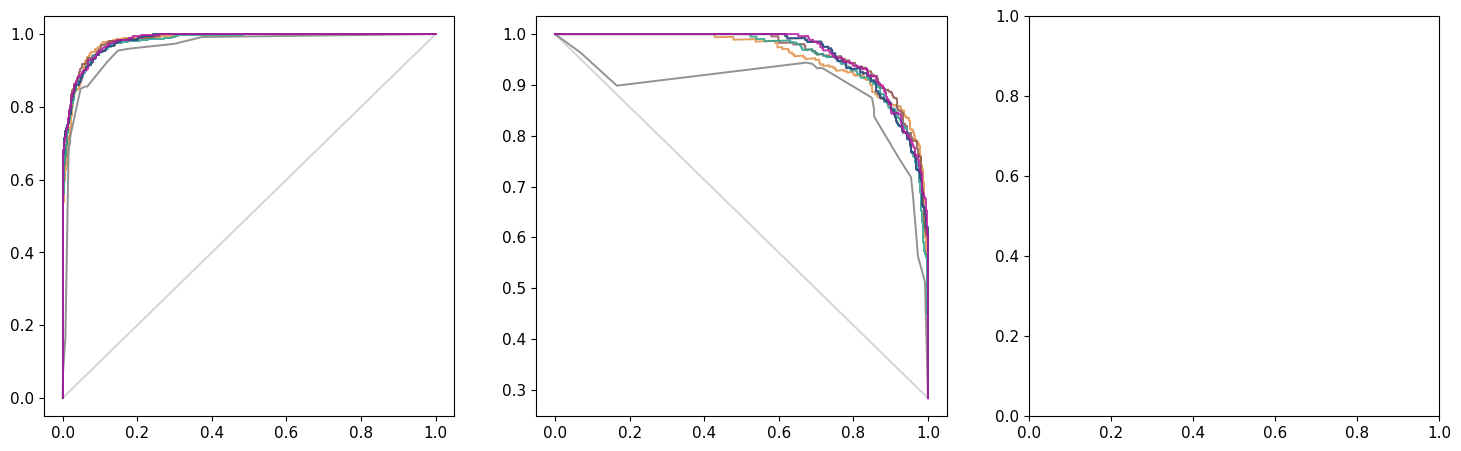

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
paleta = {
    "Baseline (base rate)": "#c9ced3",
    "Logistic Regression": "#e08e45",
    "Logistic Regression + FE": "#8c564b",
    "Decision Tree (depth 5) + FE": "#7f7f7f",
    "Random Forest + FE": "#2a9d8f",
    "Gradient Boosting": "#9a6fb0",
    "Gradient Boosting + FE": "#1f4e79",
    "Gradient Boosting calibrado": "#b5179e",
    "Gradient Boosting calibrado + FE": "#7b2d8e",
}

for name, model in fitted.items():
    Xv = feature_sets[fset_of[name]][1]
    pv = model.predict_proba(Xv)[:, 1]
    ven = name == best
    kw = dict(
        color=COR_DESTAQUE if ven else paleta.get(name, "#999"),
        linewidth=3 if ven else 1.4,
        alpha=1 if ven else 0.85,
        label=name + ("  (vencedor)" if ven else ""),
        zorder=5 if ven else 2,
    )
    fpr, tpr, _ = roc_curve(y_val, pv)
    axes[0].plot(fpr, tpr, **kw)
    prec, rec, _ = precision_recall_curve(y_val, pv)
    axes[1].plot(rec, prec, **kw)

axes[0].plot([0, 1], [0, 1], color=COR_NEUTRA, linestyle="--", linewidth=1)
axes[0].set(
    xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)"
)
axes[0].set_title("Curva ROC (validação)", loc="left", fontweight="bold")
axes[1].axhline(y_val.mean(), color=COR_NEUTRA, linestyle="--", linewidth=1)
axes[1].set(xlabel="Recall", ylabel="Precision")
axes[1].set_title("Curva Precision-Recall (validação)", loc="left", fontweight="bold")
axes[0].legend(fontsize=8, loc="lower right", frameon=False)

# Treino vs validação: sinal de sobreajuste
pv_tab = (
    results[results["dataset"].isin(["train", "validation"])]
    .pivot(index="model", columns="dataset", values="pr_auc")
    .sort_values("validation")
)
y_pos = np.arange(len(pv_tab))
axes[2].barh(
    y_pos + 0.2, pv_tab["train"], height=0.38, color=COR_NEUTRA, label="Treino"
)
axes[2].barh(
    y_pos - 0.2,
    pv_tab["validation"],
    height=0.38,
    color=COR_PRINCIPAL,
    label="Validação",
)
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(pv_tab.index, fontsize=9)
axes[2].set_xlim(0, 1.08)
axes[2].set_title("PR-AUC: treino vs validação", loc="left", fontweight="bold")
axes[2].legend(frameon=False, loc="lower right")
for i, (t, v) in enumerate(zip(pv_tab["train"], pv_tab["validation"])):
    axes[2].text(v + 0.01, i - 0.2, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Como ler o gráfico:** nas curvas ROC e Precision-Recall (calculadas na **validação**, onde foi feita a escolha) a curva do vencedor está a vermelho; as curvas dos seis melhores modelos praticamente sobrepõem-se, e só a regressão logística sem FE (laranja) fica visivelmente abaixo na Precision-Recall. O painel da direita compara o PR-AUC em treino e validação: onde a barra cinzenta é muito maior do que a azul (os quatro gradient boosting e a random forest) há sobreajuste.

### Resposta ao Problema 3 — Quem devemos contactar primeiro?

- **Quantos clientes em risco identificamos com 5%, 10% ou 20% de contactos?** Em 1 318 clientes de teste (374 churners): contactando 66 clientes (5%) apanhamos **66** churners; com 132 (10%) apanhamos **132**; com 264 (20%) apanhamos **235**.
- **Proporção de churners em cada grupo:** **100%**, **100%** e **89,0%**. Em relação ao total de churners, isso equivale a 17,6%, 35,3% e **62,8%** de recall.
- **Comparação com seleção aleatória:** a taxa de churn é de 28,4%, logo, ao acaso, um grupo de 10% teria cerca de 37 churners; o modelo apanha 132, ou seja, um **lift de 3,5×** (3,1× aos 20%). Face ao Churn Score do SPSS há empate técnico (236 vs 235 aos 20%).
- **Ir além da probabilidade:** ordenando por valor esperado (probabilidade × receita média mensal), 78 dos 132 clientes do top 10% mantêm-se, a receita mensal dos churners apanhados sobe 29% (8 456 → 10 870) e o número de churners no grupo desce de 132 para 126.

**Recomendação:** começar pelos 10% de maior risco (taxa de acerto de 100% no teste) e, se houver margem, alargar até 20%. Se o objetivo for maximizar o valor retido e não apenas o número de clientes, usar a lista por valor esperado.

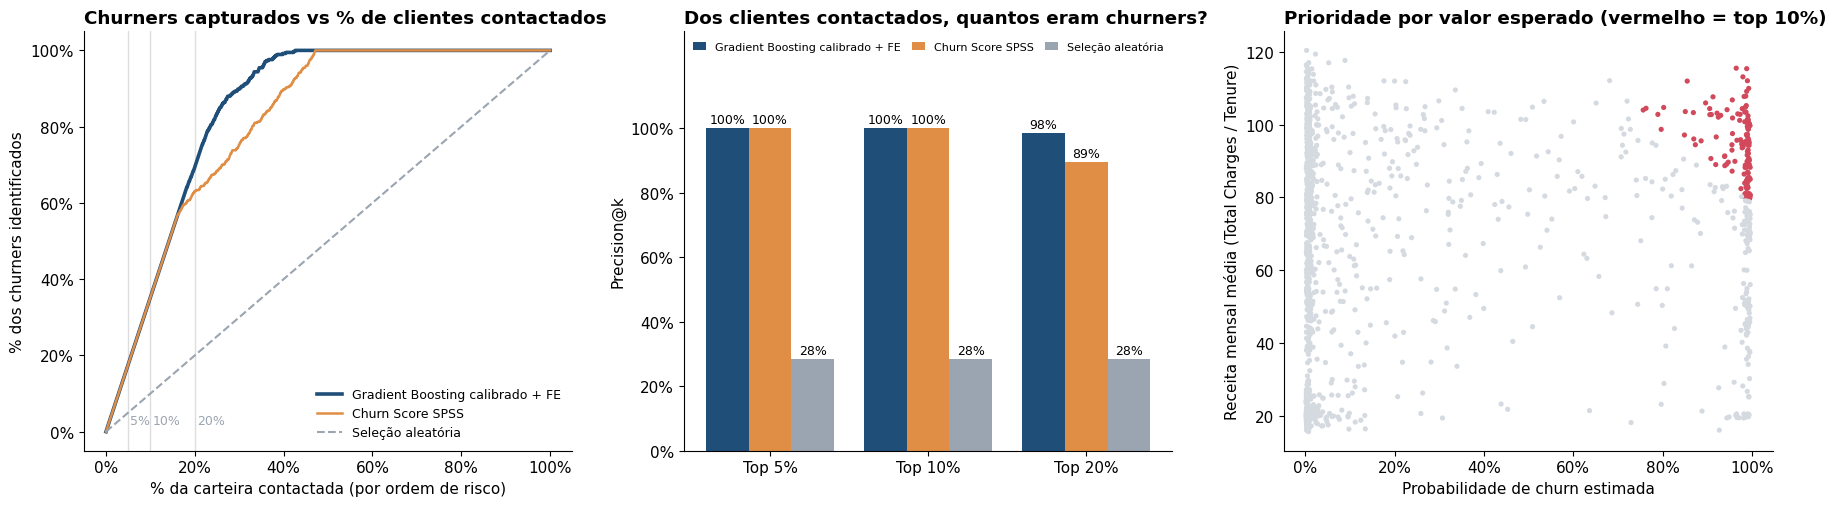

In [ ]:
def gains_curve(y_true, scores):
    d = pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(scores)}).sort_values(
        "s", ascending=False, kind="mergesort"
    )
    x = np.arange(1, len(d) + 1) / len(d)
    return np.insert(x, 0, 0), np.insert(d["y"].cumsum().values / d["y"].sum(), 0, 0)


spss = model_df.loc[X_test.index, "Churn Score"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# 1) Curva de ganhos acumulados
x, g_mod = gains_curve(y_test, p_test)
_, g_spss = gains_curve(y_test, spss)
axes[0].plot(x, g_mod, color=COR_PRINCIPAL, linewidth=2.6, label=f"{best}")
axes[0].plot(x, g_spss, color="#e08e45", linewidth=1.8, label="Churn Score SPSS")
axes[0].plot(
    [0, 1], [0, 1], color=COR_NEUTRA, linestyle="--", label="Seleção aleatória"
)
for f in (0.05, 0.10, 0.20):
    axes[0].axvline(f, color="#dddddd", linewidth=1, zorder=0)
    axes[0].text(f + 0.005, 0.02, f"{int(f*100)}%", color=COR_NEUTRA, fontsize=9)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set(
    xlabel="% da carteira contactada (por ordem de risco)",
    ylabel="% dos churners identificados",
)
axes[0].set_title(
    "Churners capturados vs % de clientes contactados", loc="left", fontweight="bold"
)
axes[0].legend(frameon=False, loc="lower right", fontsize=9)

# 2) Precision@k
tk_m, tk_s = topk_table(y_test, p_test), topk_table(y_test, spss)
base = y_test.mean()
pos = np.arange(3)
axes[1].bar(pos - 0.27, tk_m["Precision@k"], 0.27, color=COR_PRINCIPAL, label=best)
axes[1].bar(pos, tk_s["Precision@k"], 0.27, color="#e08e45", label="Churn Score SPSS")
axes[1].bar(pos + 0.27, [base] * 3, 0.27, color=COR_NEUTRA, label="Seleção aleatória")
for i in range(3):
    axes[1].text(
        i - 0.27,
        tk_m["Precision@k"][i] + 0.015,
        f"{tk_m['Precision@k'][i]:.0%}",
        ha="center",
        fontsize=9,
    )
    axes[1].text(
        i,
        tk_s["Precision@k"][i] + 0.015,
        f"{tk_s['Precision@k'][i]:.0%}",
        ha="center",
        fontsize=9,
    )
    axes[1].text(i + 0.27, base + 0.015, f"{base:.0%}", ha="center", fontsize=9)
axes[1].set_xticks(pos)
axes[1].set_xticklabels(["Top 5%", "Top 10%", "Top 20%"])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_ylim(0, 1.3)
axes[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
axes[1].set(ylabel="Precision@k")
axes[1].set_title(
    "Dos clientes contactados, quantos eram churners?", loc="left", fontweight="bold"
)
axes[1].legend(
    frameon=False,
    fontsize=8,
    loc="upper center",
    ncol=3,
    columnspacing=1.0,
    handlelength=1.2,
)

# 3) Probabilidade vs CLTV: quem entra no top 10% por valor esperado
cores3 = np.where(priorities_ev.index.isin(top_ev), COR_DESTAQUE, "#d5dae0")
axes[2].scatter(
    priorities_ev["Churn Probability"],
    priorities_ev["Receita mensal média"],
    c=cores3,
    s=14,
    edgecolors="none",
)
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[2].set(
    xlabel="Probabilidade de churn estimada",
    ylabel="Receita mensal média (Total Charges / Tenure)",
)
axes[2].set_title(
    "Prioridade por valor esperado (vermelho = top 10%)", loc="left", fontweight="bold"
)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

AZUL, AZUL_CLARO, CINZA, TEXTO = "#1f4e79", "#a9c1d9", "#7f7f7f", "#262626"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11, "text.color": TEXTO})


# ---------- Probabilidades de churn ----------
proba = modelo.predict_proba(X_test)[:, 1]

# ---------- Receita média mensal ----------
receita_media = df.loc[X_test.index, "Total Charges"] / df.loc[X_test.index, "Tenure"]
# ---------- Dados ----------
# Substitui pelas variáveis que já usas no gráfico original
d = pd.DataFrame({
    "prob": proba,              # probabilidade de churn estimada (0 a 1)
    "receita": receita_media,   # Total Charges / Tenure
})
d["valor"] = d["prob"] * d["receita"]       # valor esperado em risco (mensal)

TOP_PCT = 0.05                              # ajusta ao critério do teu gráfico original
limiar = d["valor"].quantile(1 - TOP_PCT)
d["top"] = d["valor"] >= limiar

n_total = len(d)
n_top = int(d["top"].sum())
share_top = d.loc[d["top"], "valor"].sum() / d["valor"].sum()

# ---------- Estilo IBCS ----------
def moldura(fig, titulo, subtitulo, fonte="Fonte: Telco customer churn"):
    fig.text(0.02, 0.97, titulo, fontsize=15, fontweight="bold", ha="left", va="top")
    fig.text(0.02, 0.905, subtitulo, fontsize=11, color=CINZA, ha="left", va="top")
    fig.text(0.02, 0.01, fonte, fontsize=9, color=CINZA, ha="left", va="bottom")

def limpar(ax, manter_y=False, manter_x=False):
    for s in ["top", "right", "left", "bottom"]:
        ax.spines[s].set_visible(False)
    if manter_y:
        ax.spines["left"].set_visible(True); ax.spines["left"].set_color(TEXTO)
    if manter_x:
        ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color(TEXTO)
    ax.grid(False)

titulo_base = (f"{n_top} clientes ({TOP_PCT:.0%}) concentram {share_top:.0%} "
               f"do valor esperado em risco")

AttributeError: 'DataFrame' object has no attribute 'predict_proba'

IndexError: invalid index to scalar variable.

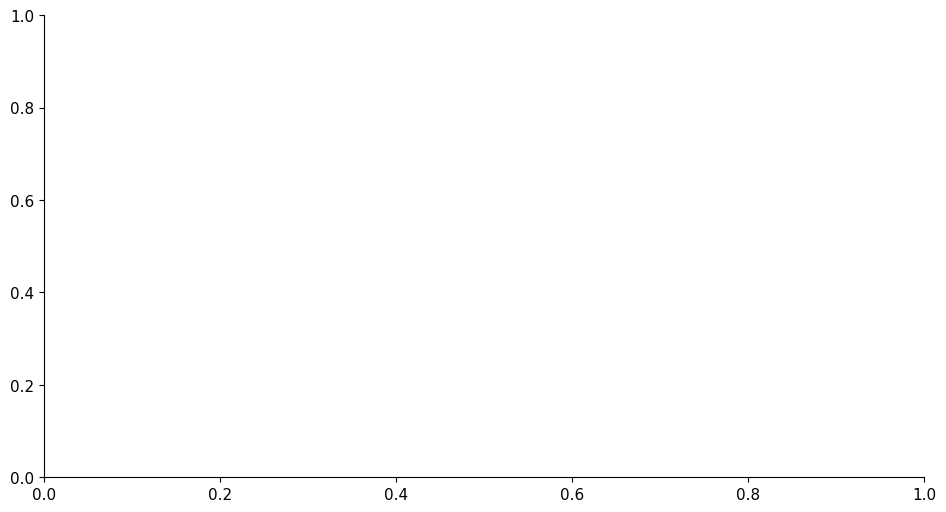

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.09, right=0.97)

rest, top = d[~d["top"]], d[d["top"]]
ax.scatter(rest["prob"], rest["receita"], s=14, color=AZUL_CLARO, alpha=0.6, linewidths=0)
ax.scatter(top["prob"], top["receita"], s=22, color=AZUL, linewidths=0)

ax.annotate(f"Top {TOP_PCT:.0%} por valor esperado\n(n = {n_top})",
            xy=(top["prob"].median(), top["receita"].max()),
            xytext=(0.38, d["receita"].max() * 0.97),
            fontsize=11, fontweight="bold", color=AZUL, va="center",
            arrowprops=dict(arrowstyle="-", color=AZUL, lw=1))

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Probabilidade de churn estimada", color=CINZA)
ax.set_ylabel("Receita mensal média", color=CINZA)
ax.tick_params(colors=CINZA, length=3)
limpar(ax, manter_y=True, manter_x=True)

moldura(fig, titulo_base,
        f"Clientes por probabilidade de churn e receita mensal média (n = {n_total:,})".replace(",", " "))
plt.show()

In [ ]:
v = d["valor"].sort_values(ascending=False).to_numpy()
x = np.arange(1, len(v) + 1) / len(v)
y = np.cumsum(v) / v.sum()

fig, ax = plt.subplots(figsize=(10, 6.5))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.09, right=0.95)

ax.plot([0, 1], [0, 1], color=CINZA, ls="--", lw=1)             # distribuição uniforme
ax.text(0.62, 0.55, "Se todos os clientes\nvalessem o mesmo", color=CINZA, fontsize=9, ha="left")

ax.fill_between(x, y, color=AZUL_CLARO, alpha=0.5)
ax.plot(x, y, color=AZUL, lw=2.5)
ax.plot(TOP_PCT, share_top, "o", ms=9, color=AZUL)
ax.annotate(f"{TOP_PCT:.0%} dos clientes\n= {share_top:.0%} do valor",
            xy=(TOP_PCT, share_top), xytext=(TOP_PCT + 0.08, share_top - 0.12),
            fontsize=11, fontweight="bold", color=AZUL,
            arrowprops=dict(arrowstyle="-", color=AZUL, lw=1))

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("% de clientes (ordenados por valor esperado, do maior para o menor)", color=CINZA)
ax.set_ylabel("% acumulada do valor esperado", color=CINZA)
ax.tick_params(colors=CINZA, length=3)
limpar(ax, manter_y=True, manter_x=True)

moldura(fig, titulo_base, "Curva de concentração do valor esperado em risco (valor = probabilidade × receita mensal)")
plt.show()

In [ ]:
bins = [0, .2, .4, .6, .8, 1.0001]
labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
faixa = pd.cut(d["prob"], bins=bins, right=False, labels=labels)

pct_cli = faixa.value_counts(normalize=True).reindex(labels)
pct_val = d.groupby(faixa, observed=False)["valor"].sum().reindex(labels) / d["valor"].sum()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
fig.subplots_adjust(top=0.76, bottom=0.10, left=0.10, right=0.97, wspace=0.08)

ypos = np.arange(len(labels))
cores = [AZUL if l == labels[-1] else AZUL_CLARO for l in labels]
xmax = max(pct_cli.max(), pct_val.max()) * 1.2          # mesma escala nos dois painéis

for ax, serie, nome in [(a1, pct_cli, "% de clientes"), (a2, pct_val, "% do valor esperado em risco")]:
    ax.barh(ypos, serie.values, height=0.6, color=cores)
    for yi, val, l in zip(ypos, serie.values, labels):
        ax.text(val + xmax * 0.015, yi, f"{val:.0%}", va="center",
                fontweight="bold" if l == labels[-1] else "normal")
    ax.set_xlim(0, xmax)
    ax.set_xticks([])
    ax.set_title(nome, loc="left", fontsize=11, color=CINZA, pad=10)
    limpar(ax, manter_y=(ax is a1))

a1.set_yticks(ypos); a1.set_yticklabels(labels)
a1.set_ylabel("Probabilidade de churn estimada", color=CINZA)
a2.tick_params(left=False)

moldura(fig,
        f"{pct_cli.iloc[-1]:.0%} dos clientes estão na faixa 80–100% de risco e concentram {pct_val.iloc[-1]:.0%} do valor esperado",
        f"Distribuição por faixa de probabilidade de churn (n = {n_total:,})".replace(",", " "))
plt.show()

NameError: name 'd' is not defined

**Como ler o gráfico:** à esquerda, a curva do modelo (azul) sobe quase em linha reta nos primeiros 10% da carteira, ou seja, quase só encontra churners, e fica sempre muito acima da seleção aleatória (cinzento tracejado); a curva do Churn Score do SPSS (laranja) é praticamente igual. No centro, a precision em cada nível de contacto: 100%, 100% e 89%, contra 28% ao acaso. À direita, cada ponto é um cliente de teste; o eixo vertical é a receita média mensal e os vermelhos são o top 10% por valor esperado: têm probabilidade alta **e** pagam mais por mês.